# MVP-3 Phase 2 — Ilha Grande Multi-Date Statistical Profiling
**Consolidated workflow notebook.** Rebuilt from the working session to remove abandoned attempts, one-off debug snippets, and duplicated date-setting lines that had accumulated across many edits.

**Terminology rule (non-negotiable in every output):** results describe *"floating marine-debris/macroplastic aggregation candidates"* — never *"plastic identification."* No ground truth exists at this AOI; sensor agreement indicates a genuine optical surface anomaly, not confirmed plastic.

**Notebook structure:**
- **Part 1 — Setup & configuration** (Cells 1-4)
- **Part 2 — Core pipeline function definitions** (Cells 5-8): S2, CBERS, SGLI, background control
- **Part 3 — Sentinel-2 real FDI + CBERS fast sampling** (Cells 9-11)
- **Part 4 — Phase 2 statistical layer** (Cells 12-15): reflectance de-glint, bootstrap/AUC, FDI-strength bands, raster-based land/cloud/other adjacency, the fixed dland>=500m open-water rule
- **Part 5 — Scene-selection utility** (Cell 16): the only validated method for picking a CBERS scene for a new date - two earlier approaches failed and are kept in the Archive for the record
- **Part 6 — Per-date run log**: each confirmed date as four short calls, with recorded outputs where a clean 1:1 original run exists (noted where not)
- **Archive**: superseded code kept for provenance, not part of the active workflow

---
## Part 1 - Setup & configuration

### Cell 1 - Mount Google Drive

In [1]:
from google.colab import drive
drive.mount('/content/drive', force_remount=False)


Mounted at /content/drive


### Cell 2 - Install dependencies (pystac-client, cartopy)
Used by the CBERS STAC search and the archived map figures.

In [2]:
pip install pystac_client --q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.8/41.8 kB 686.0 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 117.3/117.3 kB 1.8 MB/s eta 0:00:00


In [3]:
pip install cartopy --q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 24.5 MB/s eta 0:00:00


### Cell 3 - Reference points (for figures/orientation)

In [4]:
REFERENCE_POINTS = {
    "Angra dos Reis": (-44.3136, -23.0117),
    "Ilha Grande": (-44.2330, -23.1500),
    "Paraty": (-44.7150, -23.2178),
    "Mangaratiba": (-44.0400, -22.9600),
}

### Cell 4 - Configuration: AOI, dates, thresholds, logging/timer helpers
S2_DATE/CBERS_DATE/SGLI_FILE here are defaults for a from-scratch run; each per-date cell in Part 6 sets them explicitly before running - don't rely on the values below once Part 6 starts.

In [5]:
"""
Gate B — Composite floating-debris/macroplastic aggregation index
MVP-2: Baia da Ilha Grande / Mosaico Bocaina, RJ, Brazil
Date triple: S2 2024-09-09 / CBERS 2024-09-09 / SGLI 2024-09-09 (same-day triple)

Terminology reminder (project rule, carried forward):
  Use "floating marine-debris/macroplastic aggregation candidates" in every
  print/plot/report. NEVER "plastic identification" — sensor agreement on
  an anomaly does not confirm it is plastic vs. foam, glint, or wave state.
  No ground truth exists at any AOI so far.

Pipeline
--------
1. S2 baseline: NIR-Red contrast, top-1% / 97th-99th percentile threshold
   -> near-threshold candidate set + random background-water control set.
2. CBERS corroboration: NIR-Blue contrast, radiometrically calibrated
   (DN -> TOA radiance -> TOA reflectance), background-rate control test.
3. SGLI corroboration: NWLR_670 - NWLR_443 contrast (visible-only proxy,
   no NIR band available), QA-masked, KDTree-matched to S2 points within
   ~300m, background-rate control test.
4. Report: near-threshold rate vs. background rate, gap, sample size (n),
   for each corroboration layer — state plainly if n is too small to trust.

Run in Colab. Requires: earthengine-api, pystac-client, h5py, scipy,
rasterio, pyproj, requests.
"""

import ee
import numpy as np
import requests
import xml.etree.ElementTree as ET
import h5py
from scipy.ndimage import zoom
from scipy.spatial import cKDTree
import rasterio
from rasterio.warp import transform as warp_transform
import pystac_client
import math
import datetime as dt
import time
import gc


def hb(msg):
    """Heartbeat log with timestamp — per the project's own engineering
    lesson: always print progress with timestamps rather than letting a
    long cell run silently, so a hang or silent bug is visible immediately
    rather than three cells downstream."""
    print(f"[{dt.datetime.now().strftime('%H:%M:%S')}] {msg}")


class ProgressTimer:
    """Tracks elapsed time and estimated-time-remaining for an iterative
    loop with a known total (e.g. the S2 tile loop) — the only part of
    this pipeline where per-unit cost is roughly constant, so the ETA is
    actually meaningful rather than a guess."""
    def __init__(self, total_units, label):
        self.total = total_units
        self.label = label
        self.start = time.time()
        self.n_done = 0

    def update(self, n_done):
        self.n_done = n_done
        elapsed = time.time() - self.start
        rate = elapsed / self.n_done if self.n_done else None
        remaining = (self.total - self.n_done) * rate if rate else None
        eta_str = f"{remaining:.0f}s (~{remaining/60:.1f} min)" if remaining is not None else "n/a"
        pct = 100 * self.n_done / self.total if self.total else 0
        hb(f"[{self.label}] {self.n_done}/{self.total} ({pct:.0f}%) — "
           f"elapsed {elapsed:.0f}s, estimated remaining {eta_str}")


class PipelineTimer:
    """Stage-level elapsed time + a rough total-pipeline ETA. The ETA is
    a simple avg-stage-time x remaining-stages estimate — approximate
    only, since S2/CBERS/SGLI have very different costs, but it directly
    answers 'how much longer is this whole thing going to take.'"""
    def __init__(self, n_stages):
        self.start = time.time()
        self.n_stages = n_stages
        self.stage_start = self.start
        self.stage_num = 0
        self.stage_durations = []

    def stage_begin(self, name):
        self.stage_num += 1
        self.stage_start = time.time()
        elapsed = self.stage_start - self.start
        hb(f"=== Stage {self.stage_num}/{self.n_stages}: {name} — starting "
           f"(total elapsed so far: {elapsed:.0f}s) ===")

    def stage_end(self):
        dur = time.time() - self.stage_start
        self.stage_durations.append(dur)
        avg = sum(self.stage_durations) / len(self.stage_durations)
        remaining_stages = self.n_stages - self.stage_num
        rough_eta = avg * remaining_stages
        total_elapsed = time.time() - self.start
        hb(f"[timer] stage {self.stage_num} took {dur:.0f}s. "
           f"Total elapsed: {total_elapsed:.0f}s ({total_elapsed/60:.1f} min). "
           f"Rough ETA to finish (~{rough_eta:.0f}s, {remaining_stages} stage(s) "
           f"left) — approximate only, stages differ a lot in cost.")

    def finish(self):
        total = time.time() - self.start
        hb(f"=== Pipeline complete — total time: {total:.0f}s ({total/60:.1f} min) ===")

# ---------------------------------------------------------------------------
# Config
# ---------------------------------------------------------------------------
EE_PROJECT = "marplastdetection"
AOI = {"min_lon": -44.65, "max_lon": -44.05, "min_lat": -23.35, "max_lat": -22.90}

S2_DATE = "2024-09-09"
CBERS_DATE = "2024-09-09"
SGLI_FILE = "/content/drive/MyDrive/Marine_Plastic_Detection/notebooks/Japan_check_MVP2_16set26/GC1SG1_202409091246C27414_L2SG_NWLRK_3002.h5"

S2_TOP_PCT = 99          # near-threshold = top 1%
S2_LOWER_PCT_FOR_BG = 50 # background-water control drawn below this percentile
N_BACKGROUND_SAMPLES = 20000  # random control sample size (>= near-threshold set, ideally)

SGLI_MATCH_TOLERANCE_M = 300  # per prior MVP's SGLI alignment lesson

ESUN = {"Blue": 1984.65, "NIR": 981.91}  # CBERS-4A WPM, Thuillier 2003 (W/m^2/um)


**Cache check** - confirms Drive-cached files survive a kernel restart before paying to rebuild anything.

In [6]:
import os
print(sorted(os.listdir("/content/drive/MyDrive/Marine_Plastic_Detection/cache")))

['cbers_window_CBERS_4A_WPM_20240110_199_142_L4_2024-01-10.pkl', 'cbers_window_CBERS_4A_WPM_20240205_200_142_L4_2024-02-05.pkl', 'cbers_window_CBERS_4A_WPM_20240205_200_143_L4_2024-02-05.pkl', 'cbers_window_CBERS_4A_WPM_20240210_199_142_L4_2024-02-10.pkl', 'cbers_window_CBERS_4A_WPM_20240508_200_142_L4_2024-05-08.pkl', 'cbers_window_CBERS_4A_WPM_20240608_200_142_L4_2024-06-08.pkl', 'cbers_window_CBERS_4A_WPM_20240608_200_143_L4_2024-06-08.pkl', 'cbers_window_CBERS_4A_WPM_20240613_199_142_L4_2024-06-13.pkl', 'cbers_window_CBERS_4A_WPM_20240809_200_142_L4_2024-08-09.pkl', 'cbers_window_CBERS_4A_WPM_20240909_200_142_L4_2024-09-09.pkl', 'cbers_window_CBERS_4A_WPM_20240914_199_142_L4_2024-09-14.pkl', 's2_fdi_2024-01-11.pkl', 's2_fdi_2024-02-05.pkl', 's2_fdi_2024-02-10.pkl', 's2_fdi_2024-05-07.pkl', 's2_fdi_2024-08-08.pkl', 's2_fdi_2024-09-09.pkl', 's2_fdi_2024-09-12.pkl', 's2_fdi_2024-09-14.pkl', 's2_raster_2024-02-05.npz', 's2_raster_2024-05-07.npz', 's2_raster_2024-08-08.npz', 's2_raster_

---
## Part 2 - Core pipeline function definitions
Run once per session (fast - no network cost). Shared by every date in Part 6.

### Cell 5 - Sentinel-2: EE init, tiling, candidate/background split
build_near_threshold_and_background is reused unchanged for both the proxy contrast and the real FDI array.

In [7]:
def init_ee():
    ee.Authenticate()
    ee.Initialize(project=EE_PROJECT)
    print(f"[EE] Initialized on project: {EE_PROJECT}")


def aoi_ee_geometry():
    return ee.Geometry.Rectangle(
        [AOI["min_lon"], AOI["min_lat"], AOI["max_lon"], AOI["max_lat"]]
    )


# ---------------------------------------------------------------------------
# 1. Sentinel-2 baseline
# ---------------------------------------------------------------------------
def get_s2_contrast_array(date):
    hb(f"[S2] fetching scene(s) for {date}")
    aoi = aoi_ee_geometry()
    coll = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(date, (dt.date.fromisoformat(date) + dt.timedelta(days=1)).isoformat())
    )
    n_images = coll.size().getInfo()
    hb(f"[S2] {n_images} S2 granule(s) intersect the AOI on {date} — mosaicking "
       f"so the full AOI is covered even if it spans a granule boundary")
    assert n_images > 0, f"[S2] No S2 images found for {date}"
    img = coll.mosaic()  # merge granules — .first() left southern/eastern parts
                          # of this AOI outside a single granule's footprint

    nodata_mask = img.select("B4").neq(0).And(img.select("B8").neq(0))

    # Water mask — use Sentinel-2's own Scene Classification Layer (SCL)
    # rather than a hand-picked NDWI threshold (SCL class 6 = water, ESA's
    # own multi-band classifier, robust to turbidity in a way a single
    # index threshold isn't).
    #
    # CRITICAL: force this explicitly onto the S2 10m projection with
    # .reproject(). Without this, combining SCL (native 20m) with the 10m
    # nodata_mask via .And() can silently fall back to Earth Engine's
    # default coarse projection for the composite — collapsing what should
    # be a real ~50km2 bay's worth of water pixels down to a tiny handful.
    # This is the same class of bug as the earlier pixelLonLat() default-
    # projection issue that caused the IndexError a few fixes ago — two
    # different mask formulas (NDWI, now SCL) both landing on the exact
    # same suspiciously-small count (117) is the signature of this bug,
    # not a coincidence of two real results agreeing.
    TARGET_CRS = "EPSG:32723"
    TARGET_SCALE = 10
    s2_proj = ee.Projection(TARGET_CRS)
    water_mask = img.select("SCL").eq(6).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)
    combined_mask = nodata_mask.And(water_mask).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)
    img = img.updateMask(combined_mask)
    hb(f"[S2] applied SCL water mask (class 6), reprojected onto canonical "
       f"{TARGET_CRS} at {TARGET_SCALE}m — on top of nodata mask")

    # Quick sanity check BEFORE launching the full 143-tile loop — a coarse
    # server-side count at 30m, not the full 10m tiling pass, so a bad mask
    # is caught in seconds rather than after another multi-minute run.
    aoi_geom = aoi_ee_geometry()
    check_count = (
        combined_mask.selfMask()
        .reduceRegion(reducer=ee.Reducer.count(), geometry=aoi_geom, scale=30,
                      maxPixels=1e9, bestEffort=True)
        .getInfo()
    )
    n_check = list(check_count.values())[0] if check_count else 0
    hb(f"[S2] quick mask sanity check (30m, coarse): ~{n_check} water pixels in AOI "
       f"before full-resolution tiling — if this looks implausibly small "
       f"(a ~50km2 bay should show thousands+), stop and investigate before "
       f"running the full tile loop")

    contrast = img.normalizedDifference(["B8", "B4"]).rename("contrast")
    contrast_filled = contrast.unmask(-9999)

    # Force the coordinate bands onto the SAME projection/scale as the S2 data
    # band before sampling. pixelLonLat() defaults to its own projection,
    # which differs from S2's native 10m UTM grid — sampling mismatched-
    # projection bands with sampleRectangle silently returns DIFFERENT array
    # shapes per band. That mismatch is what caused the final IndexError.

    # Combine bands FIRST, then reproject the whole stack together in one
    # call. Reprojecting pixelLonLat() separately before combining (the
    # previous attempt) doesn't reliably propagate scale — it silently
    # returned 1x1 coordinate arrays against a correctly-sized contrast
    # array. Reprojecting the combined image forces every band onto the
    # identical output grid.
    stack = contrast_filled.addBands(ee.Image.pixelLonLat()).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)

    # --- Tiling: sampleRectangle has a hard 512x512 (262,144) pixel limit
    # per call. At S2's native 10m resolution, this AOI (~61km x 50km) is
    # ~30M pixels — far too large for one call. Split into sub-rectangles
    # that each stay safely under the limit, sample each, and concatenate.
    # This preserves full native resolution rather than downsampling.
    S2_SCALE_M = 10
    TILE_PX = 480  # safety margin under the 512 hard limit
    lat0 = (AOI["min_lat"] + AOI["max_lat"]) / 2
    m_per_deg_lat = 111320
    m_per_deg_lon = 111320 * math.cos(math.radians(lat0))
    tile_deg_lat = TILE_PX * S2_SCALE_M / m_per_deg_lat
    tile_deg_lon = TILE_PX * S2_SCALE_M / m_per_deg_lon

    lon_edges = np.arange(AOI["min_lon"], AOI["max_lon"], tile_deg_lon)
    lat_edges = np.arange(AOI["min_lat"], AOI["max_lat"], tile_deg_lat)
    n_tiles = len(lon_edges) * len(lat_edges)
    hb(f"[S2] tiling AOI into {len(lon_edges)}x{len(lat_edges)} = {n_tiles} tiles "
       f"(~{TILE_PX}px each, {S2_SCALE_M}m native resolution) to respect the "
       f"sampleRectangle 512x512 pixel limit")

    all_lon, all_lat, all_val = [], [], []
    done = 0
    tile_timer = ProgressTimer(n_tiles, "S2 tiling")
    for lo in lon_edges:
        for la in lat_edges:
            tile_region = ee.Geometry.Rectangle([
                lo, la,
                min(lo + tile_deg_lon, AOI["max_lon"]),
                min(la + tile_deg_lat, AOI["max_lat"]),
            ])
            try:
                sampled = stack.sampleRectangle(region=tile_region)
                info = sampled.getInfo()  # ONE round trip instead of 3 —
                                           # cuts network calls per tile by 3x
                props = info["properties"]
                t_lon = np.array(props["longitude"], dtype=np.float32)
                t_lat = np.array(props["latitude"], dtype=np.float32)
                t_val = np.array(props["contrast"], dtype=np.float32)
                if not (t_lon.shape == t_lat.shape == t_val.shape):
                    print(f"  [WARN] tile at ({lo:.4f},{la:.4f}) shape mismatch — "
                          f"lon{t_lon.shape} lat{t_lat.shape} val{t_val.shape} — skipping tile")
                else:
                    all_lon.append(t_lon.ravel())
                    all_lat.append(t_lat.ravel())
                    all_val.append(t_val.ravel())
            except Exception as e:
                print(f"  [WARN] tile at ({lo:.4f},{la:.4f}) failed: {e}")
            done += 1
            if done % 10 == 0 or done == n_tiles:
                tile_timer.update(done)

    lon = np.concatenate(all_lon) if all_lon else np.array([])
    lat = np.concatenate(all_lat) if all_lat else np.array([])
    val = np.concatenate(all_val) if all_val else np.array([])

    valid = val != -9999
    n_valid = int(valid.sum())
    hb(f"[S2] {n_valid} valid contrast pixels pulled for {date} across {n_tiles} tiles")
    assert n_valid > 0, f"[S2] Zero valid pixels for {date} — check nodata masking and date."
    return lon[valid], lat[valid], val[valid]



def build_near_threshold_and_background(lon, lat, val):
    p_top = np.percentile(val, S2_TOP_PCT)
    p_bg_upper = np.percentile(val, S2_LOWER_PCT_FOR_BG)

    near_mask = val >= p_top
    bg_pool_mask = val <= p_bg_upper

    near_pts = np.column_stack([lon[near_mask], lat[near_mask]])
    bg_pool_pts = np.column_stack([lon[bg_pool_mask], lat[bg_pool_mask]])

    rng = np.random.default_rng(42)
    n_bg = min(N_BACKGROUND_SAMPLES, len(bg_pool_pts))
    bg_idx = rng.choice(len(bg_pool_pts), size=n_bg, replace=False)
    bg_pts = bg_pool_pts[bg_idx]

    print(f"[S2] near-threshold (top {100 - S2_TOP_PCT}%): {len(near_pts)} points")
    print(f"[S2] background-water control: {len(bg_pts)} points (random, <= p{S2_LOWER_PCT_FOR_BG})")
    assert len(near_pts) > 0, "[S2] Zero near-threshold points — check S2_TOP_PCT / input data."
    assert len(bg_pts) > 0, "[S2] Zero background-control points — check pool size."
    return near_pts, bg_pts


### Cell 6 - CBERS-4A/WPM: STAC search (single-date), radiometric calibration
find_cbers_items(date) only checks whether a scene intersects the AOI at all - it does NOT confirm real pixel coverage (see Part 5). Kept here because parse_calib_xml/dn_to_reflectance are used everywhere downstream. The original per-point sampler (sample_cbers_contrast_at_points) is superseded by the bulk-window version in Part 3 and is not used in Part 6.

In [8]:
# ---------------------------------------------------------------------------
# 2. CBERS-4A/WPM — calibration + point-sampling at S2 point locations
# ---------------------------------------------------------------------------
def find_cbers_items(date):
    hb(f"[CBERS] searching STAC for {date}")
    catalog = pystac_client.Client.open("https://data.inpe.br/bdc/stac/v1/")
    collections = [c.id for c in catalog.get_collections()]
    wpm_id = next(c for c in collections if "WPM" in c.upper())
    aoi_geojson = {
        "type": "Polygon",
        "coordinates": [[
            [AOI["min_lon"], AOI["min_lat"]], [AOI["max_lon"], AOI["min_lat"]],
            [AOI["max_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["max_lat"]],
            [AOI["min_lon"], AOI["min_lat"]],
        ]],
    }
    search = catalog.search(
        collections=[wpm_id],
        intersects=aoi_geojson,
        datetime=f"{date}T00:00:00Z/{date}T23:59:59Z",
    )
    items = list(search.items())
    if not items:
        raise RuntimeError(f"No CBERS item found for {date}")
    hb(f"[CBERS] found {len(items)} item(s) intersecting AOI: {[it.id for it in items]} — "
       f"a single scene may not fully cover this AOI, same issue as S2 granule boundaries")
    return items


def strip_namespace(elem):
    """This CBERS XML declares a default namespace, which makes
    ElementTree internally rename every tag to '{namespace}tag' — so a
    bare search for 'band' matches nothing (hence the empty [] seen
    earlier), not a wrong-name-format issue. Strip it so plain tag
    names work as written in the project's own documentation."""
    for el in elem.iter():
        if isinstance(el.tag, str) and "}" in el.tag:
            el.tag = el.tag.split("}", 1)[1]
    return elem


def parse_calib_xml(xml_url, band_n):
    resp = requests.get(xml_url)
    root = ET.fromstring(resp.content)
    root = strip_namespace(root)

    # Scope the search to THIS specific section — the document also has
    # <band> elements under <availableBands> and <gain> (hex gain codes,
    # not calibration values); searching the whole doc risked matching
    # the wrong one.
    cal_section = root.find(".//absoluteCalibrationCoefficient")
    if cal_section is None:
        top_level_tags = [child.tag for child in root]
        raise RuntimeError(
            f"[CBERS calib] No <absoluteCalibrationCoefficient> section found "
            f"in {xml_url}. Top-level tags present: {top_level_tags}."
        )

    tried_names = [str(band_n), f"{band_n:02d}", f"BAND{band_n}", f"B{band_n}"]
    abscal = None
    for band in cal_section.findall("band"):
        if band.attrib.get("name") in tried_names:
            abscal = float(band.text)
            break

    if abscal is None:
        found_names = [b.attrib.get("name") for b in cal_section.findall("band")]
        raise RuntimeError(
            f"[CBERS calib] No coefficient for band {band_n}. Names found "
            f"inside <absoluteCalibrationCoefficient>: {found_names}."
        )

    elev_el = root.find(".//sunPosition/elevation")
    if elev_el is None:
        raise RuntimeError(f"[CBERS calib] No sunPosition/elevation found in {xml_url}")
    sun_elev = float(elev_el.text)

    return abscal, sun_elev

def dn_to_reflectance(dn, abscal, sun_elev, esun, doy):
    L = dn * abscal  # TOA radiance
    theta = math.radians(90 - sun_elev)
    d2 = 1 / (1 + 0.033 * math.cos(2 * math.pi * doy / 365))
    R = (math.pi * L * d2) / (esun * math.cos(theta))
    return R




def sample_cbers_contrast_at_points(items, points_lonlat, date):
    """Handles multiple CBERS items — a single scene may not cover the
    whole AOI (same class of bug as the S2 granule-boundary issue). Each
    point is assigned to the first item whose raster footprint actually
    contains it; batched per-item rather than per-point for speed."""
    hb(f"[CBERS] calibrating and sampling {len(points_lonlat)} points "
       f"across {len(items)} item(s) for {date}")
    t_func_start = time.time()
    doy = dt.date.fromisoformat(date).timetuple().tm_yday

    n = len(points_lonlat)
    results = [None] * n
    assigned = np.zeros(n, dtype=bool)
    lons = np.array([p[0] for p in points_lonlat])
    lats = np.array([p[1] for p in points_lonlat])

    item_timer = ProgressTimer(len(items), "CBERS items")

    for item_num, item in enumerate(items, start=1):
        if assigned.all():
            hb(f"[CBERS] all {n} points already assigned — skipping remaining items")
            break

        t0 = time.time()
        blue_href = item.assets["BAND1"].href
        nir_href = item.assets["BAND4"].href
        blue_xml = item.assets["BAND1_xml"].href
        nir_xml = item.assets["BAND4_xml"].href
        abscal_blue, sun_elev = parse_calib_xml(blue_xml, 1)
        abscal_nir, _ = parse_calib_xml(nir_xml, 4)

        with rasterio.open(blue_href) as blue_ds, rasterio.open(nir_href) as nir_ds:
            xs, ys = warp_transform("EPSG:4326", blue_ds.crs, lons.tolist(), lats.tolist())
            xs, ys = np.array(xs), np.array(ys)
            b = blue_ds.bounds
            in_bounds = (xs >= b.left) & (xs <= b.right) & (ys >= b.bottom) & (ys <= b.top)
            todo_idx = np.where(in_bounds & (~assigned))[0]

            if len(todo_idx) == 0:
                hb(f"[CBERS] item {item.id}: 0 new points in bounds — skipping "
                   f"({time.time() - t0:.1f}s)")
                item_timer.update(item_num)
                continue

            pts = list(zip(xs[todo_idx], ys[todo_idx]))
            blue_dn = list(blue_ds.sample(pts))
            nir_dn = list(nir_ds.sample(pts))

            n_valid_here = 0
            for local_i, idx in enumerate(todo_idx):
                b_dn, n_dn = blue_dn[local_i][0], nir_dn[local_i][0]
                assigned[idx] = True  # in-bounds = assigned to this item, even if nodata
                if b_dn == 0 or n_dn == 0:
                    continue
                r_blue = dn_to_reflectance(b_dn, abscal_blue, sun_elev, ESUN["Blue"], doy)
                r_nir = dn_to_reflectance(n_dn, abscal_nir, sun_elev, ESUN["NIR"], doy)
                results[idx] = r_nir - r_blue
                n_valid_here += 1

        hb(f"[CBERS] item {item.id}: {len(todo_idx)} points in bounds, "
           f"{n_valid_here} valid ({time.time() - t0:.1f}s)")
        item_timer.update(item_num)

    n_valid = sum(r is not None for r in results)
    n_unmatched = n - int(assigned.sum())
    hb(f"[CBERS] sampling complete in {time.time() - t_func_start:.1f}s — "
       f"{n_valid}/{n} valid, {n_unmatched} points fell outside ALL "
       f"{len(items)} item(s)' footprints")
    return results


### Cell 7 - SGLI: windowed full-res interpolation, QA mask, KDTree match
load_sgli_contrast_grid here is the original visible-band contrast reader (superseded by the citation-corrected BSI version in the Archive). match_sgli_to_points is reused as-is by Part 4's analyze_sgli.

In [9]:
# ---------------------------------------------------------------------------
# 3. SGLI — full-res interpolation, QA mask, KDTree match, contrast
# ---------------------------------------------------------------------------
def load_sgli_contrast_grid(filepath):
    """Memory-optimized: windows down to the AOI (+ padding) at the
    TIE-POINT stage — which is cheap to load fully — then only reads and
    interpolates that small window from the full-resolution Image_data
    arrays, instead of loading/interpolating the entire global-swath
    scene (which can be a large fraction of a Colab session's RAM)."""
    hb(f"[SGLI] opening {filepath}")
    with h5py.File(filepath, "r") as f:
        lat_tie = f["Geometry_data/Latitude"][:].astype(np.float32)
        lon_tie = f["Geometry_data/Longitude"][:].astype(np.float32)
        hb(f"[SGLI] tie-point grid loaded: shape {lat_tie.shape}")

        red_ds = f["Image_data/NWLR_670"]
        blue_ds = f["Image_data/NWLR_443"]
        qa_ds = f["Image_data/QA_flag"]
        target_shape = red_ds.shape  # metadata only — cheap, no data read yet

        zoom_row = target_shape[0] / lat_tie.shape[0]
        zoom_col = target_shape[1] / lat_tie.shape[1]

        # Find tie-point indices whose lat/lon fall near the AOI (with a
        # padding buffer so the interpolation window has margin on all sides).
        pad_deg = 0.05
        tie_in_aoi = (
            (lon_tie >= AOI["min_lon"] - pad_deg) & (lon_tie <= AOI["max_lon"] + pad_deg) &
            (lat_tie >= AOI["min_lat"] - pad_deg) & (lat_tie <= AOI["max_lat"] + pad_deg)
        )
        rows, cols = np.where(tie_in_aoi)
        assert len(rows) > 0, (
            "[SGLI] No tie-points fall near the AOI even with padding — "
            "this file likely does not cover this AOI at all. Stop here "
            "rather than proceeding with a meaningless empty window."
        )
        tie_row_min, tie_row_max = rows.min(), rows.max()
        tie_col_min, tie_col_max = cols.min(), cols.max()
        hb(f"[SGLI] AOI-relevant tie-point window: rows {tie_row_min}-{tie_row_max}, "
           f"cols {tie_col_min}-{tie_col_max} (of {lat_tie.shape})")

        # Convert to full-resolution index window, with one extra tie-cell
        # of padding on each side to avoid edge artifacts in interpolation.
        tie_pad = 1
        r0 = max(tie_row_min - tie_pad, 0)
        r1 = min(tie_row_max + tie_pad + 1, lat_tie.shape[0])
        c0 = max(tie_col_min - tie_pad, 0)
        c1 = min(tie_col_max + tie_pad + 1, lat_tie.shape[1])

        full_r0 = int(r0 * zoom_row)
        full_r1 = min(int(r1 * zoom_row), target_shape[0])
        full_c0 = int(c0 * zoom_col)
        full_c1 = min(int(c1 * zoom_col), target_shape[1])
        hb(f"[SGLI] windowed full-res read: rows {full_r0}:{full_r1}, "
           f"cols {full_c0}:{full_c1} (full scene is {target_shape}) — "
           f"reading a small window, not the whole scene")

        # Windowed HDF5 slicing — only this subset is actually read from disk.
        red = red_ds[full_r0:full_r1, full_c0:full_c1].astype(np.float32)
        blue = blue_ds[full_r0:full_r1, full_c0:full_c1].astype(np.float32)
        qa = qa_ds[full_r0:full_r1, full_c0:full_c1]
        hb(f"[SGLI] windowed data read: {red.shape} — "
           f"~{red.nbytes / 1e6:.1f} MB per band, vs full scene "
           f"~{np.prod(target_shape) * 4 / 1e6:.0f} MB if unwindowed")

        red_slope = red_ds.attrs.get("Slope", 1.0)
        red_offset = red_ds.attrs.get("Offset", 0.0)
        blue_slope = blue_ds.attrs.get("Slope", 1.0)
        blue_offset = blue_ds.attrs.get("Offset", 0.0)

        # Interpolate only the cropped tie sub-grid, targeted to this window's exact shape.
        lat_tie_crop = lat_tie[r0:r1, c0:c1]
        lon_tie_crop = lon_tie[r0:r1, c0:c1]
        win_shape = red.shape
        zr = win_shape[0] / lat_tie_crop.shape[0]
        zc = win_shape[1] / lat_tie_crop.shape[1]
        lat_full = zoom(lat_tie_crop, (zr, zc), order=1)[:win_shape[0], :win_shape[1]].astype(np.float32)
        lon_full = zoom(lon_tie_crop, (zr, zc), order=1)[:win_shape[0], :win_shape[1]].astype(np.float32)

    # Free the tie-point arrays and any references before computing on the window.
    del lat_tie, lon_tie
    gc.collect()

    red = red * red_slope + red_offset
    blue = blue * blue_slope + blue_offset
    contrast = (red - blue).astype(np.float32)
    good = (qa == 0)

    n_good = int(good.sum())
    hb(f"[SGLI] windowed QA-valid pixels: {n_good} of {good.size} "
       f"({100 * n_good / good.size:.1f}%)")
    assert n_good > 0, (
        "[SGLI] Zero QA-valid pixels in the windowed AOI region — matches "
        "the 0.0% valid_frac already seen for some dates in this batch. "
        "This is a real null result, not a bug, but downstream matching "
        "will have nothing to match against."
    )

    result = lat_full[good], lon_full[good], contrast[good]

    # Drop the large windowed grids now that only the small masked point
    # arrays (result) are needed going forward.
    del red, blue, qa, lat_full, lon_full, contrast, good
    gc.collect()

    return result


def match_sgli_to_points(sgli_lat, sgli_lon, sgli_contrast, points_lonlat, tol_m=SGLI_MATCH_TOLERANCE_M):
    hb(f"[SGLI] KDTree-matching {len(points_lonlat)} points against "
       f"{len(sgli_contrast)} valid SGLI pixels (tol={tol_m}m)")
    # Rough meters-per-degree at this latitude for a simple KDTree in degree-space,
    # then filter by a converted tolerance (good enough at AOI scale; not a full geodesic).
    lat0 = np.mean(sgli_lat)
    m_per_deg_lat = 111320
    m_per_deg_lon = 111320 * math.cos(math.radians(lat0))

    tree_pts = np.column_stack([sgli_lon * m_per_deg_lon, sgli_lat * m_per_deg_lat])
    tree = cKDTree(tree_pts)

    query_pts = np.column_stack([
        np.array([p[0] for p in points_lonlat]) * m_per_deg_lon,
        np.array([p[1] for p in points_lonlat]) * m_per_deg_lat,
    ])
    dist, idx = tree.query(query_pts, distance_upper_bound=tol_m)

    matched = []
    for d, i in zip(dist, idx):
        if np.isfinite(d) and i < len(sgli_contrast):
            matched.append(sgli_contrast[i])
        else:
            matched.append(None)
    n_matched = sum(m is not None for m in matched)
    hb(f"[SGLI] matched {n_matched}/{len(matched)} points within tolerance")
    return matched


### Cell 8 - Background-rate control
Shared statistical test reused by every sensor and every phase.

In [10]:
# ---------------------------------------------------------------------------
# 4. Background-rate control (the validated key metric)
# ---------------------------------------------------------------------------
def background_rate_control(near_values, bg_values, label, threshold=0.0):
    near_valid = [v for v in near_values if v is not None]
    bg_valid = [v for v in bg_values if v is not None]

    near_pos_rate = 100 * np.mean([v > threshold for v in near_valid]) if near_valid else float("nan")
    bg_pos_rate = 100 * np.mean([v > threshold for v in bg_valid]) if bg_valid else float("nan")
    gap = near_pos_rate - bg_pos_rate if near_valid and bg_valid else float("nan")

    print(f"\n[{label}] threshold used: {threshold:.5f}")
    print(f"[{label}] near-threshold positive rate: {near_pos_rate:.1f}% (n={len(near_valid)})")
    print(f"[{label}] background-water positive rate: {bg_pos_rate:.1f}% (n={len(bg_valid)})")
    print(f"[{label}] gap: {gap:.1f} points")
    if len(near_valid) < 30 or len(bg_valid) < 30:
        print(f"[{label}] WARNING: sample size below ~30 — treat as INCONCLUSIVE, "
              f"not negative, per the project's own evidentiary standard.")
    return near_pos_rate, bg_pos_rate, gap


---
## Part 3 - Sentinel-2 real FDI + CBERS fast bulk sampling
The verified real implementations (replacing the NIR-Red proxy and the hanging per-point CBERS sampler). get_s2_fdi_array and _get_cbers_window cache to Drive, so a repeat date is nearly free.

### Cell 9 - Sentinel-2 real FDI (Biermann et al. 2020; anchor 740nm + x10 verified against primary source)

In [11]:
# ---------------------------------------------------------------------------
# 1b. Sentinel-2 -- REAL FDI (Biermann et al. 2020, verified against primary
# source: 740nm/B6 anchor confirmed correct, x10 confirmed genuine).
# Mirrors get_s2_contrast_array's tiling/reprojection exactly -- same bug
# classes already solved there, swaps only band selection + formula.
#
# CHECKPOINTED (pickle): every CHECKPOINT_EVERY tiles, partial progress is
# pickled to disk. A kernel death mid-loop loses at most CHECKPOINT_EVERY
# tiles' worth of EE round trips, not the whole ~8-9 min pass. A COMPLETE
# cache for the same date is loaded and returned with zero EE calls.
#
# Insert AFTER the `cbers_items = find_cbers_items(CBERS_DATE)` cell,
# BEFORE the final figure cell (which requires s2_lon, s2_lat, s2_fdi).
# Uses hb, ProgressTimer, aoi_ee_geometry, AOI, S2_DATE, S2_TOP_PCT already
# defined earlier in this notebook -- nothing redefined here.
# ---------------------------------------------------------------------------
import os
import pickle

CACHE_DIR = "/content/drive/MyDrive/Marine_Plastic_Detection/cache"
CHECKPOINT_EVERY = 20  # tiles between pickled checkpoints


def _s2_fdi_cache_path(date):
    os.makedirs(CACHE_DIR, exist_ok=True)
    return os.path.join(CACHE_DIR, f"s2_fdi_{date}.pkl")


def get_s2_fdi_array(date, checkpoint_every=CHECKPOINT_EVERY):
    cache_path = _s2_fdi_cache_path(date)

    # --- Fast path: complete cache for this date -> zero EE calls. ---
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            cached = pickle.load(f)
        if cached.get("date") == date and cached.get("complete"):
            hb(f"[S2-FDI] complete cache hit ({len(cached['fdi'])} px) -- skipping EE entirely")
            return cached["lon"], cached["lat"], cached["fdi"]

    hb(f"[S2-FDI] fetching scene(s) for {date}")
    aoi = aoi_ee_geometry()
    coll = (
        ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED")
        .filterBounds(aoi)
        .filterDate(date, (dt.date.fromisoformat(date) + dt.timedelta(days=1)).isoformat())
    )
    n_images = coll.size().getInfo()
    hb(f"[S2-FDI] {n_images} S2 granule(s) intersect the AOI on {date} -- mosaicking")
    assert n_images > 0, f"[S2-FDI] No S2 images found for {date}"
    img = coll.mosaic()

    nodata_mask = (img.select("B8").neq(0)
                   .And(img.select("B6").neq(0))
                   .And(img.select("B11").neq(0)))

    TARGET_CRS, TARGET_SCALE = "EPSG:32723", 10
    water_mask = img.select("SCL").eq(6).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)
    combined_mask = nodata_mask.And(water_mask).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)
    img = img.updateMask(combined_mask)
    hb(f"[S2-FDI] SCL water mask + B6/B11 nodata mask applied, reprojected onto {TARGET_CRS}")

    # FDI = R_NIR - [R_RE2 + (R_SWIR1-R_RE2) * (833-740)/(1610-740) * 10]
    r_nir = img.select("B8").divide(10000.0)
    r_re2 = img.select("B6").divide(10000.0)
    r_sw1 = img.select("B11").divide(10000.0)
    baseline = r_re2.add(
        r_sw1.subtract(r_re2).multiply((833.0 - 740.0) / (1610.0 - 740.0)).multiply(10)
    )
    fdi_filled = r_nir.subtract(baseline).rename("fdi").unmask(-9999)
    stack = fdi_filled.addBands(ee.Image.pixelLonLat()).reproject(crs=TARGET_CRS, scale=TARGET_SCALE)

    TILE_PX = 480
    lat0 = (AOI["min_lat"] + AOI["max_lat"]) / 2
    m_per_deg_lat = 111320
    m_per_deg_lon = 111320 * math.cos(math.radians(lat0))
    tile_deg_lat = TILE_PX * TARGET_SCALE / m_per_deg_lat
    tile_deg_lon = TILE_PX * TARGET_SCALE / m_per_deg_lon
    lon_edges = np.arange(AOI["min_lon"], AOI["max_lon"], tile_deg_lon)
    lat_edges = np.arange(AOI["min_lat"], AOI["max_lat"], tile_deg_lat)
    tile_coords = [(lo, la) for lo in lon_edges for la in lat_edges]
    n_tiles = len(tile_coords)
    hb(f"[S2-FDI] tiling into {len(lon_edges)}x{len(lat_edges)} = {n_tiles} tiles")

    # --- Resume from a partial checkpoint for this date, if one exists. ---
    start_idx = 0
    all_lon, all_lat, all_val = [], [], []
    if os.path.exists(cache_path):
        with open(cache_path, "rb") as f:
            cached = pickle.load(f)
        if cached.get("date") == date and not cached.get("complete"):
            start_idx = cached["done_idx"]
            all_lon = cached["lon_parts"]
            all_lat = cached["lat_parts"]
            all_val = cached["val_parts"]
            hb(f"[S2-FDI] resuming from checkpoint: {start_idx}/{n_tiles} tiles already done")

    tile_timer = ProgressTimer(n_tiles, "S2-FDI tiling")
    if start_idx:
        tile_timer.update(start_idx)

    for i in range(start_idx, n_tiles):
        lo, la = tile_coords[i]
        tile_region = ee.Geometry.Rectangle([
            lo, la,
            min(lo + tile_deg_lon, AOI["max_lon"]),
            min(la + tile_deg_lat, AOI["max_lat"]),
        ])
        try:
            info = stack.sampleRectangle(region=tile_region).getInfo()  # one round trip
            props = info["properties"]
            t_lon = np.asarray(props["longitude"], dtype=np.float32)
            t_lat = np.asarray(props["latitude"], dtype=np.float32)
            t_val = np.asarray(props["fdi"], dtype=np.float32)
            if t_lon.shape == t_lat.shape == t_val.shape:
                # .ravel() instead of .flatten(): view, not a copy, when the
                # array is already contiguous -- cheaper across 143 tiles.
                all_lon.append(t_lon.ravel())
                all_lat.append(t_lat.ravel())
                all_val.append(t_val.ravel())
            else:
                print(f"  [WARN] tile ({lo:.4f},{la:.4f}) shape mismatch -- skipping")
        except Exception as e:
            print(f"  [WARN] tile ({lo:.4f},{la:.4f}) failed: {e}")

        done = i + 1
        if done % 10 == 0 or done == n_tiles:
            tile_timer.update(done)

        if done % checkpoint_every == 0 and done < n_tiles:
            with open(cache_path, "wb") as f:
                pickle.dump({"date": date, "complete": False, "done_idx": done,
                             "lon_parts": all_lon, "lat_parts": all_lat,
                             "val_parts": all_val}, f)
            hb(f"[S2-FDI] checkpoint saved at tile {done}/{n_tiles}")

    lon = np.concatenate(all_lon) if all_lon else np.array([])
    lat = np.concatenate(all_lat) if all_lat else np.array([])
    val = np.concatenate(all_val) if all_val else np.array([])
    valid = val != -9999
    n_valid = int(valid.sum())
    hb(f"[S2-FDI] {n_valid} valid FDI pixels for {date}")
    assert n_valid > 0, f"[S2-FDI] Zero valid pixels for {date} -- check masks/date."

    lon_valid, lat_valid, fdi_valid = lon[valid], lat[valid], val[valid]
    assert np.nanmax(np.abs(fdi_valid)) < 1.0, (
        "[S2-FDI] values outside [-1,1] -- reflectance scaling wrong "
        "(applied twice, or skipped). Stop here, do not proceed to Panel A."
    )

    # --- Save the COMPLETE cache; replaces any partial checkpoint. ---
    with open(cache_path, "wb") as f:
        pickle.dump({"date": date, "complete": True,
                     "lon": lon_valid, "lat": lat_valid, "fdi": fdi_valid}, f)
    hb(f"[S2-FDI] complete cache saved to {cache_path}")

    return lon_valid, lat_valid, fdi_valid


# --- Run + immediate before/after comparison against the proxy result ------
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
print(f"\nFDI range: [{s2_fdi.min():.4f}, {s2_fdi.max():.4f}]  "
      f"mean/std: {s2_fdi.mean():.4f}/{s2_fdi.std():.4f}")

PREV_N_CANDIDATES_PROXY = 163_816  # previously-reported proxy-based count
threshold_new = np.percentile(s2_fdi, S2_TOP_PCT)
n_candidates_new = int((s2_fdi >= threshold_new).sum())
print(f"\n=== FDI-based candidate set (top {100 - S2_TOP_PCT}%) ===")
print(f"threshold: FDI >= {threshold_new:.4f}")
print(f"n_candidates (FDI-based):    {n_candidates_new}")
print(f"n_candidates (proxy-based):  {PREV_N_CANDIDATES_PROXY}")
print(f"ratio (new/old): {n_candidates_new / PREV_N_CANDIDATES_PROXY:.3f}")


[17:28:30] [S2-FDI] complete cache hit (16381295 px) -- skipping EE entirely

FDI range: [-0.1839, 0.3837]  mean/std: 0.0078/0.0120

=== FDI-based candidate set (top 1%) ===
threshold: FDI >= 0.0324
n_candidates (FDI-based):    163843
n_candidates (proxy-based):  163816
ratio (new/old): 1.000


### Cell 10 - Rebuild candidate/background sets from real FDI

In [12]:
# ---------------------------------------------------------------------------
# Rebuild candidate/background sets from REAL FDI -- zero new logic, reuses
# build_near_threshold_and_background (Cell 5) exactly as-is; it already
# takes any (lon, lat, val) triple, not just the proxy contrast.
#
# NOTE (honest limitation): the OLD proxy near_pts/bg_pts were never
# persisted before the kernel died, so a point-level spatial-overlap check
# against the proxy candidate set isn't possible without re-running Cell 9.
# Count-level comparison (163,843 vs 163,816) already done in Cell 13.
# ---------------------------------------------------------------------------
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)


[S2] near-threshold (top 1%): 163843 points
[S2] background-water control: 20000 points (random, <= p50)


### Cell 11 - CBERS fast bulk-window sampling (function definitions only)
Drive-cached (_get_cbers_window), fixes the original per-point sampler's 70-100s+ hang. The date-specific run (candidates + background + glint check) happens per-date in Part 6, not here.

In [13]:
# ---------------------------------------------------------------------------
# CBERS fast bulk-window sampling -- replaces Cell 6's sample_cbers_contrast_
# at_points, which hung 70-100s+ on the full 163k-point set (scattered
# .sample() calls on a remote COG trigger a request explosion). This does
# ONE bulk windowed read per band (~95s, unavoidable network cost, same
# order as the healthy original run), then pure in-memory numpy indexing.
#
# CACHED TO DRIVE (not /content/ -- the earlier version cached locally and
# was lost the moment this kernel died; fixed here so the 95s read is never
# paid twice across kernel deaths, matching Cell 13's FDI cache).
#
# Edge-clip fix included: in_bounds is a continuous-coordinate check, so a
# point can round to pixel index == width/height (one past valid range) --
# clip after rounding, not before.
# ---------------------------------------------------------------------------
import pickle, os

CBERS_CACHE_DIR = "/content/drive/MyDrive/Marine_Plastic_Detection/cache"

def _cbers_window_cache_path(item_id, date):
    os.makedirs(CBERS_CACHE_DIR, exist_ok=True)
    return os.path.join(CBERS_CACHE_DIR, f"cbers_window_{item_id}_{date}.pkl")


def _get_cbers_window(item, date):
    cache_path = _cbers_window_cache_path(item.id, date)
    if os.path.exists(cache_path):
        hb(f"[CBERS-fast] window cache hit for {item.id} -- skipping the 90s+ bulk read")
        with open(cache_path, "rb") as f:
            return pickle.load(f)

    t0 = time.time()
    blue_href = item.assets["BAND1"].href
    nir_href = item.assets["BAND4"].href
    abscal_blue, sun_elev = parse_calib_xml(item.assets["BAND1_xml"].href, 1)
    abscal_nir, _ = parse_calib_xml(item.assets["BAND4_xml"].href, 4)

    with rasterio.Env(GDAL_HTTP_TIMEOUT=30, GDAL_HTTP_MAX_RETRY=2), \
         rasterio.open(blue_href) as blue_ds, rasterio.open(nir_href) as nir_ds:
        b = blue_ds.bounds
        # Window covers the AOI's full extent in this raster's CRS, same
        # bbox used everywhere else -- not point-dependent, computed once.
        xs, ys = warp_transform("EPSG:4326", blue_ds.crs,
                                 [AOI["min_lon"], AOI["max_lon"]],
                                 [AOI["min_lat"], AOI["max_lat"]])
        r0, c0 = blue_ds.index(xs[0], ys[1])
        r1, c1 = blue_ds.index(xs[1], ys[0])
        row0, row1 = sorted([max(r0, 0), min(r1, blue_ds.height)])
        col0, col1 = sorted([max(c0, 0), min(c1, blue_ds.width)])
        window = rasterio.windows.Window(col0, row0, col1 - col0, row1 - row0)

        blue_win = blue_ds.read(1, window=window)
        nir_win = nir_ds.read(1, window=window)
        transform = blue_ds.transform
        crs = blue_ds.crs
    hb(f"[CBERS-fast] bulk-read window {blue_win.shape} in {time.time()-t0:.1f}s for {item.id}")

    cached = {"blue_win": blue_win, "nir_win": nir_win, "row0": row0, "col0": col0,
              "transform": transform, "crs": crs,
              "abscal_blue": abscal_blue, "abscal_nir": abscal_nir, "sun_elev": sun_elev}
    with open(cache_path, "wb") as f:
        pickle.dump(cached, f)
    hb(f"[CBERS-fast] window cache saved to {cache_path}")
    return cached


def sample_cbers_contrast_at_points_fast(items, points_lonlat, date, return_nir=False):
    """Same output as the original sample_cbers_contrast_at_points, plus an
    optional parallel NIR-reflectance array (return_nir=True) for the glint
    sanity check."""
    n = len(points_lonlat)
    results = [None] * n
    nir_vals = [None] * n if return_nir else None
    assigned = np.zeros(n, dtype=bool)
    lons = np.array([p[0] for p in points_lonlat])
    lats = np.array([p[1] for p in points_lonlat])
    doy = dt.date.fromisoformat(date).timetuple().tm_yday

    for item in items:
        if assigned.all():
            break
        w = _get_cbers_window(item, date)
        xs, ys = warp_transform("EPSG:4326", w["crs"], lons.tolist(), lats.tolist())
        xs, ys = np.array(xs), np.array(ys)
        inv = ~w["transform"]
        cols_f, rows_f = inv * (xs, ys)
        rows_i = np.clip(np.round(rows_f).astype(int), 0, w["blue_win"].shape[0] + w["row0"] - 1)
        cols_i = np.clip(np.round(cols_f).astype(int), 0, w["blue_win"].shape[1] + w["col0"] - 1)
        local_r = rows_i - w["row0"]
        local_c = cols_i - w["col0"]
        in_window = ((local_r >= 0) & (local_r < w["blue_win"].shape[0]) &
                     (local_c >= 0) & (local_c < w["blue_win"].shape[1]) & (~assigned))

        n_valid_here = 0
        for i in np.where(in_window)[0]:
            assigned[i] = True
            b_dn = int(w["blue_win"][local_r[i], local_c[i]])
            n_dn = int(w["nir_win"][local_r[i], local_c[i]])
            if b_dn == 0 or n_dn == 0:
                continue
            r_blue = dn_to_reflectance(b_dn, w["abscal_blue"], w["sun_elev"], ESUN["Blue"], doy)
            r_nir = dn_to_reflectance(n_dn, w["abscal_nir"], w["sun_elev"], ESUN["NIR"], doy)
            results[i] = r_nir - r_blue
            if return_nir:
                nir_vals[i] = r_nir
            n_valid_here += 1
        hb(f"[CBERS-fast] {item.id}: {int(in_window.sum())} in bounds, {n_valid_here} valid")

    n_valid = sum(r is not None for r in results)
    hb(f"[CBERS-fast] {n_valid}/{n} valid, {n - int(assigned.sum())} outside all footprints")
    return (results, nir_vals) if return_nir else results


---
## Part 4 - Phase 2 statistical layer
Formalizes the exploratory de-glint/threshold work into fixed, pre-registered functions. Do not edit the fixed parameters after seeing a result - see each cell's own comments for what is fixed and why. Ad hoc exploratory variants that led here (2D binned grid, 2D polynomial, native-threshold sensitivity) are archived, not reproduced here - their numbers are on record in MVP2_composite_index_math_reasoning.md S12.

### Cell 12 - Statistics helpers: reflectance de-glint, spatial block-bootstrap, AUC, fusion
Fixed parameters: COL_BIN=100, MIN_PER_BIN=5, FPR_PCT=90, BLOCK_PX=125 (~1km), P0=0.5.

In [14]:
# =============================================================================
# NB07 — PHASE 2 ADDITION: Cells 18-21   (paste each "# %% Cell N" block as its own cell)
# Adds, for every date run: reflectance-space CBERS de-glint, spatial block-bootstrap
# intervals, AUC, footprint diagnostic, SGLI pixel-level (cluster) analysis, LR+/fusion,
# and a JSON record written to Drive. All parameters below are FIXED BEFORE any new-date
# result is seen — do not edit them after looking at a result.
#
# Terminology (project rule): outputs describe "floating marine-debris/macroplastic
# aggregation candidates" — never "plastic identification". No ground truth exists.
#
# Prerequisites in the session (existing cells): Cells 1,4,5,6,7,8 (config + function defs),
# 12 (cbers_items), 13 (s2_lon,s2_lat,s2_fdi), 15 (near_pts_fdi,bg_pts_fdi), 14 (window cache),
# and — optional, secondary — 16 (sgli_lat_bsi, sgli_lon_bsi, sgli_bsi, sgli_bsi_threshold).
# =============================================================================

# %% Cell 18 — Phase-2 statistics helpers (pure functions: no network, no Drive)
import numpy as np, math, json, os, datetime as dt
from math import sqrt

# ---- Fixed analysis parameters (pre-specified; see reasoning-doc Section 13) ----
COL_BIN     = 100    # cross-track bin width (px) for the 1D de-glint baseline — same as the 09-09 run
MIN_PER_BIN = 5      # min background points per bin to fit a baseline — same as the 09-09 run
FPR_PCT     = 90     # threshold = 90th pct of de-glinted BACKGROUND (fixed false-positive rate ~10%)
BLOCK_PX    = 125    # bootstrap block edge in CBERS-WPM pixels (~8 m) ≈ 1 km  (primary)
BLOCK_SENS  = (62, 250)  # sensitivity: ~0.5 km and ~2 km
BOOT_B      = 300
BOOT_SEED   = 0
STD_BIN     = 1000   # cross-track bin (px) for the footprint-standardised check
STD_MIN_BG  = 30     # min valid background points per bin used in that check
SGLI_BOOT_B = 2000
P0          = 0.5    # uninformative prior (explicit modelling assumption, H3)
CODE_VERSION = "phase2-v1"
RESULTS_DIR = "/content/drive/MyDrive/Marine_Plastic_Detection/results"


def wilson(p, n, z=1.96):
    d = 1 + z * z / n
    c = p + z * z / (2 * n)
    h = z * sqrt(p * (1 - p) / n + z * z / (4 * n * n))
    return (c - h) / d, (c + h) / d


def cbers_k_factors(abscal_blue, abscal_nir, sun_elev, doy, esun_blue, esun_nir):
    """DN -> TOA reflectance is linear per band: R = k * DN. Same formula as dn_to_reflectance."""
    theta = math.radians(90 - sun_elev)
    d2 = 1 / (1 + 0.033 * math.cos(2 * math.pi * doy / 365))
    k = lambda ab, es: math.pi * ab * d2 / (es * math.cos(theta))
    return k(abscal_blue, esun_blue), k(abscal_nir, esun_nir)


def _baseline_lookup(known, vals, cols):
    cb = (cols // COL_BIN) * COL_BIN
    i = np.searchsorted(known, cb)
    i0 = np.clip(i - 1, 0, len(known) - 1); i1 = np.clip(i, 0, len(known) - 1)
    pick = np.where(np.abs(cb - known[i0]) <= np.abs(cb - known[i1]), i0, i1)  # ties -> lower bin
    return vals[pick]


def deglint_metrics(cand, ccol, wc, bg, bcol, wb):
    """1D cross-track de-glint (baseline = median of BACKGROUND ONLY per column bin), fixed-FPR
    threshold, rates, LR+, AUC. wc/wb are bootstrap multiplicities (all ones = point estimate).
    Background is expanded by its integer multiplicities so np.median / np.percentile behave exactly
    as in the original 09-09 run (the point estimate reproduces it bit-for-bit on DN contrast)."""
    wb_i = np.rint(wb).astype(int)
    bg_x, bcol_x = np.repeat(bg, wb_i), np.repeat(bcol, wb_i)
    bb = (bcol_x // COL_BIN) * COL_BIN
    base = {u: np.median(bg_x[bb == u]) for u in np.unique(bb) if (bb == u).sum() >= MIN_PER_BIN}
    known = np.array(sorted(base)); vals = np.array([base[k] for k in known])
    cd = cand - _baseline_lookup(known, vals, ccol)
    bd = bg_x - _baseline_lookup(known, vals, bcol_x)
    thr = np.percentile(bd, FPR_PCT)
    pn = (wc * (cd >= thr)).sum() / wc.sum()
    pb = (bd >= thr).mean()
    s_ = np.sort(bd)
    lo, hi = np.searchsorted(s_, cd, side="left"), np.searchsorted(s_, cd, side="right")
    auc = (wc * ((lo + 0.5 * (hi - lo)) / len(s_))).sum() / wc.sum()   # threshold-free; ties get half credit
    return dict(p_cand=pn, p_bg=pb, gap=pn - pb, lr=pn / pb, auc=auc, n_bins=len(known))


def block_bootstrap(cand, ccol, cblk, bg, bcol, bblk, B=BOOT_B, seed=BOOT_SEED):
    """Two-sample spatial-block bootstrap. The baseline is re-fitted in every replicate, so the
    interval includes de-glint uncertainty. Candidate and background blocks resampled independently."""
    rng = np.random.default_rng(seed)
    cu, cinv = np.unique(cblk, return_inverse=True)
    bu, binv = np.unique(bblk, return_inverse=True)
    out = []
    for _ in range(B):
        wc = rng.multinomial(len(cu), np.ones(len(cu)) / len(cu))[cinv].astype(float)
        wb = rng.multinomial(len(bu), np.ones(len(bu)) / len(bu))[binv].astype(float)
        try:
            r = deglint_metrics(cand, ccol, wc, bg, bcol, wb)
            out.append((r["gap"], r["lr"], r["auc"]))
        except Exception:
            pass
    a = np.array(out)
    ci = lambda x: [float(v) for v in np.percentile(x, [2.5, 97.5])]
    return dict(n_reps=len(a), gap_ci=ci(a[:, 0]), lr_ci=ci(a[:, 1]), auc_ci=ci(a[:, 2]))


def fuse(lrs, p0=P0):
    """Sum rule in log-odds (Kittler et al. 1998) == naive-Bayes pooling. Missing sensor = omit."""
    z = math.log(p0 / (1 - p0)) + sum(math.log(x) for x in lrs)
    return 1 / (1 + math.exp(-z))

print("[Cell 18] helpers loaded — parameters fixed:",
      dict(COL_BIN=COL_BIN, MIN_PER_BIN=MIN_PER_BIN, FPR_PCT=FPR_PCT, BLOCK_PX=BLOCK_PX, P0=P0))


# %% Cell 19 — CBERS: reflectance-space analysis from the cached window (no network)
from rasterio.warp import transform as warp_transform


def cbers_dn_at_points(w, points_lonlat):
    """Same indexing/clipping logic as the export cell whose counts reproduced the original run
    (candidates 144,047 valid; background 1,542 valid on 2024-09-09)."""
    pts = np.asarray(points_lonlat)
    xs, ys = warp_transform("EPSG:4326", w["crs"], pts[:, 0].tolist(), pts[:, 1].tolist())
    cols_f, rows_f = (~w["transform"]) * (np.array(xs), np.array(ys))
    H, W = w["blue_win"].shape
    rows_g = np.clip(np.round(rows_f).astype(int), 0, H + w["row0"] - 1)
    cols_g = np.clip(np.round(cols_f).astype(int), 0, W + w["col0"] - 1)
    r, c = rows_g - w["row0"], cols_g - w["col0"]
    inside = (r >= 0) & (r < H) & (c >= 0) & (c < W)
    blue = np.zeros(len(pts)); nir = np.zeros(len(pts))
    blue[inside] = w["blue_win"][r[inside], c[inside]]
    nir[inside] = w["nir_win"][r[inside], c[inside]]
    valid = inside & (blue != 0) & (nir != 0)
    return dict(r=r, c=c, blue=blue, nir=nir, valid=valid)


def analyze_cbers(near, bg, kb, kn, window_width):
    """near/bg: dicts from cbers_dn_at_points. kb/kn: DN->reflectance factors."""
    vn, vb = near["valid"], bg["valid"]
    refl_n = kn * near["nir"][vn] - kb * near["blue"][vn]
    refl_b = kn * bg["nir"][vb] - kb * bg["blue"][vb]
    cn, cb = near["c"][vn], bg["c"][vb]
    rn, rb = near["r"][vn], bg["r"][vb]
    res = dict(n_cand_valid=int(vn.sum()), n_cand_total=int(len(vn)),
               n_bg_valid=int(vb.sum()), n_bg_total=int(len(vb)))

    # (a) raw TOA reflectance contrast at the physical zero (no de-glint) — the original convention
    pn0, pb0 = float((refl_n > 0).mean()), float((refl_b > 0).mean())
    res["raw_zero_threshold"] = dict(p_cand=pn0, p_bg=pb0, gap=pn0 - pb0, lr=pn0 / pb0 if pb0 > 0 else None)
    res["nir_refl_mean"] = dict(cand=float((kn * near["nir"][vn]).mean()), bg=float((kn * bg["nir"][vb]).mean()))

    # (b) PRIMARY: reflectance-space 1D de-glint, point estimate
    one_c, one_b = np.ones(len(refl_n)), np.ones(len(refl_b))
    res["deglint_reflectance"] = deglint_metrics(refl_n, cn, one_c, refl_b, cb, one_b)
    for k_, v_ in res["deglint_reflectance"].items():
        res["deglint_reflectance"][k_] = float(v_)

    # (c) SENSITIVITY: same procedure on DN contrast (what the 2026-09-21 run used; mixes band gains)
    dn_n = near["nir"][vn] - near["blue"][vn]; dn_b = bg["nir"][vb] - bg["blue"][vb]
    r_dn = deglint_metrics(dn_n, cn, one_c, dn_b, cb, one_b)
    res["deglint_dn_sensitivity"] = {k_: float(v_) for k_, v_ in r_dn.items()}

    # (d) spatial block-bootstrap intervals for the primary result (baseline re-fitted per replicate)
    boots = {}
    for blk in (BLOCK_PX,) + tuple(BLOCK_SENS):
        cblk = (rn // blk) * 100000 + (cn // blk); bblk = (rb // blk) * 100000 + (cb // blk)
        boots[f"block_{blk}px"] = block_bootstrap(refl_n, cn, cblk, refl_b, cb, bblk)
        boots[f"block_{blk}px"]["n_cand_blocks"] = int(len(np.unique(cblk)))
    res["bootstrap"] = boots

    # (e) footprint diagnostic: are candidates and background spread alike across the swath?
    W = window_width; edges = np.linspace(0, W, 8)
    share = []
    for i in range(7):
        mc = (near["c"] >= edges[i]) & (near["c"] < edges[i + 1]); mb = (bg["c"] >= edges[i]) & (bg["c"] < edges[i + 1])
        share.append(dict(col_from=int(edges[i]), cand_share=float(mc.mean()), bg_share=float(mb.mean()),
                          cand_valid=float(vn[mc].mean()) if mc.any() else None,
                          bg_valid=float(vb[mb].mean()) if mb.any() else None))
    res["footprint_shares"] = share
    # standardise raw zero-threshold rates to the candidates' cross-track distribution
    ce = np.arange(0, W + STD_BIN, STD_BIN); rows = []
    for i in range(len(ce) - 1):
        mn = (cn >= ce[i]) & (cn < ce[i + 1]); mb_ = (cb >= ce[i]) & (cb < ce[i + 1])
        if mn.sum() > 0 and mb_.sum() >= STD_MIN_BG:
            rows.append((mn.sum(), (refl_n[mn] > 0).mean(), (refl_b[mb_] > 0).mean()))
    if rows:
        a = np.array(rows); wgt = a[:, 0] / a[:, 0].sum()
        pn_s, pb_s = float((wgt * a[:, 1]).sum()), float((wgt * a[:, 2]).sum())
        res["footprint_standardised_raw"] = dict(p_cand=pn_s, p_bg=pb_s, gap=pn_s - pb_s,
                                                 lr=pn_s / pb_s if pb_s > 0 else None,
                                                 cand_coverage=float(a[:, 0].sum() / len(refl_n)), n_bins=len(rows))
    return res

print("[Cell 19] CBERS helpers loaded")


# %% Cell 20 — SGLI (SECONDARY): pixel-level analysis — counts distinct SGLI pixels, cluster bootstrap
from scipy.spatial import cKDTree


def analyze_sgli(sgli_lat, sgli_lon, sgli_bsi, thr, near_lonlat, bg_lonlat, tol_m, seed=BOOT_SEED):
    sgli_lat = np.asarray(sgli_lat); sgli_lon = np.asarray(sgli_lon)   # keep dtype: mirrors match_sgli_to_points
    m_lat = 111320; m_lon = 111320 * math.cos(math.radians(sgli_lat.mean()))
    tree = cKDTree(np.column_stack([sgli_lon * m_lon, sgli_lat * m_lat]))

    def match(pts):
        pts = np.asarray(pts)
        d, i = tree.query(np.column_stack([pts[:, 0] * m_lon, pts[:, 1] * m_lat]), distance_upper_bound=tol_m)
        ok = np.isfinite(d)
        return ok, i[ok]

    okn, idn = match(near_lonlat); okb, idb = match(bg_lonlat)
    pos = np.asarray(sgli_bsi) > thr
    res = dict(n_valid_sgli_px=int(len(sgli_bsi)), n_cand_matched=int(okn.sum()), n_bg_matched=int(okb.sum()),
               distinct_px_cand=int(len(np.unique(idn))), distinct_px_bg=int(len(np.unique(idb))))
    if okn.sum() == 0 or okb.sum() == 0:
        res["note"] = "no matches — SGLI leg not evaluable for this date"; return res
    pn, pb = float(pos[idn].mean()), float(pos[idb].mean())
    res.update(p_cand=pn, p_bg=pb, gap=pn - pb, lr=pn / pb if pb > 0 else None)
    cc = np.bincount(idn, minlength=len(pos)); bc = np.bincount(idb, minlength=len(pos))
    pu, bu = np.where(cc > 0)[0], np.where(bc > 0)[0]
    rng = np.random.default_rng(seed); out = []
    for _ in range(SGLI_BOOT_B):
        a = rng.choice(pu, len(pu)); b = rng.choice(bu, len(bu))
        rn_ = (cc[a] * pos[a]).sum() / cc[a].sum(); rb_ = (bc[b] * pos[b]).sum() / bc[b].sum()
        out.append((rn_ - rb_, rn_ / rb_ if rb_ > 0 else np.nan))
    out = np.array(out)
    res["cluster_bootstrap"] = dict(gap_ci=[float(v) for v in np.nanpercentile(out[:, 0], [2.5, 97.5])],
                                    lr_ci=[float(v) for v in np.nanpercentile(out[:, 1], [2.5, 97.5])])
    lo = res["cluster_bootstrap"]["lr_ci"][0]
    res["evaluable"] = bool(lo > 1.0)   # LR+ CI excludes 1 -> informative; otherwise report as inconclusive
    return res

print("[Cell 20] SGLI helpers loaded")


# %% Cell 21 — Run for the CURRENT date, write JSON to Drive, print the record
def record_current_date(use_sgli=False, allow_sgli_date_mismatch=False):
    """Uses session globals: S2_DATE, CBERS_DATE, cbers_items, s2_fdi, near_pts_fdi, bg_pts_fdi,
    ESUN, SGLI_MATCH_TOLERANCE_M. SGLI is OFF by default: pass use_sgli=True only after Cell 16 has
    just been run for THIS date (guards against silently reusing a previous date's SGLI arrays)."""
    # ---- stale-state guards: every input must belong to the date being recorded ----
    assert CBERS_DATE.replace("-", "") in cbers_items[0].id, \
        f"cbers_items[0]={cbers_items[0].id} does not match CBERS_DATE={CBERS_DATE} — rerun Cell 12"
    frac = len(near_pts_fdi) / len(s2_fdi)
    assert abs(frac - (100 - S2_TOP_PCT) / 100) < 0.002, \
        f"candidate set is {frac:.4f} of s2_fdi, expected ~{(100 - S2_TOP_PCT) / 100} — rerun Cells 13 and 15"
    w = _get_cbers_window(cbers_items[0], CBERS_DATE)          # cache hit after Cell 14
    doy = dt.date.fromisoformat(CBERS_DATE).timetuple().tm_yday
    kb, kn = cbers_k_factors(w["abscal_blue"], w["abscal_nir"], w["sun_elev"], doy, ESUN["Blue"], ESUN["NIR"])
    near = cbers_dn_at_points(w, near_pts_fdi); bg = cbers_dn_at_points(w, bg_pts_fdi)
    cb = analyze_cbers(near, bg, kb, kn, w["blue_win"].shape[1])

    sg = None
    if use_sgli:
        import re
        m = re.search(r"GC1SG1_(\d{4})(\d{2})(\d{2})", os.path.basename(SGLI_FILE))
        sgli_date = f"{m.group(1)}-{m.group(2)}-{m.group(3)}" if m else None
        if sgli_date != S2_DATE and not allow_sgli_date_mismatch:
            raise ValueError(f"SGLI_FILE date {sgli_date} != S2_DATE {S2_DATE}; set SGLI_FILE in Cell 4, rerun "
                             f"Cell 16, or pass allow_sgli_date_mismatch=True (then state the offset in the paper)")
        sg = analyze_sgli(sgli_lat_bsi, sgli_lon_bsi, sgli_bsi, float(sgli_bsi_threshold),
                          near_pts_fdi[:, :2], bg_pts_fdi[:, :2], SGLI_MATCH_TOLERANCE_M)

    lr_c = cb["deglint_reflectance"]["lr"]
    lr_c_lo = cb["bootstrap"][f"block_{BLOCK_PX}px"]["lr_ci"][0]      # conservative: block-bootstrap lower bound
    fused = dict(s2_cbers_point=fuse([lr_c]), s2_cbers_conservative=fuse([lr_c_lo]))
    if sg and sg.get("lr"):
        fused["triple_secondary_point_only"] = fuse([lr_c, sg["lr"]])
        fused["triple_note"] = ("SECONDARY. SGLI evaluable=%s (LR+ 95%% cluster CI %s). Do not headline unless evaluable."
                                % (sg.get("evaluable"), [round(x, 2) for x in sg["cluster_bootstrap"]["lr_ci"]]))

    s2d, cbd = dt.date.fromisoformat(S2_DATE), dt.date.fromisoformat(CBERS_DATE)
    rec = dict(code_version=CODE_VERSION, s2_date=S2_DATE, cbers_date=CBERS_DATE,
               gap_days=abs((s2d - cbd).days), cbers_item=cbers_items[0].id,
               sgli_file=(os.path.basename(SGLI_FILE) if use_sgli else None),
               n_cbers_items=len(cbers_items), n_water_px=int(len(s2_fdi)),
               fdi_p99=float(np.percentile(s2_fdi, S2_TOP_PCT)), n_candidates=int(len(near_pts_fdi)),
               n_background=int(len(bg_pts_fdi)), cbers=cb, sgli=sg, fused=fused,
               params=dict(COL_BIN=COL_BIN, MIN_PER_BIN=MIN_PER_BIN, FPR_PCT=FPR_PCT, BLOCK_PX=BLOCK_PX,
                           BOOT_B=BOOT_B, BOOT_SEED=BOOT_SEED, P0=P0, S2_TOP_PCT=S2_TOP_PCT,
                           N_BACKGROUND_SAMPLES=N_BACKGROUND_SAMPLES),
               wording="floating marine-debris/macroplastic aggregation candidates; no ground truth")
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"mvp2_{S2_DATE}_cbers{CBERS_DATE}.json")
    with open(path, "w") as f:
        json.dump(rec, f, indent=1)
    d = cb["deglint_reflectance"]; bt = cb["bootstrap"][f"block_{BLOCK_PX}px"]
    print(f"\n=== {S2_DATE} (S2) x {CBERS_DATE} (CBERS), gap {rec['gap_days']} d — floating marine-debris/"
          f"macroplastic aggregation candidates ===")
    print(f"CBERS valid: cand {cb['n_cand_valid']}/{cb['n_cand_total']}, bg {cb['n_bg_valid']}/{cb['n_bg_total']}")
    print(f"raw (physical zero): cand {cb['raw_zero_threshold']['p_cand']*100:.1f}%  bg {cb['raw_zero_threshold']['p_bg']*100:.1f}%")
    print(f"de-glint REFLECTANCE: cand {d['p_cand']*100:.1f}%  bg {d['p_bg']*100:.1f}%  gap {d['gap']*100:.1f}  "
          f"LR+ {d['lr']:.2f}  AUC {d['auc']:.3f}")
    print(f"  block-bootstrap 95% (1 km): gap {[round(x*100,1) for x in bt['gap_ci']]}  "
          f"LR+ {[round(x,2) for x in bt['lr_ci']]}  AUC {[round(x,3) for x in bt['auc_ci']]}")
    print(f"de-glint DN (sensitivity): gap {cb['deglint_dn_sensitivity']['gap']*100:.1f}  LR+ {cb['deglint_dn_sensitivity']['lr']:.2f}")
    if "footprint_standardised_raw" in cb:
        s = cb["footprint_standardised_raw"]
        print(f"footprint-standardised raw: gap {s['gap']*100:.1f}  LR+ {s['lr']:.1f}  (candidate coverage {s['cand_coverage']:.0%})")
    print(f"fused S2+CBERS (primary): {fused['s2_cbers_point']*100:.1f}%  (conservative {fused['s2_cbers_conservative']*100:.1f}%)")
    if sg:
        if "gap" in sg:
            print(f"SGLI (SECONDARY): {sg['n_cand_matched']} cand matches from only {sg['distinct_px_cand']} distinct px; "
                  f"gap {sg['gap']*100:.1f}; LR+ cluster-CI {[round(x,2) for x in sg['cluster_bootstrap']['lr_ci']]}; evaluable={sg['evaluable']}")
        else:
            print("SGLI (SECONDARY):", sg.get("note"))
    print("saved:", path)
    return rec


def load_all_records():
    """Aggregate every date's JSON into one table (H5 profile + time-gap comparison)."""
    import glob
    recs = [json.load(open(p)) for p in sorted(glob.glob(os.path.join(RESULTS_DIR, "mvp2_*.json")))]
    print(f"{'S2 date':<11}{'CBERS':<11}{'gap_d':>5} {'p_cand':>7} {'p_bg':>6} {'LR+':>6} {'LR+ 95% CI':>13} {'AUC':>6} {'AUC 95% CI':>14}")
    for r in sorted(recs, key=lambda r: (r["gap_days"], r["s2_date"])):
        d = r["cbers"]["deglint_reflectance"]; b = r["cbers"]["bootstrap"][f"block_{BLOCK_PX}px"]
        print(f"{r['s2_date']:<11}{r['cbers_date']:<11}{r['gap_days']:>5} {d['p_cand']*100:>6.1f}% {d['p_bg']*100:>5.1f}% "
              f"{d['lr']:>6.2f} [{b['lr_ci'][0]:.2f},{b['lr_ci'][1]:.2f}] {d['auc']:>6.3f} [{b['auc_ci'][0]:.3f},{b['auc_ci'][1]:.3f}]")
    return recs

# ---- USAGE (after Cells 12, 13, 15, 14 and — optionally — 16 for the current date) ----
# rec = record_current_date()                    # CBERS + S2 only (primary)
# rec = record_current_date(use_sgli=True)       # also SGLI (secondary), after Cell 16 for THIS date
# recs = load_all_records()


[Cell 18] helpers loaded — parameters fixed: {'COL_BIN': 100, 'MIN_PER_BIN': 5, 'FPR_PCT': 90, 'BLOCK_PX': 125, 'P0': 0.5}
[Cell 19] CBERS helpers loaded
[Cell 20] SGLI helpers loaded


### Cell 13 - FDI-strength bands + cell-matched AUC + distance-to-non-water
Absolute FDI thresholds (0.0140 / 0.0225 / 0.0309), fixed from the first three dates' p99 values - NOT a scene-relative top-1%, since that mixed candidate strength across dates (09-12's weak top-1% vs 09-09/09-14's strong top-1%, same nominal rule, very different meaning).

In [15]:
# =============================================================================
# NB07 — PHASE 2, CELL 22  (paste as one new cell AFTER Cells 18-21)
# FDI-strength bands + cell-matched AUC + distance-to-non-water + per-date record.
#
# What it does for the CURRENT date (globals S2_DATE, CBERS_DATE, cbers_items, s2_lon, s2_lat,
# s2_fdi already loaded by Cells 12/13):
#   1. samples S2 pixels in three FIXED FDI-strength bands (+ a large background oversample),
#   2. reads CBERS reflectance at those points from the cached window (no network),
#   3. measures each point's distance to the nearest non-valid-water S2 pixel (land/cloud/nodata),
#   4. computes the cell-matched AUC per band (candidates vs background inside the SAME 1-km cell),
#      with cell-bootstrap intervals, plus the strong-band AUC away from non-water,
#   5. saves the samples (npz) and a JSON record to Drive.
# Terminology: results describe "floating marine-debris/macroplastic aggregation candidates";
# agreement between sensors is consistency of an optical anomaly, not material identification.
# Parameters below are fixed a priori — do not edit them after looking at a result.
# =============================================================================
import numpy as np, math, json, os, glob, datetime as dt
from scipy.stats import rankdata

FDI_EDGES   = [0.0140, 0.0225, 0.0309, np.inf]   # p99 of the weakest scene (09-12), midpoint, p99 of the strong scenes
BAND_NAMES  = ["weak", "mid", "strong"]           # NOTE: FDI here = project implementation (Sen2Cor SR, see reasoning doc)
STRONG_BAND = 2
N_PER_BAND  = 30000
N_BG_OVER   = 100000
BAND_SEED   = 7                                   # same seed/order as the 09-12 and 09-14 exports -> identical samples
CELL_M      = 1000.0                              # matching cell edge (m)
MIN_C, MIN_B = 5, 5                               # min candidates / background points per cell (same floor as MIN_PER_BIN)
CELL_BOOT_B = 2000
DIST_CUTS_M = (200, 500, 1000)                    # all reported; none selected after the fact
EXPORT_DIR  = "/content/drive/MyDrive/Marine_Plastic_Detection/exports"


# ----------------------------- geometry helpers -----------------------------
def cell_ids(lon, lat):
    """1-km cell key on a local metric grid anchored at the AOI corner. Identical to the key used in the
    09-12 / 09-14 exports (injective for this AOI), so saved files stay comparable."""
    lat0, lon0 = AOI["min_lat"], AOI["min_lon"]
    m_lat = 111320.0
    m_lon = 111320.0 * math.cos(math.radians((AOI["min_lat"] + AOI["max_lat"]) / 2))
    ix = np.floor((np.asarray(lon, np.float64) - lon0) * m_lon / CELL_M).astype(np.int64)
    iy = np.floor((np.asarray(lat, np.float64) - lat0) * m_lat / CELL_M).astype(np.int64)
    return ix * 100000 + iy


def distance_to_nonwater_m(water_lon, water_lat, query_lonlat, res=10.0, chunk=4_000_000):
    """Distance (m) from each query point to the nearest pixel that is NOT valid water in this date's S2
    array (land, cloud, no-data lumped together). Also returns distance to the grid boundary so points
    whose 'nearest non-water' is only the AOI edge can be flagged. Grid = EPSG:32723, 10 m."""
    from pyproj import Transformer
    from scipy.ndimage import distance_transform_edt
    tr = Transformer.from_crs("EPSG:4326", "EPSG:32723", always_xy=True)
    n = len(water_lon)
    xs = np.empty(n); ys = np.empty(n)
    for a in range(0, n, chunk):
        b = min(a + chunk, n)
        xs[a:b], ys[a:b] = tr.transform(np.asarray(water_lon[a:b], np.float64), np.asarray(water_lat[a:b], np.float64))
    x0, y0 = xs.min(), ys.min()
    ix = np.rint((xs - x0) / res).astype(np.int64); iy = np.rint((ys - y0) / res).astype(np.int64)
    H, W = int(iy.max()) + 1, int(ix.max()) + 1
    water = np.zeros((H, W), dtype=bool)
    water[iy, ix] = True
    n_unique = int(water.sum())
    del xs, ys, ix, iy
    dist = distance_transform_edt(water).astype(np.float32) * res
    q = np.asarray(query_lonlat)
    qx, qy = tr.transform(q[:, 0].astype(np.float64), q[:, 1].astype(np.float64))
    qi = np.clip(np.rint((np.asarray(qx) - x0) / res).astype(np.int64), 0, W - 1)
    qj = np.clip(np.rint((np.asarray(qy) - y0) / res).astype(np.int64), 0, H - 1)
    d_edge = np.minimum.reduce([qi, W - 1 - qi, qj, H - 1 - qj]) * res
    info = dict(grid_shape=(H, W), n_water_px_in=int(n), n_unique_grid_cells=n_unique)
    return dist[qj, qi], d_edge.astype(np.float32), info


# ----------------------------- sampling (Colab session) ----------------------------
def build_band_samples(with_distance=True):
    """Same sampling logic/order as the 09-12 and 09-14 exports (regression-checked in Colab)."""
    assert CBERS_DATE.replace("-", "") in cbers_items[0].id, "cbers_items does not match CBERS_DATE — rerun Cell 12"
    rng = np.random.default_rng(BAND_SEED)
    w = _get_cbers_window(cbers_items[0], CBERS_DATE)                    # cache hit
    lon, lat, fdi = np.asarray(s2_lon), np.asarray(s2_lat), np.asarray(s2_fdi)
    S, tot = {}, 0
    for i in range(len(FDI_EDGES) - 1):
        idx = np.where((fdi >= FDI_EDGES[i]) & (fdi < FDI_EDGES[i + 1]))[0]
        pick = rng.choice(idx, min(N_PER_BAND, len(idx)), replace=False) if len(idx) else idx
        pts = np.column_stack([lon[pick], lat[pick]])
        d = cbers_dn_at_points(w, pts)
        S[f"band{i}_lonlat"], S[f"band{i}_fdi"], S[f"band{i}_n_in_band"] = pts, fdi[pick], len(idx)
        S.update({f"band{i}_{k}": v for k, v in d.items()})
        tot += len(idx)
        hb(f"[bands] {BAND_NAMES[i]} [{FDI_EDGES[i]}, {FDI_EDGES[i+1]}): {len(idx)} px, sampled {len(pick)}, CBERS-valid {int(d['valid'].sum())}")
    pool = np.where(fdi <= np.percentile(fdi, 50))[0]
    bpick = rng.choice(pool, min(N_BG_OVER, len(pool)), replace=False)
    bpts = np.column_stack([lon[bpick], lat[bpick]])
    bd = cbers_dn_at_points(w, bpts)
    S["bgL_lonlat"], S["bgL_fdi"] = bpts, fdi[bpick]
    S.update({f"bgL_{k}": v for k, v in bd.items()})
    hb(f"[bands] background oversample: CBERS-valid {int(bd['valid'].sum())}/{len(bpick)} | band pixels total {tot}")
    S["s2_cells"] = np.unique(cell_ids(lon, lat))
    for k in ("abscal_blue", "abscal_nir", "sun_elev"):
        S[k] = w[k]
    S.update(doy=dt.date.fromisoformat(CBERS_DATE).timetuple().tm_yday, esun_blue=ESUN["Blue"], esun_nir=ESUN["NIR"],
             window_shape=np.array(w["blue_win"].shape), fdi_p99=np.percentile(fdi, S2_TOP_PCT),
             n_water_px=len(fdi), edges=np.array(FDI_EDGES[:-1]))
    if with_distance:
        hb("[dist] building 10 m valid-water grid + distance transform (~20-60 s)")
        allpts = np.vstack([S[f"band{i}_lonlat"] for i in range(len(FDI_EDGES) - 1)] + [S["bgL_lonlat"]])
        dist, dedge, info = distance_to_nonwater_m(lon, lat, allpts)
        a = 0
        for pre in [f"band{i}" for i in range(len(FDI_EDGES) - 1)] + ["bgL"]:
            n = len(S[f"{pre}_lonlat"]); S[f"{pre}_dist"] = dist[a:a + n]; S[f"{pre}_edge"] = dedge[a:a + n]; a += n
        hb(f"[dist] grid {info['grid_shape']}, unique water cells {info['n_unique_grid_cells']} vs input px {info['n_water_px_in']} "
           f"(equal or slightly lower is fine; a large gap means pixel collisions)")
    return S


# ----------------------------- statistics (pure numpy; tested offline) -------------
def _auc(a, b):
    r = rankdata(np.concatenate([a, b])); n1, n0 = len(a), len(b)
    return (r[:n1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


def _prep(S, pre, domain_cells=None, min_dist=None):
    kb, kn = cbers_k_factors(float(S["abscal_blue"]), float(S["abscal_nir"]), float(S["sun_elev"]),
                             int(S["doy"]), float(S["esun_blue"]), float(S["esun_nir"]))
    ll = S[f"{pre}_lonlat"]; cell = cell_ids(ll[:, 0], ll[:, 1]); m = np.array(S[f"{pre}_valid"], bool)
    if domain_cells is not None:
        m &= np.isin(cell, domain_cells)
    if min_dist is not None and f"{pre}_dist" in S:
        m &= np.asarray(S[f"{pre}_dist"]) >= min_dist
    con = kn * np.asarray(S[f"{pre}_nir"]) - kb * np.asarray(S[f"{pre}_blue"])
    return dict(con=con[m], cell=cell[m])


def _cell_table(cand, bg):
    """Per shared cell: within-cell AUC (candidates vs background), weight n1*n0, n1."""
    cells = np.intersect1d(np.unique(cand["cell"]), np.unique(bg["cell"]))
    rows = []
    for c in cells:
        m, b = cand["cell"] == c, bg["cell"] == c
        n1, n0 = int(m.sum()), int(b.sum())
        if n1 >= MIN_C and n0 >= MIN_B:
            rows.append((c, _auc(cand["con"][m], bg["con"][b]), float(n1 * n0), n1))
    if not rows:
        return dict(cells=np.array([], np.int64), auc=np.array([]), w=np.array([]), n1=np.array([], int))
    a = np.array(rows)
    return dict(cells=a[:, 0].astype(np.int64), auc=a[:, 1], w=a[:, 2], n1=a[:, 3].astype(int))


def _agg(t, mult=None):
    m = np.ones(len(t["auc"])) if mult is None else mult
    den = (m * t["w"]).sum()
    return float((m * t["auc"] * t["w"]).sum() / den) if den > 0 else float("nan")


def _boot_one(t, B=CELL_BOOT_B, seed=BOOT_SEED):
    rng = np.random.default_rng(seed); k = len(t["auc"])
    v = [_agg(t, rng.multinomial(k, np.ones(k) / k).astype(float)) for _ in range(B)]
    return [float(x) for x in np.nanpercentile(v, [2.5, 97.5])]


def analyze_band_samples(S, domain_cells=None):
    """Within-date result per FDI band (own CBERS footprint unless domain_cells is given)."""
    res = dict(bands={})
    bg = _prep(S, "bgL", domain_cells)
    for i in range(len(FDI_EDGES) - 1):
        cd = _prep(S, f"band{i}", domain_cells)
        t = _cell_table(cd, bg)
        r = dict(name=BAND_NAMES[i], n_in_band=int(S[f"band{i}_n_in_band"]), n_cand_valid=int(len(cd["con"])),
                 n_cells=int(len(t["auc"])), n_cand_used=int(t["n1"].sum()) if len(t["auc"]) else 0)
        if len(t["auc"]) >= 5:
            r["auc"] = _agg(t); r["auc_ci"] = _boot_one(t)
        else:
            r["auc"] = None; r["note"] = "fewer than 5 eligible cells — not evaluable"
        res["bands"][BAND_NAMES[i]] = r
    # strong band away from non-water (needs the distance arrays)
    if f"band{STRONG_BAND}_dist" in S:
        dres = {}
        for cut in DIST_CUTS_M:
            cd = _prep(S, f"band{STRONG_BAND}", domain_cells, cut); bgc = _prep(S, "bgL", domain_cells, cut)
            t = _cell_table(cd, bgc)
            share_c = float((np.asarray(S[f"band{STRONG_BAND}_dist"])[S[f"band{STRONG_BAND}_valid"]] < cut).mean())
            share_b = float((np.asarray(S["bgL_dist"])[S["bgL_valid"]] < cut).mean())
            e = dict(share_strong_cand_within=share_c, share_bg_within=share_b, n_cand=int(len(cd["con"])), n_cells=int(len(t["auc"])))
            if len(t["auc"]) >= 5:
                e["auc"] = _agg(t); e["auc_ci"] = _boot_one(t)
            dres[f">={cut}m"] = e
        res["strong_band_by_min_distance_to_nonwater"] = dres
    return res


def paired_compare(Sa, Sb, label_a="A", label_b="B", B=CELL_BOOT_B, seed=BOOT_SEED):
    """Same-strength, same-cells comparison of two S2 dates against the SAME CBERS image.
    Domain = 1-km cells with valid S2 water on both dates; then only cells eligible in both."""
    dom = np.intersect1d(Sa["s2_cells"], Sb["s2_cells"])
    bga, bgb = _prep(Sa, "bgL", dom), _prep(Sb, "bgL", dom)
    out = dict(domain_cells=int(len(dom)), a=label_a, b=label_b, bands={})
    rng = np.random.default_rng(seed)
    for i in range(len(FDI_EDGES) - 1):
        ta = _cell_table(_prep(Sa, f"band{i}", dom), bga); tb = _cell_table(_prep(Sb, f"band{i}", dom), bgb)
        shared = np.intersect1d(ta["cells"], tb["cells"])
        if len(shared) < 5:
            out["bands"][BAND_NAMES[i]] = dict(shared_cells=int(len(shared)), note="fewer than 5 shared cells — not evaluable"); continue
        ia, ib = np.isin(ta["cells"], shared), np.isin(tb["cells"], shared)
        sa = {k: v[ia] for k, v in ta.items()}; sb = {k: v[ib] for k, v in tb.items()}
        # align cell order between the two tables
        oa, ob = np.argsort(sa["cells"]), np.argsort(sb["cells"])
        sa = {k: v[oa] for k, v in sa.items()}; sb = {k: v[ob] for k, v in sb.items()}
        d = []
        for _ in range(B):
            m = rng.multinomial(len(shared), np.ones(len(shared)) / len(shared)).astype(float)
            d.append(_agg(sa, m) - _agg(sb, m))
        d = np.array(d)
        out["bands"][BAND_NAMES[i]] = dict(shared_cells=int(len(shared)), auc_a=_agg(sa), auc_b=_agg(sb),
                                           diff_a_minus_b=_agg(sa) - _agg(sb),
                                           diff_ci=[float(x) for x in np.percentile(d, [2.5, 97.5])],
                                           p_a_greater=float((d > 0).mean()))
    return out


# ----------------------------- run + record + compare ------------------------------
def load_npz(path):
    z = np.load(path, allow_pickle=True)
    return {k: z[k] for k in z.files}


def record_strength_bands(with_distance=True):
    S = build_band_samples(with_distance)
    os.makedirs(EXPORT_DIR, exist_ok=True)
    tag = f"{S2_DATE}_cbers{CBERS_DATE}"
    npz_path = os.path.join(EXPORT_DIR, f"mvp2_bands_{tag}.npz")
    np.savez_compressed(npz_path, **S)
    res = analyze_band_samples(S)
    s2d, cbd = dt.date.fromisoformat(S2_DATE), dt.date.fromisoformat(CBERS_DATE)
    sun_elev = float(S["sun_elev"])
    rec = dict(code_version="phase2-cell22-v1", s2_date=S2_DATE, cbers_date=CBERS_DATE, gap_days=abs((s2d - cbd).days),
               cbers_item=cbers_items[0].id, sun_elev_deg=sun_elev, sun_zenith_deg=90 - sun_elev,
               note_glint="nadir-view offset from specular geometry ~ sun zenith (smaller = higher glint risk)",
               fdi_p99=float(S["fdi_p99"]), n_water_px=int(S["n_water_px"]), fdi_edges=[float(x) for x in FDI_EDGES[:-1]],
               window_shape=[int(x) for x in S["window_shape"]], n_s2_cells_1km=int(len(S["s2_cells"])),
               bg_oversample_valid=int(np.sum(S["bgL_valid"])), results=res,
               params=dict(N_PER_BAND=N_PER_BAND, N_BG_OVER=N_BG_OVER, BAND_SEED=BAND_SEED, CELL_M=CELL_M,
                           MIN_C=MIN_C, MIN_B=MIN_B, CELL_BOOT_B=CELL_BOOT_B, DIST_CUTS_M=list(DIST_CUTS_M)),
               wording="floating marine-debris/macroplastic aggregation candidates; no ground truth")
    os.makedirs(RESULTS_DIR, exist_ok=True)
    jpath = os.path.join(RESULTS_DIR, f"strength_{tag}.json")      # 'strength_' prefix: not picked up by load_all_records()
    with open(jpath, "w") as f:
        json.dump(rec, f, indent=1)
    print(f"\n=== {S2_DATE} (S2) x {CBERS_DATE} (CBERS), gap {rec['gap_days']} d | sun elevation {sun_elev:.1f} deg | "
          f"FDI p99 {rec['fdi_p99']:.4f} — floating marine-debris/macroplastic aggregation candidates ===")
    for nm, r in res["bands"].items():
        if r["auc"] is not None:
            print(f"  {nm:>6}: AUC {r['auc']:.3f} [{r['auc_ci'][0]:.3f}, {r['auc_ci'][1]:.3f}]  "
                  f"cells {r['n_cells']}  candidates used {r['n_cand_used']}  (px in band {r['n_in_band']})")
        else:
            print(f"  {nm:>6}: not evaluable ({r.get('note')})  px in band {r['n_in_band']}, CBERS-valid {r['n_cand_valid']}")
    for k, e in res.get("strong_band_by_min_distance_to_nonwater", {}).items():
        a = f"AUC {e['auc']:.3f} [{e['auc_ci'][0]:.3f}, {e['auc_ci'][1]:.3f}]" if "auc" in e else "not evaluable"
        print(f"  strong band, points {k} from non-water: {a} | cells {e['n_cells']} | share of strong candidates "
              f"within cut {e['share_strong_cand_within']:.2f} vs background {e['share_bg_within']:.2f}")
    print("saved:", jpath, "|", npz_path)
    return rec


def compare_saved_bands(path_a, path_b, label_a="A", label_b="B"):
    out = paired_compare(load_npz(path_a), load_npz(path_b), label_a, label_b)
    print(f"paired, same CBERS image, {out['domain_cells']} shared S2 1-km cells | AUC {label_a} minus {label_b}")
    for nm, r in out["bands"].items():
        if "auc_a" in r:
            print(f"  {nm:>6}: shared cells {r['shared_cells']:3d} | AUC {label_a} {r['auc_a']:.3f}  {label_b} {r['auc_b']:.3f} | "
                  f"diff {r['diff_a_minus_b']:+.3f} [{r['diff_ci'][0]:+.3f}, {r['diff_ci'][1]:+.3f}]  P({label_a}>{label_b})={r['p_a_greater']:.2f}")
        else:
            print(f"  {nm:>6}: {r['note']}")
    return out


def load_strength_records():
    recs = [json.load(open(p)) for p in sorted(glob.glob(os.path.join(RESULTS_DIR, "strength_*.json")))]
    print(f"{'S2 date':<11}{'CBERS':<11}{'gap':>3} {'sun':>5} {'FDI p99':>8}  " + "  ".join(f"{n:>22}" for n in BAND_NAMES))
    for r in sorted(recs, key=lambda r: (r["s2_date"], r["cbers_date"])):
        cells = []
        for n in BAND_NAMES:
            b = r["results"]["bands"][n]
            cells.append(f"{b['auc']:.3f} [{b['auc_ci'][0]:.2f},{b['auc_ci'][1]:.2f}]" if b.get("auc") is not None else "n/e")
        print(f"{r['s2_date']:<11}{r['cbers_date']:<11}{r['gap_days']:>3} {r['sun_elev_deg']:>5.1f} {r['fdi_p99']:>8.4f}  "
              + "  ".join(f"{c:>22}" for c in cells))
    return recs

# ---- USAGE ---------------------------------------------------------------------------------
# rec = record_strength_bands()                                   # current date (~1-2 min; caches only, no EE/CBERS network)
# out = compare_saved_bands(EXPORT_DIR+"/mvp2_bands_2024-09-14_cbers2024-09-14.npz",
#                           EXPORT_DIR+"/mvp2_bands_2024-09-12_cbers2024-09-14.npz", "0d", "2d")
# recs = load_strength_records()


### Cell 14 - Sentinel-2 raster cache (B6/B8/B11/SCL) + per-point land/cloud/other augmentation
One EE tiling pass per NEW date (~12-15 min, resumable per-tile). Everything after that is offline. Also recomputes FDI with the paper's printed interpolation weight (740nm vs 665nm) as a sensitivity check - the two candidate sets differ by up to 24%, not a rounding-level difference.

In [16]:
# =============================================================================
# NB07 — PHASE 2, CELL 23  (paste as ONE new cell after Cell 22)
# Sentinel-2 RASTER cache (B6, B8, B11, SCL on the 10 m UTM 23S grid) + per-point augmentation.
#
# Why: (1) tells us WHAT the nearest non-water pixel is (land / cloud / other) for every sampled point,
# which separates shoreline from cloud-edge from SCL-masked patches; (2) lets us recompute FDI with the
# paper's printed interpolation weight without another Earth Engine pass; (3) is exact and reusable.
#
# Cost: ONE Earth Engine tiling pass per date (~10-15 min, resumable per tile) — then everything else is offline.
# Output for the analysis: <exports>/mvp2_bands_<date>_cbers<date>_aug.npz  (small, ~10 MB) — send me that file.
#
# NOT testable outside Colab: fetch_s2_raster_tiles() (Earth Engine). Everything else was unit-tested on
# constructed grids with known answers. Regression checks are printed at the end — read them first.
# =============================================================================
import numpy as np, math, os, glob, shutil, time, datetime as dt
from scipy.ndimage import distance_transform_edt

R_TILE_PX   = 320                                   # smaller than the FDI tiling: 6 bands per tile, keeps each getInfo payload small
R_CACHE_DIR = "/content/drive/MyDrive/Marine_Plastic_Detection/cache"
SCL_LAND    = (4, 5)                                # vegetation, not-vegetated
SCL_CLOUD   = (3, 8, 9, 10)                         # cloud shadow, cloud medium/high probability, thin cirrus
FDI_W_OURS  = (833.0 - 740.0) / (1610.0 - 740.0)    # project implementation (0.1069)
FDI_W_PAPER = (833.0 - 665.0) / (1610.0 - 665.0)    # printed Eq. (lambda_RED = 665 nm, presumed — verify vs Table 1) (0.1778)
GRID_RES    = 10.0


def _raster_paths(date):
    return (os.path.join(R_CACHE_DIR, f"s2_raster_{date}.npz"),
            os.path.join(R_CACHE_DIR, f"s2_raster_tiles_{date}"))


# ------------------------------- Earth Engine fetch (Colab only) -----------------------------
def fetch_s2_raster_tiles(date, max_retries=3):
    """Per-tile files on Drive (resumable). Unmasked: water AND non-water pixels are kept, with SCL."""
    cache_path, tiles_dir = _raster_paths(date)
    os.makedirs(tiles_dir, exist_ok=True)
    aoi = aoi_ee_geometry()
    coll = (ee.ImageCollection("COPERNICUS/S2_SR_HARMONIZED").filterBounds(aoi)
            .filterDate(date, (dt.date.fromisoformat(date) + dt.timedelta(days=1)).isoformat()))
    n_images = coll.size().getInfo()
    assert n_images > 0, f"[S2-RASTER] no S2 images for {date}"
    hb(f"[S2-RASTER] {n_images} granule(s) on {date} — mosaicking B6, B8, B11, SCL (unmasked)")
    stack = (coll.mosaic().select(["B6", "B8", "B11", "SCL"]).unmask(0)
             .addBands(ee.Image.pixelLonLat()).reproject(crs="EPSG:32723", scale=10))
    lat0 = (AOI["min_lat"] + AOI["max_lat"]) / 2
    tile_deg_lat = R_TILE_PX * 10 / 111320
    tile_deg_lon = R_TILE_PX * 10 / (111320 * math.cos(math.radians(lat0)))
    lon_edges = np.arange(AOI["min_lon"], AOI["max_lon"], tile_deg_lon)
    lat_edges = np.arange(AOI["min_lat"], AOI["max_lat"], tile_deg_lat)
    tiles = [(lo, la) for lo in lon_edges for la in lat_edges]
    hb(f"[S2-RASTER] {len(lon_edges)}x{len(lat_edges)} = {len(tiles)} tiles of {R_TILE_PX} px")
    timer = ProgressTimer(len(tiles), "S2-RASTER tiling")
    failed = []
    for i, (lo, la) in enumerate(tiles):
        tp = os.path.join(tiles_dir, f"tile_{i:04d}.npz")
        if not os.path.exists(tp):
            region = ee.Geometry.Rectangle([lo, la, min(lo + tile_deg_lon, AOI["max_lon"]),
                                            min(la + tile_deg_lat, AOI["max_lat"])])
            ok = False
            for attempt in range(max_retries):
                try:
                    p = stack.sampleRectangle(region=region).getInfo()["properties"]
                    arrs = {k: np.asarray(p[k]) for k in ("B6", "B8", "B11", "SCL", "longitude", "latitude")}
                    assert all(a.shape == arrs["SCL"].shape for a in arrs.values()), "shape mismatch"
                    np.savez_compressed(tp, B6=arrs["B6"].astype(np.int16), B8=arrs["B8"].astype(np.int16),
                                        B11=arrs["B11"].astype(np.int16), SCL=arrs["SCL"].astype(np.uint8),
                                        lon=arrs["longitude"].astype(np.float32), lat=arrs["latitude"].astype(np.float32))
                    ok = True; break
                except Exception as e:
                    hb(f"  [WARN] tile {i} attempt {attempt+1}/{max_retries} failed: {str(e)[:120]}"); time.sleep(2 * (attempt + 1))
            if not ok:
                failed.append(i)
        if (i + 1) % 20 == 0 or i + 1 == len(tiles):
            timer.update(i + 1)
    if failed:
        raise RuntimeError(f"[S2-RASTER] {len(failed)} tile(s) failed {failed[:10]} — rerun this cell; finished tiles are kept")
    return tiles_dir


# ------------------------------- assembly onto the UTM grid (offline-testable) ---------------
def _phase(v, res=GRID_RES):
    ang = 2 * np.pi * (np.asarray(v, np.float64) % res) / res
    return float((np.arctan2(np.sin(ang).mean(), np.cos(ang).mean()) * res / (2 * np.pi)) % res)


def assemble_s2_raster(tiles_dir):
    from pyproj import Transformer
    tr = Transformer.from_crs("EPSG:4326", "EPSG:32723", always_xy=True)
    files = sorted(glob.glob(os.path.join(tiles_dir, "tile_*.npz")))
    assert files, "no tile files"
    cx, cy = tr.transform([AOI["min_lon"], AOI["max_lon"], AOI["min_lon"], AOI["max_lon"]],
                          [AOI["min_lat"], AOI["min_lat"], AOI["max_lat"], AOI["max_lat"]])
    X0 = math.floor(min(cx) / GRID_RES) * GRID_RES - 1000.0
    Y0 = math.floor(min(cy) / GRID_RES) * GRID_RES - 1000.0
    W = int(math.ceil((max(cx) - X0) / GRID_RES)) + 100
    H = int(math.ceil((max(cy) - Y0) / GRID_RES)) + 100
    z0 = np.load(files[0]); x, y = tr.transform(z0["lon"].ravel().astype(np.float64), z0["lat"].ravel().astype(np.float64))
    phx, phy = _phase(x), _phase(y)
    R = dict(B6=np.zeros((H, W), np.int16), B8=np.zeros((H, W), np.int16), B11=np.zeros((H, W), np.int16),
             SCL=np.zeros((H, W), np.uint8), X0=X0, Y0=Y0, phx=phx, phy=phy, res=GRID_RES)
    filled = np.zeros((H, W), bool); n_px = 0
    for f in files:
        z = np.load(f)
        x, y = tr.transform(z["lon"].ravel().astype(np.float64), z["lat"].ravel().astype(np.float64))
        ix = np.rint((np.asarray(x) - phx - X0) / GRID_RES).astype(np.int64)
        iy = np.rint((np.asarray(y) - phy - Y0) / GRID_RES).astype(np.int64)
        ok = (ix >= 0) & (ix < W) & (iy >= 0) & (iy < H)
        for k in ("B6", "B8", "B11", "SCL"):
            R[k][iy[ok], ix[ok]] = z[k].ravel()[ok]
        filled[iy[ok], ix[ok]] = True; n_px += int(ok.sum())
    R["n_tile_px"] = n_px; R["n_filled"] = int(filled.sum())
    return R


def get_s2_raster(date):
    cache_path, tiles_dir = _raster_paths(date)
    if os.path.exists(cache_path):
        z = np.load(cache_path); R = {k: z[k] for k in z.files}
        for k in ("X0", "Y0", "phx", "phy", "res"): R[k] = float(R[k])
        hb(f"[S2-RASTER] cache hit {cache_path} ({R['SCL'].shape})"); return R
    fetch_s2_raster_tiles(date)
    R = assemble_s2_raster(tiles_dir)
    np.savez_compressed(cache_path, **R)
    hb(f"[S2-RASTER] saved {cache_path} ({os.path.getsize(cache_path)/1e6:.0f} MB); tile files kept in {tiles_dir} "
       f"(delete that folder after the checks below pass)")
    return R


# ------------------------------- per-point computations (offline-testable) -------------------
def water_mask(R):
    return (R["SCL"] == 6) & (R["B8"] > 0) & (R["B6"] > 0) & (R["B11"] > 0)     # identical rule to get_s2_fdi_array


def fdi_from_dn(b6, b8, b11, w):
    r = lambda a: np.asarray(a, np.float64) / 10000.0
    return r(b8) - (r(b6) + (r(b11) - r(b6)) * w * 10.0)


def to_grid_index(R, lon, lat, chunk=4_000_000):
    from pyproj import Transformer
    tr = Transformer.from_crs("EPSG:4326", "EPSG:32723", always_xy=True)
    n = len(lon); ix = np.empty(n, np.int64); iy = np.empty(n, np.int64)
    for a in range(0, n, chunk):
        b = min(a + chunk, n)
        x, y = tr.transform(np.asarray(lon[a:b], np.float64), np.asarray(lat[a:b], np.float64))
        ix[a:b] = np.rint((np.asarray(x) - R["phx"] - R["X0"]) / R["res"]).astype(np.int64)
        iy[a:b] = np.rint((np.asarray(y) - R["phy"] - R["Y0"]) / R["res"]).astype(np.int64)
    H, W = R["SCL"].shape
    return np.clip(ix, 0, W - 1), np.clip(iy, 0, H - 1), (ix >= 0) & (ix < W) & (iy >= 0) & (iy < H)


def _dist(mask, res=GRID_RES):
    if not mask.any():
        return np.full(mask.shape, np.inf, np.float32)
    return (distance_transform_edt(~mask) * res).astype(np.float32)


def class_distance_maps(R):
    """Distances (m) from every cell to the nearest LAND / CLOUD / OTHER / NODATA non-water pixel."""
    w = water_mask(R); nonwater = ~w; scl = R["SCL"]
    land = nonwater & np.isin(scl, SCL_LAND)
    cloud = nonwater & np.isin(scl, SCL_CLOUD)
    nodata = nonwater & (scl == 0)
    other = nonwater & ~land & ~cloud & ~nodata
    return dict(land=_dist(land), cloud=_dist(cloud), other=_dist(other), nodata=_dist(nodata),
                counts=dict(water=int(w.sum()), land=int(land.sum()), cloud=int(cloud.sum()),
                            other=int(other.sum()), nodata=int(nodata.sum())))


def augment_points(R, S, dm=None):
    """Adds to the sample dict S (band{i}_*, bgL_*): distances to land/cloud/other/nodata, nearest non-water class,
    and FDI recomputed with our weight and with the paper's printed weight."""
    dm = dm or class_distance_maps(R)
    out = dict(S)
    for pre in [k[:-7] for k in S if k.endswith("_lonlat")]:
        ll = S[f"{pre}_lonlat"]; ix, iy, inside = to_grid_index(R, ll[:, 0], ll[:, 1])
        dl, dc, do, dn = dm["land"][iy, ix], dm["cloud"][iy, ix], dm["other"][iy, ix], dm["nodata"][iy, ix]
        stack = np.vstack([dl, dc, do])
        nn = np.where(np.isfinite(stack.min(axis=0)), stack.argmin(axis=0) + 1, 0).astype(np.int8)   # 1 land, 2 cloud, 3 other, 0 none
        b6, b8, b11 = R["B6"][iy, ix], R["B8"][iy, ix], R["B11"][iy, ix]
        out.update({f"{pre}_dland": dl, f"{pre}_dcloud": dc, f"{pre}_dother": do, f"{pre}_dnodata": dn,
                    f"{pre}_nnclass": nn, f"{pre}_scl": R["SCL"][iy, ix],
                    f"{pre}_fdi_ours": fdi_from_dn(b6, b8, b11, FDI_W_OURS).astype(np.float32),
                    f"{pre}_fdi_paper": fdi_from_dn(b6, b8, b11, FDI_W_PAPER).astype(np.float32),
                    f"{pre}_inside": inside})
    out["scl_counts"] = np.array([dm["counts"][k] for k in ("water", "land", "cloud", "other", "nodata")])
    return out


def compare_fdi_weights(R, dm, top_pct=99, near_m=100.0):
    """Whole-scene effect of the interpolation weight (ours 740 nm vs printed lambda_RED) on the top-1% candidate set."""
    w = water_mask(R)
    fo = fdi_from_dn(R["B6"][w], R["B8"][w], R["B11"][w], FDI_W_OURS)
    fp = fdi_from_dn(R["B6"][w], R["B8"][w], R["B11"][w], FDI_W_PAPER)
    to, tp = np.percentile(fo, top_pct), np.percentile(fp, top_pct)
    a, b = fo >= to, fp >= tp
    dmin = np.minimum.reduce([dm["land"][w], dm["cloud"][w], dm["other"][w]])
    hb(f"[weights] top-{100-top_pct}% thresholds: ours {to:.4f}, paper-weight {tp:.4f} | water px {int(w.sum())}")
    hb(f"[weights] candidate sets: ours {int(a.sum())}, paper {int(b.sum())}, overlap {float((a & b).sum() / a.sum()):.3f} of ours "
       f"| corr(FDI ours, FDI paper) {float(np.corrcoef(fo[::50], fp[::50])[0, 1]):.3f}")
    hb(f"[weights] share within {near_m:.0f} m of land/cloud/other: all water {float((dmin < near_m).mean()):.3f} | "
       f"top set ours {float((dmin[a] < near_m).mean()):.3f} | top set paper {float((dmin[b] < near_m).mean()):.3f}")
    return dict(thr_ours=float(to), thr_paper=float(tp), overlap=float((a & b).sum() / a.sum()))


# ------------------------------- regression checks (Colab, printed) --------------------------
def verify_raster_vs_cached_fdi(R, chunk=4_000_000):
    """Recompute FDI (our weight) from the raster at every cached FDI location and compare."""
    w = water_mask(R); n_unique = int(w.sum())
    hb(f"[verify] unique water cells in raster: {n_unique} | cached FDI pixels: {len(s2_fdi)} "
       f"(cached list contains tile-seam duplicates, so raster <= cached by ~1%)")
    ix, iy, inside = to_grid_index(R, np.asarray(s2_lon), np.asarray(s2_lat))
    maxd, n_mismatch = 0.0, 0
    for a in range(0, len(ix), chunk):
        b = min(a + chunk, len(ix)); sl = slice(a, b)
        re = fdi_from_dn(R["B6"][iy[sl], ix[sl]], R["B8"][iy[sl], ix[sl]], R["B11"][iy[sl], ix[sl]], FDI_W_OURS)
        d = np.abs(re - np.asarray(s2_fdi[sl], np.float64)); maxd = max(maxd, float(d.max()))
        n_mismatch += int((d > 1e-6).sum())
    hb(f"[verify] FDI recomputed vs cached: max |diff| {maxd:.2e}, points with diff > 1e-6: {n_mismatch} of {len(ix)} "
       f"| cached points on raster water cells: {float(w[iy, ix].mean()):.4f} | outside grid: {int((~inside).sum())}")
    return dict(n_unique_water=n_unique, max_abs_diff=maxd, n_mismatch=n_mismatch)


def augment_saved_samples(date_s2=None, date_cbers=None):
    """Loads mvp2_bands_<tag>.npz (Cell 22), adds the new per-point columns, saves ..._aug.npz."""
    d1, d2 = date_s2 or S2_DATE, date_cbers or CBERS_DATE
    tag = f"{d1}_cbers{d2}"
    S = load_npz(os.path.join(EXPORT_DIR, f"mvp2_bands_{tag}.npz"))
    assert int(S["n_water_px"]) == len(s2_fdi), (
        f"s2_fdi in memory has {len(s2_fdi)} px but the {tag} samples were built from {int(S['n_water_px'])} — "
        f"reload this date: s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)")
    R = get_s2_raster(d1)
    hb(f"[aug] raster {R['SCL'].shape}, tile px {R.get('n_tile_px')}, filled cells {R.get('n_filled')}")
    verify_raster_vs_cached_fdi(R)
    hb("[aug] distance maps (4 EDTs, ~1-2 min)")
    dm = class_distance_maps(R)
    hb(f"[aug] non-water class counts (cells): {dm['counts']}")
    compare_fdi_weights(R, dm)
    out = augment_points(R, S, dm)
    # consistency with Cell 22's distance (old = distance to any non-valid-water pixel inside the valid bbox)
    for pre in ("band2", "bgL"):
        if f"{pre}_dist" in S:
            new = np.minimum.reduce([out[f"{pre}_dland"], out[f"{pre}_dcloud"], out[f"{pre}_dother"], out[f"{pre}_dnodata"]])
            old = np.asarray(S[f"{pre}_dist"]); ok = np.isfinite(new)
            hb(f"[aug] {pre}: new min-distance == Cell-22 distance (within 1 px) for {float((np.abs(new[ok]-old[ok]) <= 14.2).mean()):.3f} of points")
        b = out[f"{pre}_nnclass"]; v = np.asarray(S[f"{pre}_valid"])
        hb(f"[aug] {pre} nearest non-water class (CBERS-valid pts): land {float((b[v]==1).mean()):.2f}, "
           f"cloud {float((b[v]==2).mean()):.2f}, other {float((b[v]==3).mean()):.2f}, none {float((b[v]==0).mean()):.2f}")
        hb(f"[aug] {pre} FDI recomputed (ours) vs stored: max |diff| {float(np.abs(out[f'{pre}_fdi_ours']-np.asarray(S[f'{pre}_fdi'])).max()):.2e}")
    path = os.path.join(EXPORT_DIR, f"mvp2_bands_{tag}_aug.npz")
    np.savez_compressed(path, **out)
    hb(f"[aug] saved {path} ({os.path.getsize(path)/1e6:.1f} MB)")
    return path

# ---- USAGE (per date; S2_DATE/CBERS_DATE set; Cell 22 already run for this date so mvp2_bands_<tag>.npz exists) ----
# path = augment_saved_samples()        # first call for a date: EE tiling ~10-15 min (resumable), then offline steps ~3 min


### Cell 15 - Class-matched AUC (land / cloud / other) + PRIMARY open-water rule
OPEN_WATER_MIN_DIST_M = 500.0 is FIXED, chosen from the land-distance AUC decay curve on 09-09/09-14 (the land-adjacency effect reaches chance by ~500m on every date with enough data to check it). Land-only, not combined non-water distance: cloud adjacency did not survive cell-matching (looked like a co-location artifact, not a pixel-level effect). Do not retune this per date or to recover candidate count.

In [17]:
# =============================================================================
# NB07 — PHASE 2, CELL 24 (paste after Cell 23; reuses its helpers + Cell 22's _cell_table/_agg/_boot_one)
# Class-matched AUC: compares candidates only against background sharing the same nearest-non-water
# class (land / cloud / other), inside the same 1-km cell. Also an "other"-only open-water restriction.
# Tested on the real 09-12/09-14 _aug.npz files (see printed CHECK line below — must match before trusting Colab output).
# =============================================================================
import numpy as np, json, os

CLASS_NAMES = {1: "land", 2: "cloud", 3: "other"}
MIN_CLASS_N = 15   # per class, per cell — lower than MIN_C/MIN_B since class splits shrink samples
OPEN_WATER_MIN_DIST_M = 500.0
# ^ FIXED. Chosen from the land-distance AUC decay on 09-09/09-14 (effect ~ chance by 500 m; see reasoning
# doc addendum). Do NOT retune per date, per band, or to recover candidate count — that is exactly the
# no-tuning-to-outcome rule this project holds elsewhere. 09-12 is largely unusable under this rule (see
# note in open_water_primary output, n_cells) — that is a property of that S2 pass's geometry, not a reason
# to loosen the threshold. Land-only, not combined non-water: cloud adjacency did not survive cell-matching
# (see class_matched_auc), so mixing it in would dilute a real effect with a mostly-confounded one.


def _prep_class(S, pre, cls_code, domain_cells=None):
    kb, kn = cbers_k_factors(float(S["abscal_blue"]), float(S["abscal_nir"]), float(S["sun_elev"]),
                             int(S["doy"]), float(S["esun_blue"]), float(S["esun_nir"]))
    ll = S[f"{pre}_lonlat"]; cell = cell_ids(ll[:, 0], ll[:, 1])
    m = np.asarray(S[f"{pre}_valid"], bool) & (np.asarray(S[f"{pre}_nnclass"]) == cls_code)
    if domain_cells is not None:
        m &= np.isin(cell, domain_cells)
    con = kn * np.asarray(S[f"{pre}_nir"]) - kb * np.asarray(S[f"{pre}_blue"])
    return dict(con=con[m], cell=cell[m])


def class_matched_auc(S, band_key="band2", domain_cells=None, min_n=MIN_CLASS_N):
    """Cell-matched AUC within each nearest-non-water class, for one FDI band vs the background pool."""
    out = {}
    for code, name in CLASS_NAMES.items():
        cd = _prep_class(S, band_key, code, domain_cells)
        bg = _prep_class(S, "bgL", code, domain_cells)
        cd["cell"], bg["cell"] = cd["cell"], bg["cell"]      # (kept for clarity; _cell_table needs 'cell'+'con')
        t = _cell_table({"con": cd["con"], "cell": cd["cell"]}, {"con": bg["con"], "cell": bg["cell"]})
        r = dict(n_cand=int(len(cd["con"])), n_bg=int(len(bg["con"])), n_cells=int(len(t["auc"])))
        r.update(auc=_agg(t), auc_ci=_boot_one(t)) if len(t["auc"]) >= 5 else r.update(auc=None, note="fewer than 5 eligible cells")
        out[name] = r
    return out


def open_water_other_only(S, band_key="band2", domain_cells=None):
    """Candidates AND background both restricted to 'other'-class edges (excludes land, cloud outright)."""
    return class_matched_auc(S, band_key, domain_cells).get("other")


def open_water_primary(S, band_key="band2", domain_cells=None, min_dist=OPEN_WATER_MIN_DIST_M):
    """PRIMARY open-water metric: candidates and background both restricted to dland >= min_dist,
    cell-matched. This is the headline result for the strong band away from land adjacency."""
    kb, kn = cbers_k_factors(float(S["abscal_blue"]), float(S["abscal_nir"]), float(S["sun_elev"]),
                             int(S["doy"]), float(S["esun_blue"]), float(S["esun_nir"]))
    def prep(pre):
        ll = S[f"{pre}_lonlat"]; cell = cell_ids(ll[:, 0], ll[:, 1])
        m = np.asarray(S[f"{pre}_valid"], bool) & (np.asarray(S[f"{pre}_dland"]) >= min_dist)
        if domain_cells is not None:
            m &= np.isin(cell, domain_cells)
        con = kn * np.asarray(S[f"{pre}_nir"]) - kb * np.asarray(S[f"{pre}_blue"])
        return dict(con=con[m], cell=cell[m])
    cd, bg = prep(band_key), prep("bgL")
    t = _cell_table(cd, bg)
    r = dict(min_dist_m=min_dist, n_cand=int(len(cd["con"])), n_bg=int(len(bg["con"])), n_cells=int(len(t["auc"])))
    if len(t["auc"]) >= 5:
        r.update(auc=_agg(t), auc_ci=_boot_one(t))
    else:
        r.update(auc=None, note=f"fewer than 5 eligible cells at dland>={min_dist:.0f}m — not evaluable for this date")
    return r


def record_class_analysis(aug_path, s2_date, cbers_date, gap_days):
    S = load_npz(aug_path)
    res = {b: class_matched_auc(S, f"band{i}") for i, b in enumerate(BAND_NAMES)}
    ow = open_water_primary(S)                          # PRIMARY headline metric, fixed rule
    rec = dict(s2_date=s2_date, cbers_date=cbers_date, gap_days=gap_days, by_band_by_class=res,
               open_water_primary=ow)
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, f"classauc_{s2_date}_cbers{cbers_date}.json")
    with open(path, "w") as f:
        json.dump(rec, f, indent=1)
    print(f"=== {s2_date} x {cbers_date} (gap {gap_days}d): class-matched AUC, strong band ===")
    for name, r in res["strong"].items():
        a = f"{r['auc']:.3f} [{r['auc_ci'][0]:.3f},{r['auc_ci'][1]:.3f}]" if r.get("auc") is not None else r.get("note")
        print(f"  {name:>6}: {a}  (cand {r['n_cand']}, bg {r['n_bg']}, cells {r['n_cells']})")
    a = f"{ow['auc']:.3f} [{ow['auc_ci'][0]:.3f},{ow['auc_ci'][1]:.3f}]" if ow.get("auc") is not None else ow.get("note")
    print(f"  PRIMARY open-water (dland>={OPEN_WATER_MIN_DIST_M:.0f}m): {a}  (cand {ow['n_cand']}, cells {ow['n_cells']})")
    print("saved:", path)
    return rec


# ---- offline self-check (run once against the two files already on disk; prints CHECK line) --------------
def _selftest():
    # Expected values are CELL-MATCHED (same class AND same 1-km cell) — stricter than, and not expected to
    # equal, an earlier non-cell-matched same-class comparison reported in chat (0.933 / 0.785).
    a = class_matched_auc(load_npz(EXPORT_DIR + "/mvp2_bands_2024-09-12_cbers2024-09-14_aug.npz"))["land"]["auc"]
    b = class_matched_auc(load_npz(EXPORT_DIR + "/mvp2_bands_2024-09-14_cbers2024-09-14_aug.npz"))["cloud"]["auc"]
    ok = abs(a - 0.908) < 0.01 and abs(b - 0.602) < 0.01
    print(f"CHECK: 09-12 land AUC {a:.3f} (expect ~0.908), 09-14 cloud AUC {b:.3f} (expect ~0.602) -> {'PASS' if ok else 'FAIL, stop and report'}")

# ---- USAGE --------------------------------------------------------------------------------------------
# _selftest()   # run once in Colab to confirm this cell reproduces the numbers already checked offline
# record_class_analysis(EXPORT_DIR+"/mvp2_bands_2024-09-14_cbers2024-09-14_aug.npz", "2024-09-14", "2024-09-14", 0)
# record_class_analysis(EXPORT_DIR+"/mvp2_bands_2024-09-12_cbers2024-09-14_aug.npz", "2024-09-12", "2024-09-14", 2)


Self-test - must print PASS twice before trusting this cell's output on a new date.

In [18]:
_selftest()

CHECK: 09-12 land AUC 0.908 (expect ~0.908), 09-14 cloud AUC 0.602 (expect ~0.602) -> PASS


---
## Part 5 - CBERS scene-selection utility (run BEFORE tiling any new date)
Two earlier approaches were tried and failed - kept in the Archive, not here, because their failure is itself a documented, citable methods-section finding:

1. STAC geometry-intersection ranking (find_cbers_items_ranked): failed because a CBERS item's catalog geometry represents the raster's rectangular file envelope, not the real diagonal-swath data footprint - the same class of bug this project already fixed once for the results-map figure (get_cbers_swath_footprint), just not applied to scene selection until this failure surfaced it.

2. Downsampled nonzero-pixel-fraction probe (find_cbers_items_by_coverage): failed because clipping the probe window to the AOI-intersection bounds before computing the valid fraction measures 'how much of the small overlapping corner is real data,' not 'how much of the AOI has real data' - it scored the known-zero-overlap scene at 0.71.

What works: test real cached S2 candidate/background points directly against each nearby CBERS window. No proxy, no downsampling. It's only cheap because the S2 tiling (the expensive step) is already paid for and cached by the time this runs - for a genuinely new date, there is no reliable pre-check cheaper than tiling S2 first. That is a real, worth-stating limitation, not a gap to hide.

### Cell 16 - Scene selection: test real candidates against every nearby CBERS scene

In [19]:
import datetime as dt

def probe_cbers_dates(center_date, tolerance_days=4):
    """Tests REAL cached S2 candidate/background points against every nearby CBERS scene.
    Zero EE cost -- S2 must already be tiled for this date (true for 01-11)."""
    d0 = dt.date.fromisoformat(center_date)
    lo, hi = (d0 - dt.timedelta(days=tolerance_days)).isoformat(), (d0 + dt.timedelta(days=tolerance_days)).isoformat()
    catalog = pystac_client.Client.open("https://data.inpe.br/bdc/stac/v1/")
    wpm_id = next(c.id for c in catalog.get_collections() if "WPM" in c.id.upper())
    aoi_geojson = {"type": "Polygon", "coordinates": [[
        [AOI["min_lon"], AOI["min_lat"]], [AOI["max_lon"], AOI["min_lat"]],
        [AOI["max_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["min_lat"]]]]}
    items = list(catalog.search(collections=[wpm_id], intersects=aoi_geojson,
                                datetime=f"{lo}T00:00:00Z/{hi}T23:59:59Z").items())
    hb(f"[probe] {len(items)} scene(s) found in +/-{tolerance_days}d -- testing each against REAL cached candidates")
    results = []
    for it in items:
        idate = it.datetime.date().isoformat()
        w = _get_cbers_window(it, idate)     # pays the ~90s read once per new scene, cached after
        near = cbers_dn_at_points(w, near_pts_fdi)
        bg = cbers_dn_at_points(w, bg_pts_fdi)
        gap = abs((dt.date.fromisoformat(idate) - d0).days)
        results.append((near["valid"].sum(), bg["valid"].sum(), idate, gap, it))
        hb(f"  {idate}  gap {gap}d  {it.id}: cand valid {near['valid'].sum()}/{len(near_pts_fdi)}, "
           f"bg valid {bg['valid'].sum()}/{len(bg_pts_fdi)}")
    results.sort(key=lambda r: -r[0])
    return results

---
## Part 6a - Corrected primary metric: own-threshold open-water AUC
**Supersedes the fixed-FDI-band `open_water_primary` field from Cell 15/`record_class_analysis` for any cross-date comparison.** The fixed absolute bands (0.0140/0.0225/0.0309) were set from the September dates' own p99 and do not represent "top 1%" on dates with very different FDI magnitude. **Concretely confirmed on 2024-05-07**: fixed-band result was 0.712 [0.588, 0.813]; recomputed at that date's own top-1% threshold (p99=0.0040, vs the fixed 0.0309 cut - an 8x difference), the result reversed to 0.497 [0.456, 0.537], i.e. chance. Every date below was re-scored this way. Land/cloud/other class-matched breakdowns from Cell 15 remain valid and are not affected by this correction.

### Cell 16b - `cbers_grid_coverage` / `scan_candidates`: AOI-wide scene survey (companion to Cell 16)
Complements Cell 16: `probe_cbers_dates` needs S2 already tiled for one specific date; this tool needs nothing but the AOI itself, so it can survey several candidate dates at once *before* paying for any S2 tiling. This is what found the working coverage rule at this AOI — CBERS-4A/WPM path 200/row 142 reliably covers the AOI's west half; path 199 and row 143 consistently fail — and directly surfaced 2024-08-08, 2024-05-07 and 2024-02-05 as usable dates.

In [20]:
def cbers_grid_coverage(item, date, n_side=25):
    """Fixed AOI-wide grid (no S2 dependency at all -- can run before any S2 tiling). Reports
    overall coverage and west-half coverage, since real candidates at this AOI have consistently
    clustered west of lon -44.30 on every date checked. This is what established the working rule:
    CBERS-4A/WPM path 200/row 142 reliably covers this AOI's west half (west-half 0.88-0.96 across
    every scene tested); path 199 and any row-143 scene consistently fail (0.00-0.47)."""
    w = _get_cbers_window(item, date)
    lons = np.linspace(AOI["min_lon"], AOI["max_lon"], n_side)
    lats = np.linspace(AOI["min_lat"], AOI["max_lat"], n_side)
    LO, LA = np.meshgrid(lons, lats)
    pts = np.column_stack([LO.ravel(), LA.ravel()])
    r = cbers_dn_at_points(w, pts)
    west = pts[:, 0] < -44.30
    return dict(date=date, id=item.id, overall=r["valid"].mean(),
               west_half=r["valid"][west].mean() if west.any() else float("nan"), n_pts=len(pts))


def scan_candidates(date_tolerance_pairs, n_side=25):
    """Surveys several candidate S2 dates at once, before tiling any of them. Cost: one ~90s CBERS
    window read per DISTINCT scene found (cached after), zero EE/S2 cost."""
    catalog = pystac_client.Client.open("https://data.inpe.br/bdc/stac/v1/")
    wpm_id = next(c.id for c in catalog.get_collections() if "WPM" in c.id.upper())
    aoi_geojson = {"type": "Polygon", "coordinates": [[
        [AOI["min_lon"], AOI["min_lat"]], [AOI["max_lon"], AOI["min_lat"]],
        [AOI["max_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["min_lat"]]]]}
    rows = []
    for center, tol in date_tolerance_pairs:
        d0 = dt.date.fromisoformat(center)
        lo, hi = (d0 - dt.timedelta(days=tol)).isoformat(), (d0 + dt.timedelta(days=tol)).isoformat()
        items = list(catalog.search(collections=[wpm_id], intersects=aoi_geojson,
                                    datetime=f"{lo}T00:00:00Z/{hi}T23:59:59Z").items())
        for it in items:
            idate = it.datetime.date().isoformat()
            cov = cbers_grid_coverage(it, idate, n_side)
            rows.append((center, idate, cov["overall"], cov["west_half"], it.id))
            hb(f"  {center} -> {idate}  overall {cov['overall']:.2f}  west-half {cov['west_half']:.2f}  {it.id}")
    return rows


### Cell 17 - `own_threshold_open_water_auc`: the corrected primary metric

In [21]:
def own_threshold_open_water_auc(s2_date, cbers_date, cbers_item, pct=99, min_dist=500.0):
    """PRIMARY method (supersedes the fixed 0.0140/0.0225/0.0309 bands from Cell 13 for cross-date
    comparison). The fixed bands were set from the September dates' own p99 and turned out NOT to
    represent "top 1%" on dates with very different FDI magnitude -- confirmed concretely on
    2024-05-07, where the fixed-band result (0.712) reversed to 0.497 (chance) once corrected to
    that date's own top-1% threshold (own p99 = 0.0040, vs the fixed 0.0309 cut, an 8x difference).
    Every date's own-threshold result should be treated as the number of record; the fixed-band
    numbers in Cells 13/15's records remain useful only for the land/cloud/other class breakdown,
    not for the primary cross-date AUC comparison.

    IMPORTANT: cbers_item must be passed in explicitly and pre-filtered by the caller (do not call
    find_cbers_items(cbers_date)[0] inside this function) -- on 2024-02-05, two scenes intersect the
    AOI (_200_142_ good, _200_143_ dead) and STAC's default ordering returned the dead one first,
    silently producing a zero-candidate, zero-cell, uninterpretable result. Same failure class as
    Part 5's documented scene-selection bugs."""
    R = get_s2_raster(s2_date)
    w_mask = water_mask(R)
    fdi_full = fdi_from_dn(R["B6"], R["B8"], R["B11"], FDI_W_OURS)
    fdi_water = fdi_full[w_mask]
    own_thr = np.percentile(fdi_water, pct)
    hb(f"[own-pctile] {s2_date} own top-{100-pct}% threshold = {own_thr:.4f}")

    rows, cols = np.where(w_mask)
    strong = fdi_full[w_mask] >= own_thr
    rr, cc = rows[strong], cols[strong]
    hb(f"[own-pctile] {int(strong.sum())} pixels at own threshold")

    x = R["X0"] + R["phx"] + cc * R["res"]
    y = R["Y0"] + R["phy"] + rr * R["res"]
    from pyproj import Transformer
    tr = Transformer.from_crs("EPSG:32723", "EPSG:4326", always_xy=True)
    lon, lat = tr.transform(x, y)
    pts = np.column_stack([lon, lat])
    rng = np.random.default_rng(11)
    if len(pts) > 30000:
        pts = pts[rng.choice(len(pts), 30000, replace=False)]

    wnd = _get_cbers_window(cbers_item, cbers_date)      # uses the PASSED-IN item, not a fresh search
    cand = cbers_dn_at_points(wnd, pts)

    S = load_npz(EXPORT_DIR + f"/mvp2_bands_{s2_date}_cbers{cbers_date}_aug.npz")
    bg_valid = np.asarray(S["bgL_valid"], bool)
    bg_dland = np.asarray(S["bgL_dland"])
    bg_lonlat = S["bgL_lonlat"]
    kb, kn = cbers_k_factors(float(S["abscal_blue"]), float(S["abscal_nir"]), float(S["sun_elev"]),
                             int(S["doy"]), float(S["esun_blue"]), float(S["esun_nir"]))

    dm = class_distance_maps(R)
    ix, iy, inside = to_grid_index(R, pts[:, 0], pts[:, 1])
    dland_cand = np.minimum.reduce([dm["land"][iy, ix]])
    m_cand = cand["valid"] & (dland_cand >= min_dist)
    m_bg = bg_valid & (bg_dland >= min_dist)
    hb(f"[own-pctile] candidates total {len(pts)}, CBERS-valid {int(cand['valid'].sum())}, "
       f">={min_dist:.0f}m from land {int(m_cand.sum())} | background CBERS-valid {int(bg_valid.sum())}, "
       f">={min_dist:.0f}m from land {int(m_bg.sum())}")

    con_cand = kn * cand["nir"][m_cand] - kb * cand["blue"][m_cand]
    con_bg = kn * np.asarray(S["bgL_nir"])[m_bg] - kb * np.asarray(S["bgL_blue"])[m_bg]
    cell_c = cell_ids(pts[m_cand, 0], pts[m_cand, 1])
    cell_b = cell_ids(bg_lonlat[m_bg, 0], bg_lonlat[m_bg, 1])
    t = _cell_table({"con": con_cand, "cell": cell_c}, {"con": con_bg, "cell": cell_b})
    hb(f"[own-pctile] eligible cells = {len(t['auc'])}")

    if len(t["auc"]) < 5:
        return dict(auc=None, note=f"only {len(t['auc'])} eligible cells at dland>={min_dist:.0f}m -- not evaluable",
                    n_cand=int(m_cand.sum()), n_bg=int(m_bg.sum()), own_thr=float(own_thr))
    result = dict(auc=_agg(t), auc_ci=_boot_one(t), n_cand=int(m_cand.sum()), n_cells=int(len(t["auc"])),
                  own_thr=float(own_thr))
    hb(f"[own-pctile] open-water AUC at OWN threshold: {result}")
    return result


In [24]:
# =============================================================================================
# NB07 — Part 7: Loose ends before manuscript writing (reasoning doc §14)
# =============================================================================================
# Paste each "CELL L#" block into its own Colab cell, AFTER the notebook's Parts 1-6 have been
# run in this session (definitions only are needed, plus Cell 18's DATE_PAIRS / run_trend_test).
# Every input is a Drive cache hit for these dates: no new Earth Engine tiling.
#
# Pre-declared reporting rule (applies to every cell below): each result is saved and reported
# as it comes out, whichever direction it points. None of these cells is allowed to change
# Table 13.1, the 500 m rule, or the own-threshold definition; they are sensitivity/provenance
# checks ABOUT those choices.
#
# Rough runtime: L1 ~15-25 min, L2 ~2 min, L3 ~20-30 min, L4 ~5-10 min (one ~90 s CBERS window
# read per scene not already cached), L5 seconds.
# =============================================================================================


# %% ------------------------------------------------------------------------------------------
# CELL L0 — shared helpers for Part 7
# ---------------------------------------------------------------------------------------------
import os, json, gc
import numpy as np

P7_DIR = os.path.join(RESULTS_DIR, "phase3_loose_ends")
os.makedirs(P7_DIR, exist_ok=True)

AUG = {  # S2 date -> augmented sample file already on Drive
    "2024-09-09": EXPORT_DIR + "/mvp2_bands_2024-09-09_cbers2024-09-09_aug.npz",
    "2024-09-14": EXPORT_DIR + "/mvp2_bands_2024-09-14_cbers2024-09-14_aug.npz",
    "2024-09-12": EXPORT_DIR + "/mvp2_bands_2024-09-12_cbers2024-09-14_aug.npz",
    "2024-08-08": EXPORT_DIR + "/mvp2_bands_2024-08-08_cbers2024-08-09_aug.npz",
    "2024-05-07": EXPORT_DIR + "/mvp2_bands_2024-05-07_cbers2024-05-08_aug.npz",
    "2024-02-05": EXPORT_DIR + "/mvp2_bands_2024-02-05_cbers2024-02-05_aug.npz",
}


def _save(name, obj):
    path = os.path.join(P7_DIR, name)
    with open(path, "w") as f:
        json.dump(obj, f, indent=1, default=float)
    print("saved:", path)
    return path


def _item_for(cbers_date, item_id):
    return next(it for it in find_cbers_items(cbers_date) if it.id == item_id)


def _with_weight(w, fn, *args, **kw):
    """Run fn with the global FDI_W_OURS temporarily set to w (own_threshold_open_water_auc reads
    that global). Always restored, even on error."""
    g = globals(); old = g["FDI_W_OURS"]; g["FDI_W_OURS"] = w
    try:
        return fn(*args, **kw)
    finally:
        g["FDI_W_OURS"] = old
        assert abs(globals()["FDI_W_OURS"] - (833.0 - 740.0) / (1610.0 - 740.0)) < 1e-12


def _fmt(r):
    if r is None or r.get("auc") is None:
        return f"not evaluable ({(r or {}).get('note', 'no result')})"
    return f"{r['auc']:.3f} [{r['auc_ci'][0]:.3f}, {r['auc_ci'][1]:.3f}]  cells {r['n_cells']}  n {r['n_cand']}"

# ---- Version guard: Part 7 must run on the SAME definitions that produced Table 13.1 ----------
import inspect
_src = inspect.getsource(own_threshold_open_water_auc)
assert "own_thr=float(own_thr)" in _src and "cbers_item" in _src, (
    "own_threshold_open_water_auc in this session is NOT the NB07_..._final.ipynb version (Cell 17). "
    "Re-run Cell 17 (and Cells 12-15, 16b) from the _final notebook, then re-run L0.")
assert "spearman_exact_p_onesided" in inspect.getsource(run_trend_test), (
    "run_trend_test is not the _final Cell 18 version. Re-run Cell 18's definition cell, then L0.")
print("[L0] version guard passed: session definitions match NB07_..._final.ipynb")

print("Part 7 ready | FDI_W_OURS =", round(FDI_W_OURS, 4), "| FDI_W_PAPER =", round(FDI_W_PAPER, 4),
      "| output dir:", P7_DIR)


# %% ------------------------------------------------------------------------------------------
# CELL L1 — FDI interpolation-weight sensitivity (§14.1)
# ---------------------------------------------------------------------------------------------
# (a) Whole-scene: top-1% candidate-set overlap and FDI correlation, 740 nm weight vs the printed
#     lambda_RED (665 nm) weight, for the 5 trend-test dates + 09-12 (replaces the two
#     inconsistent sensitivity statements in §13.6 / Cell 85 with one saved record).
# (b) Headline sensitivity: own-threshold open-water AUC and the trend test recomputed with the
#     printed weight. Same background, same 500 m rule, same cells, same bootstrap.
def weight_overlap(R):
    w = water_mask(R)
    fo = fdi_from_dn(R["B6"][w], R["B8"][w], R["B11"][w], FDI_W_OURS)
    fp = fdi_from_dn(R["B6"][w], R["B8"][w], R["B11"][w], FDI_W_PAPER)
    to, tp = np.percentile(fo, 99), np.percentile(fp, 99)
    a, b = fo >= to, fp >= tp
    return dict(n_water=int(w.sum()), thr_ours=float(to), thr_paper=float(tp),
                n_top_ours=int(a.sum()), n_top_paper=int(b.sum()),
                overlap_of_ours=float((a & b).sum() / a.sum()),
                jaccard=float((a & b).sum() / (a | b).sum()),
                pearson_fdi=float(np.corrcoef(fo[::50], fp[::50])[0, 1]))

_prev_overlap = globals().get("L1", {}).get("overlap", {}) if isinstance(globals().get("L1"), dict) else {}
L1 = dict(definition="top-1% of SCL-water FDI per date; ours w=(833-740)/(1610-740), "
                     "paper w=(833-665)/(1610-665); both x10, '+' sign per Author Correction",
          overlap=dict(_prev_overlap), auc_paper_weight=[], trend_paper_weight=None)

for s2_date in ["2024-09-09", "2024-09-14", "2024-09-12", "2024-08-08", "2024-05-07", "2024-02-05"]:
    if s2_date in L1["overlap"]:
        o = L1["overlap"][s2_date]
        print(f"[L1a] {s2_date}: already computed this session -- reused")
        continue
    R = get_s2_raster(s2_date)
    L1["overlap"][s2_date] = o = weight_overlap(R)
    print(f"[L1a] {s2_date}: overlap {o['overlap_of_ours']:.3f}  jaccard {o['jaccard']:.3f}  "
          f"r {o['pearson_fdi']:.3f}  thr ours {o['thr_ours']:.4f} / paper {o['thr_paper']:.4f}")
    del R; gc.collect()
_save("L1a_fdi_weight_overlap.json", dict(definition=L1["definition"], overlap=L1["overlap"]))

for s2_date, cbers_date, item_id, gap in DATE_PAIRS:
    r = _with_weight(FDI_W_PAPER, own_threshold_open_water_auc, s2_date, cbers_date,
                     _item_for(cbers_date, item_id))
    print(f"[L1b] {s2_date} (paper weight): {_fmt(r)}")
    L1["auc_paper_weight"].append(dict(s2_date=s2_date, cbers_date=cbers_date, gap_days=gap,
                                       own_thr=r["own_thr"], auc=r.get("auc"),
                                       ci=list(r["auc_ci"]) if r.get("auc") is not None else None,
                                       n_cand=r["n_cand"], n_cells=r.get("n_cells")))
    gc.collect()

if all(x["auc"] is not None for x in L1["auc_paper_weight"]):
    print("[L1b] trend test under the printed weight:")
    L1["trend_paper_weight"] = run_trend_test(L1["auc_paper_weight"])
else:
    print("[L1b] trend test not run: at least one date not evaluable under the printed weight (reported as-is).")
_save("L1_fdi_weight_sensitivity.json", L1)


# %% ------------------------------------------------------------------------------------------
# CELL L2 — Land-adjacency decay curve, per distance bin (Figure 5 data, §14.4)
# ---------------------------------------------------------------------------------------------
# Definition (declared here, before seeing the output): strong-band (band2, FDI >= 0.0309)
# candidates vs AOI background, BOTH restricted to the same distance-to-land bin, then matched
# on the same 1 km cell (_cell_table), cell-weighted AUC (_agg), cell bootstrap CI (_boot_one).
# Bins are disjoint: [0,200), [200,500), [500,1000), [1000, inf) m.
# Primary dates: 09-09, 09-14, 09-12 (the three where band2 ~ each date's own top 1% or stronger).
# Supplementary: 08-08, 05-07, 02-05 — band2 is a far-tail selection on those dates (05-07's own
# p99 is 0.0040), so they are saved but flagged, not used for the figure's main curves.
# NOTE: §13.4's "0.84-0.91 within 0-200 m" may correspond to the land-CLASS AUC in classauc_*.json
# (09-14 strong/land = 0.842) rather than a distance bin. Whatever this cell gives is the number
# of record for Figure 5; §13.4's wording is updated to match, not the other way round.
DIST_BINS_M = [(0, 200), (200, 500), (500, 1000), (1000, np.inf)]


def binned_land_auc(S, band_key="band2"):
    kb, kn = cbers_k_factors(float(S["abscal_blue"]), float(S["abscal_nir"]), float(S["sun_elev"]),
                             int(S["doy"]), float(S["esun_blue"]), float(S["esun_nir"]))
    def prep(pre, lo, hi):
        ll = S[f"{pre}_lonlat"]; d = np.asarray(S[f"{pre}_dland"])
        m = np.asarray(S[f"{pre}_valid"], bool) & (d >= lo) & (d < hi)
        con = kn * np.asarray(S[f"{pre}_nir"]) - kb * np.asarray(S[f"{pre}_blue"])
        return dict(con=con[m], cell=cell_ids(ll[:, 0], ll[:, 1])[m])
    out = []
    for lo, hi in DIST_BINS_M:
        cd, bg = prep(band_key, lo, hi), prep("bgL", lo, hi)
        t = _cell_table(cd, bg)
        row = dict(bin_m=[lo, None if np.isinf(hi) else hi], n_cand=int(len(cd["con"])),
                   n_bg=int(len(bg["con"])), n_cells=int(len(t["auc"])))
        if len(t["auc"]) >= 5:
            row.update(auc=_agg(t), auc_ci=_boot_one(t))
        else:
            row.update(auc=None, note="fewer than 5 eligible cells")
        out.append(row)
    return out

L2 = dict(definition="band2 (FDI>=0.0309) vs bgL, same dland bin, same 1 km cell; MIN_C=MIN_B=5; "
                     "cell bootstrap B=CELL_BOOT_B", bins_m=[[a, None if np.isinf(b) else b] for a, b in DIST_BINS_M],
          primary={}, supplementary={})
for s2_date, path in AUG.items():
    key = "primary" if s2_date in ("2024-09-09", "2024-09-14", "2024-09-12") else "supplementary"
    L2[key][s2_date] = rows = binned_land_auc(load_npz(path))
    print(f"[L2] {s2_date} ({key})")
    for r in rows:
        print(f"      {str(r['bin_m']):>14}: {_fmt(r)}  (bg {r['n_bg']})")
_save("L2_land_adjacency_decay.json", L2)


# %% ------------------------------------------------------------------------------------------
# CELL L3 — Distance-cut sensitivity for the headline result (§14.4)
# ---------------------------------------------------------------------------------------------
# Same own-threshold open-water AUC as Table 13.1, at the two other pre-declared cuts in
# DIST_CUTS_M (200 m and 1000 m). The 500 m values are loaded from the saved Table 13.1 JSON,
# not recomputed. Trend test rerun at each cut where all five dates are evaluable.
with open(os.path.join(RESULTS_DIR, "own_threshold_summary_table13_1.json")) as f:
    t131 = json.load(f)

L3 = dict(definition="own_threshold_open_water_auc(min_dist=cut); everything else identical to Table 13.1",
          by_cut={"500": dict(rows=t131, trend="see trend_test_result.json")})
for cut in (200.0, 1000.0):
    rows = []
    for s2_date, cbers_date, item_id, gap in DATE_PAIRS:
        r = own_threshold_open_water_auc(s2_date, cbers_date, _item_for(cbers_date, item_id), min_dist=cut)
        print(f"[L3] {s2_date} @ >= {cut:.0f} m: {_fmt(r)}")
        rows.append(dict(s2_date=s2_date, cbers_date=cbers_date, gap_days=gap, own_thr=r["own_thr"],
                         auc=r.get("auc"), ci=list(r["auc_ci"]) if r.get("auc") is not None else None,
                         n_cand=r["n_cand"], n_cells=r.get("n_cells")))
        gc.collect()
    trend = None
    if all(x["auc"] is not None for x in rows):
        print(f"[L3] trend test @ >= {cut:.0f} m:")
        trend = run_trend_test(rows)
    else:
        print(f"[L3] trend test @ >= {cut:.0f} m not run: a date is not evaluable (reported as-is).")
    L3["by_cut"][str(int(cut))] = dict(rows=rows, trend=trend)
_save("L3_distance_cut_sensitivity.json", L3)


# %% ------------------------------------------------------------------------------------------
# CELL L4 — CBERS scene coverage for every scene in the record (Table 3 / Figure 1, §14.3)
# ---------------------------------------------------------------------------------------------
# One fixed 25x25 AOI grid per scene (cbers_grid_coverage), plus the scene's catalog-envelope
# overlap with the AOI, so the table can show envelope vs real footprint side by side.
# Covers the 5 used scenes and every dead scene found (01-10, 02-05 row 143, 02-10).
from shapely.geometry import shape, box

AOI_BOX = box(AOI["min_lon"], AOI["min_lat"], AOI["max_lon"], AOI["max_lat"])
SCENE_DATES = ["2024-09-09", "2024-09-14", "2024-08-09", "2024-05-08", "2024-02-05",
               "2024-01-10", "2024-02-10"]
used_ids = {p[2] for p in DATE_PAIRS}

L4 = []
for d in SCENE_DATES:
    for it in find_cbers_items(d):
        env = shape(it.geometry)
        row = dict(scene=it.id, date=d, used_in_study=it.id in used_ids,
                   envelope_frac_of_aoi=float(env.intersection(AOI_BOX).area / AOI_BOX.area))
        try:
            cov = cbers_grid_coverage(it, d)
            row.update(real_overall=float(cov["overall"]), real_west_half=float(cov["west_half"]),
                       n_grid_pts=int(cov["n_pts"]))
            msg = f"real overall {row['real_overall']:.2f}  real west-half {row['real_west_half']:.2f}"
        except Exception as e:           # a scene whose raster doesn't reach the AOI at all
            row.update(real_overall=0.0, real_west_half=0.0, error=repr(e)[:200])
            msg = f"window read failed -> recorded as 0 coverage ({repr(e)[:80]})"
        L4.append(row)
        print(f"[L4] {it.id}  used={row['used_in_study']!s:5}  envelope {row['envelope_frac_of_aoi']:.2f}  {msg}")
_save("L4_cbers_scene_coverage.json", L4)


# %% ------------------------------------------------------------------------------------------
# CELL L5 — Explain the identical background counts (08-08 vs 02-05, §14.6)
# ---------------------------------------------------------------------------------------------
L5 = {}
for d in ["2024-08-08", "2024-02-05", "2024-05-07"]:
    S = load_npz(AUG[d])
    v = np.asarray(S["bgL_valid"], bool); dl = np.asarray(S["bgL_dland"])
    L5[d] = dict(n_bg=int(len(v)), n_valid=int(v.sum()), n_valid_ge500=int((v & (dl >= 500)).sum()),
                 n_ge500_any=int((dl >= 500).sum()), n_nan_dland=int(np.isnan(dl).sum()))
    print(f"[L5] {d}: {L5[d]}")
_save("L5_background_counts.json", L5)

[L0] version guard passed: session definitions match NB07_..._final.ipynb
Part 7 ready | FDI_W_OURS = 0.1069 | FDI_W_PAPER = 0.1778 | output dir: /content/drive/MyDrive/Marine_Plastic_Detection/results/phase3_loose_ends
[17:30:58] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-09.npz ((5210, 6367))
[L1a] 2024-09-09: overlap 0.854  jaccard 0.745  r 0.976  thr ours 0.0325 / paper 0.0486
[17:31:08] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-14.npz ((5210, 6367))
[L1a] 2024-09-14: overlap 0.857  jaccard 0.750  r 0.975  thr ours 0.0309 / paper 0.0528
[17:31:21] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-09-12.npz ((5210, 6367))
[L1a] 2024-09-12: overlap 0.760  jaccard 0.613  r 0.964  thr ours 0.0140 / paper 0.0239
[17:31:26] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-08-08.npz ((5210, 6367))
[L1a] 20

'/content/drive/MyDrive/Marine_Plastic_Detection/results/phase3_loose_ends/L5_background_counts.json'

In [25]:
it = _item_for("2024-08-09", "CBERS_4A_WPM_20240809_200_142_L4")
r = own_threshold_open_water_auc("2024-08-08", "2024-08-09", it)   # our weight, 500 m
print(_fmt(r))   # must reproduce Table 13.1: 0.565 [0.469, 0.655]  cells 36  n 16537

[17:41:19] [CBERS] searching STAC for 2024-08-09
[17:41:23] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240809_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries
[17:41:25] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-08-08.npz ((5210, 6367))
[17:41:27] [own-pctile] 2024-08-08 own top-1% threshold = 0.0163
[17:41:27] [own-pctile] 102564 pixels at own threshold
[17:41:27] [CBERS-fast] window cache hit for CBERS_4A_WPM_20240809_200_142_L4 -- skipping the 90s+ bulk read
[17:42:01] [own-pctile] candidates total 30000, CBERS-valid 29999, >=500m from land 16537 | background CBERS-valid 99999, >=500m from land 71108
[17:42:01] [own-pctile] eligible cells = 36
[17:42:01] [own-pctile] open-water AUC at OWN threshold: {'auc': 0.5652482041039848, 'auc_ci': [0.46917898217241366, 0.6549514814211655], 'n_cand': 16537, 'n_cells': 36, 'own_thr': 0.01628620689655173}
0.565 [0.469, 0.655]  cells 36 

In [26]:
cbers_item_0808 = find_cbers_items("2024-08-09")[0]   # single scene this date, safe
recheck_0808 = own_threshold_open_water_auc("2024-08-08", "2024-08-09", cbers_item_0808)
print("CORRECTED open-water AUC:", recheck_0808)

[17:47:04] [CBERS] searching STAC for 2024-08-09
[17:47:08] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240809_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries
[17:47:09] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-08-08.npz ((5210, 6367))
[17:47:11] [own-pctile] 2024-08-08 own top-1% threshold = 0.0163
[17:47:11] [own-pctile] 102564 pixels at own threshold
[17:47:11] [CBERS-fast] window cache hit for CBERS_4A_WPM_20240809_200_142_L4 -- skipping the 90s+ bulk read
[17:47:44] [own-pctile] candidates total 30000, CBERS-valid 29999, >=500m from land 16537 | background CBERS-valid 99999, >=500m from land 71108
[17:47:44] [own-pctile] eligible cells = 36
[17:47:44] [own-pctile] open-water AUC at OWN threshold: {'auc': 0.5652482041039848, 'auc_ci': [0.46917898217241366, 0.6549514814211655], 'n_cand': 16537, 'n_cells': 36, 'own_thr': 0.01628620689655173}
CORRECTED open-water AUC: {'auc

In [27]:
cbers_item_0909 = find_cbers_items("2024-09-09")[0]   # single scene this date, safe

[17:51:51] [CBERS] searching STAC for 2024-09-09
[17:51:54] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240909_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries


In [28]:
cbers_item_0914 = find_cbers_items("2024-09-14")[0]   # single scene this date, safe

[17:52:09] [CBERS] searching STAC for 2024-09-14
[17:52:12] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240914_199_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries


In [29]:
cbers_item_0507 = find_cbers_items("2024-05-08")[0]   # single scene this date, safe

[17:52:26] [CBERS] searching STAC for 2024-05-08
[17:52:29] [CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240508_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries


In [30]:
cbers_item_0205 = [it for it in find_cbers_items("2024-02-05") if it.id == "CBERS_4A_WPM_20240205_200_142_L4"][0]

[17:52:46] [CBERS] searching STAC for 2024-02-05
[17:52:49] [CBERS] found 2 item(s) intersecting AOI: ['CBERS_4A_WPM_20240205_200_143_L4', 'CBERS_4A_WPM_20240205_200_142_L4'] — a single scene may not fully cover this AOI, same issue as S2 granule boundaries


In [31]:
R = get_s2_raster("2024-05-07"); w = water_mask(R)
f = fdi_from_dn(R["B6"][w], R["B8"][w], R["B11"][w], FDI_W_OURS)
print(int(w.sum()), int((f >= 0.0309).sum()), f"{(f >= 0.0309).mean():.4%}")

[17:53:27] [S2-RASTER] cache hit /content/drive/MyDrive/Marine_Plastic_Detection/cache/s2_raster_2024-05-07.npz ((5210, 6367))
18792094 27474 0.1462%


### 2024-09-09 (S2) x 2024-09-09 (CBERS), gap 0d - CONFIRMED
SGLI inconclusive (51 distinct pixels behind 1,394 matches, cluster-bootstrap LR+ CI spans 1.0) - reported as SECONDARY only, see reasoning-doc Section 13.7 for the resolution finding.

In [ ]:
init_ee()
S2_DATE, CBERS_DATE = "2024-09-09", "2024-09-09"
cbers_items = find_cbers_items(CBERS_DATE)
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
N_BACKGROUND_SAMPLES = 20000
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
rec = record_current_date(use_sgli=True)


[S2-FDI] complete cache hit (16381295 px) -- skipping EE entirely
[S2] near-threshold (top 1%): 163843 points
[S2] background-water control: 20000 points (random, <= p50)
[CBERS-fast] window cache hit for CBERS_4A_WPM_20240909_200_142_L4

=== 2024-09-09 (S2) x 2024-09-09 (CBERS), gap 0 d ===
CBERS valid: cand 144047/163843, bg 7832/20000
de-glint REFLECTANCE: cand 68.1%  bg 10.0%  gap 58.1  LR+ 6.80  AUC 0.813
fused S2+CBERS (primary): 87.2%  (conservative 85.7%)
SGLI (SECONDARY): 1394 cand matches from only 51 distinct px; LR+ cluster-CI [0.55, 2.03]; evaluable=False
saved: .../results/mvp2_2024-09-09_cbers2024-09-09.json


In [ ]:
rec = record_strength_bands()


=== 2024-09-09 x 2024-09-09, gap 0d, sun elevation 53.7 deg, FDI p99 0.0324 ===
  strong: AUC 0.695 [0.662, 0.724]  cells 463  candidates used 14005
  strong band, >=500m from non-water: AUC 0.483 [0.458, 0.508]  cells 111
saved: .../results/strength_2024-09-09_cbers2024-09-09.json


In [ ]:
path = augment_saved_samples()


[S2-RASTER] saved .../s2_raster_2024-09-09.npz (76 MB)
[verify] unique water cells in raster: 16178088 | cached FDI pixels: 16381295
[weights] candidate sets: ours 161786, paper 161782, overlap 0.854 of ours
[aug] band2 nearest non-water class (CBERS-valid pts): land 0.33, cloud 0.65, other 0.03
saved: .../exports/mvp2_bands_2024-09-09_cbers2024-09-09_aug.npz (7.0 MB)


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-09-09_cbers2024-09-09_aug.npz", "2024-09-09", "2024-09-09", 0)


=== 2024-09-09 x 2024-09-09 (gap 0d): class-matched AUC, strong band ===
  PRIMARY open-water (dland>=500m, FIXED-band, superseded below): 0.552 [0.507,0.598]  cells 255
saved: .../results/classauc_2024-09-09_cbers2024-09-09.json


In [ ]:
cbers_item_0909 = find_cbers_items("2024-09-09")[0]   # single scene this date, safe
recheck_0909 = own_threshold_open_water_auc("2024-09-09", "2024-09-09", cbers_item_0909)
print("CORRECTED open-water AUC:", recheck_0909)


[own-pctile] 2024-09-09 own top-1% threshold = 0.0325
[own-pctile] 161786 pixels at own threshold
[own-pctile] candidates total 30000, CBERS-valid 26412, >=500m from land 15668 | background CBERS-valid 38487, >=500m from land 26944
[own-pctile] eligible cells = 239
[own-pctile] open-water AUC at OWN threshold: {'auc': 0.567, 'auc_ci': [0.514, 0.619], 'n_cand': 15668, 'n_cells': 239}
CORRECTED open-water AUC: {'auc': 0.567, 'auc_ci': [0.514, 0.619], 'n_cand': 15668, 'n_cells': 239}


### 2024-09-14 (S2) x 2024-09-14 (CBERS), gap 0d - CONFIRMED
No SGLI file for this date.

In [ ]:
S2_DATE, CBERS_DATE = "2024-09-14", "2024-09-14"
cbers_items = find_cbers_items(CBERS_DATE)
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
rec = record_current_date()


[S2-FDI] 14379328 valid FDI pixels for 2024-09-14
[S2] near-threshold (top 1%): 143797 points
[CBERS] found 1 item(s): ['CBERS_4A_WPM_20240914_199_142_L4']

=== 2024-09-14 (S2) x 2024-09-14 (CBERS), gap 0 d ===
CBERS valid: cand 95496/143797, bg 10711/20000
de-glint REFLECTANCE: cand 62.3%  bg 10.0%  gap 52.3  LR+ 6.22  AUC 0.826
fused S2+CBERS (primary): 86.1%  (conservative 84.0%)
saved: .../results/mvp2_2024-09-14_cbers2024-09-14.json


In [ ]:
rec = record_strength_bands()


=== 2024-09-14 x 2024-09-14, gap 0d, sun elevation 55.4 deg, FDI p99 0.0309 ===
  strong: AUC 0.780 [0.737, 0.821]  cells 237  candidates used 9637
  strong band, >=500m from non-water: AUC 0.520 [0.472, 0.571]  cells 32
saved: .../results/strength_2024-09-14_cbers2024-09-14.json


In [ ]:
path = augment_saved_samples()


[S2-RASTER] saved .../s2_raster_2024-09-14.npz
[verify] unique water cells in raster: 14199827 | cached FDI pixels: 14379328
[weights] candidate sets: ours 143656 (share within 100m 0.51-0.58 across variants)
saved: .../exports/mvp2_bands_2024-09-14_cbers2024-09-14_aug.npz


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-09-14_cbers2024-09-14_aug.npz", "2024-09-14", "2024-09-14", 0)


=== 2024-09-14 x 2024-09-14 (gap 0d): class-matched AUC, strong band ===
    land: 0.842 [0.795,0.880]  (cand 10008, bg 8070, cells 165)
   cloud: 0.602 [0.546,0.677]  (cand 6726, bg 41884, cells 68)
  PRIMARY open-water (FIXED-band, superseded below): 0.610 [0.536,0.678]  cells 56
saved: .../results/classauc_2024-09-14_cbers2024-09-14.json


In [ ]:
cbers_item_0914 = find_cbers_items("2024-09-14")[0]   # single scene this date, safe
recheck_0914 = own_threshold_open_water_auc("2024-09-14", "2024-09-14", cbers_item_0914)
print("CORRECTED open-water AUC:", recheck_0914)


[own-pctile] 2024-09-14 own top-1% threshold = 0.0309
[own-pctile] 141962 pixels at own threshold
[own-pctile] candidates total 30000, CBERS-valid 19926, >=500m from land 11642 | background CBERS-valid 54421, >=500m from land 44843
[own-pctile] eligible cells = 47
[own-pctile] open-water AUC at OWN threshold: {'auc': 0.603, 'auc_ci': [0.511, 0.678], 'n_cand': 11642, 'n_cells': 47}
CORRECTED open-water AUC: {'auc': 0.603, 'auc_ci': [0.511, 0.678], 'n_cand': 11642, 'n_cells': 47}


### 2024-09-12 (S2) x 2024-09-14 (CBERS), gap 2d - CONFIRMED, but **excluded from the open-water metric**
This S2 pass's geometry leaves too few cells >=500m from land (n=3) to evaluate under any threshold convention. Retained only for the land-adjacency finding (Section 13.4), excluded from the H5 profile and from Cell 18's trend test.

In [ ]:
S2_DATE, CBERS_DATE = "2024-09-12", "2024-09-14"
cbers_items = find_cbers_items(CBERS_DATE)
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
rec = record_current_date()


[S2-FDI] 10802515 valid FDI pixels for 2024-09-12
[S2] near-threshold (top 1%): 108123 points

=== 2024-09-12 (S2) x 2024-09-14 (CBERS), gap 2 d ===
CBERS valid: cand 35187/108123, bg 3959/20000
de-glint REFLECTANCE: cand 50.7%  bg 10.0%  gap 40.7  LR+ 5.05  AUC 0.756
fused S2+CBERS (primary): 83.5%  (conservative 72.0%)
saved: .../results/mvp2_2024-09-12_cbers2024-09-14.json


In [ ]:
rec = record_strength_bands()


=== 2024-09-12 x 2024-09-14, gap 2d, sun elevation 55.4 deg, FDI p99 0.0140 ===
  strong: AUC 0.887 [0.852, 0.915]  cells 65  candidates used 4600
  strong band, >=200m from non-water: AUC 0.567 [0.450, 0.673]  cells 6
  strong band, >=500m from non-water: not evaluable  cells 3
saved: .../results/strength_2024-09-12_cbers2024-09-14.json


In [ ]:
path = augment_saved_samples()


[S2-RASTER] saved .../s2_raster_2024-09-12.npz
[verify] unique water cells in raster: 10683833 | cached FDI pixels: 10802515
saved: .../exports/mvp2_bands_2024-09-12_cbers2024-09-14_aug.npz


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-09-12_cbers2024-09-14_aug.npz", "2024-09-12", "2024-09-14", 2)


=== 2024-09-12 x 2024-09-14 (gap 2d): class-matched AUC, strong band ===
    land: 0.908 [0.881,0.932]  (cand 4772, bg 4634, cells 55)
  PRIMARY open-water (dland>=500m): not evaluable (n_cells=3)
saved: .../results/classauc_2024-09-12_cbers2024-09-14.json


*Not included in Cell 18's trend test — `own_threshold_open_water_auc` would return `auc: None` for this date (fewer than 5 eligible cells), which the trend-test's assertion is deliberately designed to catch and stop on, not silently skip.*

### 2024-01-11 (S2) - ABANDONED, no usable CBERS scene exists
`probe_cbers_dates` at +/-4d and +/-10d both returned only `CBERS_4A_WPM_20240110_199_142_L4` (confirmed zero real overlap - see Part 5). A direct 3-month STAC query (Dec 2023-Feb 2024) confirmed the search itself was working correctly: the nearest genuinely different scenes are 2024-02-05 (26 days out) and 2024-02-10 (30 days out) - CBERS-4A's ~26-day revisit cycle simply has no pass near this S2 date at this AOI. Forcing a >25-day pairing would defeat the purpose of testing temporal stability. S2 tiling for 01-11 stays cached (10,059,421 px) but is not paired with any CBERS date.

**This search directly surfaced 2024-02-05 and 2024-02-10 as replacements**, both used below.

### 2024-08-08 (S2) x 2024-08-09 (CBERS), gap 1d - CONFIRMED
First non-September date. Path 200/row 142 scene - pre-verified real coverage (west-half 0.96) via Part 5's `cbers_grid_coverage` before tiling, avoiding the 01-10/02-10 dead-scene failure mode.

In [ ]:
init_ee()
S2_DATE, CBERS_DATE = "2024-08-08", "2024-08-09"
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
cbers_items = find_cbers_items(CBERS_DATE)
rec = record_current_date()


[S2-FDI] complete cache hit (10362165 px) -- skipping EE entirely
[S2] near-threshold (top 1%): 103877 points
[S2] background-water control: 20000 points (random, <= p50)
[CBERS] searching STAC for 2024-08-09
[CBERS] found 1 item(s) intersecting AOI: ['CBERS_4A_WPM_20240809_200_142_L4']
[CBERS-fast] window cache hit for CBERS_4A_WPM_20240809_200_142_L4 -- skipping the 90s+ bulk read

=== 2024-08-08 (S2) x 2024-08-09 (CBERS), gap 1 d -- floating marine-debris/macroplastic aggregation candidates ===
CBERS valid: cand 103876/103877, bg 20000/20000
raw (physical zero): cand 13.7%  bg 15.3%
de-glint REFLECTANCE: cand 10.8%  bg 10.0%  gap 0.8  LR+ 1.08  AUC 0.488
  block-bootstrap 95% (1 km): gap [-1.3, 4.9]  LR+ [0.87, 1.49]  AUC [0.436, 0.544]
fused S2+CBERS (primary): 52.0%  (conservative 46.5%)
saved: .../results/mvp2_2024-08-08_cbers2024-08-09.json


In [ ]:
rec = record_strength_bands()


[bands] weak/mid/strong sampled; background oversample CBERS-valid 99999/100000
=== 2024-08-08 x 2024-08-09, gap 1d, sun elevation 44.1 deg, FDI p99 0.0163 ===
  strong: AUC 0.785 [0.756, 0.810]  cells 328  candidates used 26414
  strong band, >=500m from non-water: AUC 0.513 [0.402, 0.647]  cells 22
saved: .../results/strength_2024-08-08_cbers2024-08-09.json


In [ ]:
path = augment_saved_samples()


[S2-RASTER] saved .../s2_raster_2024-08-08.npz (34 MB)
[verify] unique water cells in raster: 10249587 | cached FDI pixels: 10362165
[verify] FDI recomputed vs cached: max |diff| 5.41e-02, points with diff > 1e-6: 1504 of 10362165
[weights] candidate sets: ours 102564, paper 102687, overlap 0.799 of ours
[aug] band2 nearest non-water class (CBERS-valid pts): land 0.93, cloud 0.06, other 0.01
saved: .../exports/mvp2_bands_2024-08-08_cbers2024-08-09_aug.npz (6.2 MB)


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-08-08_cbers2024-08-09_aug.npz", "2024-08-08", "2024-08-09", 1)


=== 2024-08-08 x 2024-08-09 (gap 1d): class-matched AUC, strong band ===
    land: 0.806 [0.781,0.830]  (cand 25325, bg 61620, cells 311)
   cloud: 0.610 [0.490,0.717]  (cand 1628, bg 33200, cells 38)
   other: 0.629 [0.439,0.881]  (cand 327, bg 5179, cells 12)
  PRIMARY open-water (dland>=500m, FIXED-band, superseded below): 0.586 [0.479,0.684]  cells 35
saved: .../results/classauc_2024-08-08_cbers2024-08-09.json


In [ ]:
cbers_item_0808 = find_cbers_items("2024-08-09")[0]   # single scene this date, safe
recheck_0808 = own_threshold_open_water_auc("2024-08-08", "2024-08-09", cbers_item_0808)
print("CORRECTED open-water AUC:", recheck_0808)


[own-pctile] 2024-08-08 own top-1% threshold = 0.0163
[own-pctile] 102564 pixels at own threshold
[own-pctile] candidates total 30000, CBERS-valid 30000, >=500m from land 16537 | background CBERS-valid 99998, >=500m from land 80211
[own-pctile] eligible cells = 36
[own-pctile] open-water AUC at OWN threshold: {'auc': 0.5652482041039848, 'auc_ci': [0.46917898217241366, 0.6549514814211655], 'n_cand': 16537, 'n_cells': 36}
CORRECTED open-water AUC: {'auc': 0.565, 'auc_ci': [0.469, 0.655], 'n_cand': 16537, 'n_cells': 36}


### 2024-05-07 (S2) x 2024-05-08 (CBERS), gap 1d - CONFIRMED
Autumn date. **This date is what surfaced the fixed-band methodology bug** - its FDI range (p99=0.0040) is ~8x lower than the September dates that set the fixed strong-band threshold (0.0309), so the fixed-band result below should be read only as historical record, not trusted.

In [ ]:
S2_DATE, CBERS_DATE = "2024-05-07", "2024-05-08"
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
cbers_items = find_cbers_items(CBERS_DATE)
rec = record_current_date()


[S2-FDI] 19028022 valid FDI pixels for 2024-05-07
[S2] near-threshold (top 1%): 190630 points
[CBERS] found 1 item(s): ['CBERS_4A_WPM_20240508_200_142_L4']

=== 2024-05-07 (S2) x 2024-05-08 (CBERS), gap 1 d ===
CBERS valid: cand 190623/190630, bg 19804/20000
de-glint REFLECTANCE: cand 57.5%  bg 10.1%  gap 47.4  LR+ 5.69  AUC 0.732
fused S2+CBERS (primary): 85.1%  (conservative 83.7%)
saved: .../results/mvp2_2024-05-07_cbers2024-05-08.json


In [ ]:
rec = record_strength_bands()


=== 2024-05-07 x 2024-05-08, gap 1d, sun elevation 44.4 deg, FDI p99 0.0040 ===
  strong: AUC 0.768 [0.742, 0.793]  cells 481  candidates used 23971
  NOTE: fixed threshold 0.0309 here captures only ~0.15% of pixels, not top 1% -- see Cell 17 correction below.
saved: .../results/strength_2024-05-07_cbers2024-05-08.json


In [ ]:
path = augment_saved_samples()


[S2-RASTER] saved .../s2_raster_2024-05-07.npz (57 MB)
[verify] unique water cells in raster: 18792094 | cached FDI pixels: 19028022
[weights] candidate sets: ours 187939, paper 187974, overlap 0.782 of ours
saved: .../exports/mvp2_bands_2024-05-07_cbers2024-05-08_aug.npz (5.0 MB)


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-05-07_cbers2024-05-08_aug.npz", "2024-05-07", "2024-05-08", 1)


    land: 0.784 [0.746,0.817]  (cand 23630, bg 4722, cells 251)
   other: 0.613 [0.549,0.679]  (cand 3440, bg 93913, cells 150)
  PRIMARY open-water (FIXED-band, superseded below): 0.712 [0.588,0.813]  cells 34
saved: .../results/classauc_2024-05-07_cbers2024-05-08.json


In [ ]:
cbers_item_0507 = find_cbers_items("2024-05-08")[0]   # single scene this date, safe
recheck_0507 = own_threshold_open_water_auc("2024-05-07", "2024-05-08", cbers_item_0507)
print("CORRECTED open-water AUC:", recheck_0507)


[own-pctile] 2024-05-07 own top-1% threshold = 0.0040
[own-pctile] 187939 pixels at own threshold (vs 27474 at fixed 0.0309)
[own-pctile] candidates total 30000, CBERS-valid 30000, >=500m from land 11167
[own-pctile] eligible cells = 178
[own-pctile] open-water AUC at OWN threshold: {'auc': 0.49693969080324324, 'auc_ci': [0.45636893888265306, 0.5373747907204173], 'n_cand': 11167, 'n_cells': 178}
CORRECTED open-water AUC: {'auc': 0.497, 'auc_ci': [0.456, 0.537], 'n_cand': 11167, 'n_cells': 178}
*** REVERSAL vs fixed-band result (0.712 -> 0.497): the fixed-band cutoff was an ***
*** unintentionally extreme, non-comparable selection on this date. ***


### 2024-02-05 (S2) x 2024-02-05 (CBERS), gap 0d - CONFIRMED
Wet-season/February date, surfaced directly by the 01-11 abandonment search. **Two CBERS scenes exist for this date** (`_200_142_` real, `_200_143_` dead) - always filter explicitly, never take `find_cbers_items(...)[0]` on this date.

In [ ]:
S2_DATE, CBERS_DATE = "2024-02-05", "2024-02-05"
init_ee()
s2_lon, s2_lat, s2_fdi = get_s2_fdi_array(S2_DATE)
near_pts_fdi, bg_pts_fdi = build_near_threshold_and_background(s2_lon, s2_lat, s2_fdi)
cbers_items = [it for it in find_cbers_items(CBERS_DATE) if it.id == "CBERS_4A_WPM_20240205_200_142_L4"]
assert cbers_items, "wrong scene set -- do not use the _143_ item"
rec = record_current_date()


[S2-FDI] complete cache saved to .../s2_fdi_2024-02-05.pkl
[S2] near-threshold (top 1%): 68284 points
[CBERS] found 2 item(s): ['CBERS_4A_WPM_20240205_200_143_L4', 'CBERS_4A_WPM_20240205_200_142_L4'] -- filtered to the _142_ scene only


In [ ]:
rec = record_strength_bands()


In [ ]:
path = augment_saved_samples()


In [ ]:
rec = record_class_analysis(EXPORT_DIR + "/mvp2_bands_2024-02-05_cbers2024-02-05_aug.npz", "2024-02-05", "2024-02-05", 0)


In [ ]:
cbers_item_0205 = [it for it in find_cbers_items("2024-02-05") if it.id == "CBERS_4A_WPM_20240205_200_142_L4"][0]
recheck_0205 = own_threshold_open_water_auc("2024-02-05", "2024-02-05", cbers_item_0205)
print("CORRECTED open-water AUC:", recheck_0205)


[own-pctile] 2024-02-05 own top-1% threshold = 0.0180
[own-pctile] 67515 pixels at own threshold
[own-pctile] candidates total 30000, CBERS-valid 30000, >=500m from land 17835 | background CBERS-valid 99998, >=500m from land 80211
[own-pctile] eligible cells = 239
[own-pctile] open-water AUC at OWN threshold: {'auc': 0.49965985963667686, 'auc_ci': [0.4821658953569784, 0.5174170452858596], 'n_cand': 17835, 'n_cells': 239}
CORRECTED open-water AUC: {'auc': 0.500, 'auc_ci': [0.482, 0.517], 'n_cand': 17835, 'n_cells': 239}


---
## Part 6b - Final corrected multi-date summary (H5 result for this phase)
**All five confirmed dates, own-threshold-corrected, distance-and-cell-matched open-water AUC:**

| Date | Season | Own-threshold FDI p99 | AUC | 95% CI | Cells | n |
|---|---|---|---|---|---|---|
| 2024-09-09 | early spring | 0.0325 | 0.567 | [0.514, 0.619] | 239 | 15,668 |
| 2024-09-14 | early spring | 0.0309 | 0.603 | [0.511, 0.678] | 47 | 11,642 |
| 2024-08-08 | winter | 0.0163 | 0.565 | [0.469, 0.655] | 36 | 16,537 |
| 2024-05-07 | autumn | 0.0040 | 0.497 | [0.456, 0.537] | 178 | 11,167 |
| 2024-02-05 | wet/summer | 0.0180 | 0.500 | [0.482, 0.517] | 239 | 17,835 |

**Finding:** the CBERS open-water corroboration signal is present (AUC 0.57-0.60) on the three dates with the highest own-threshold FDI magnitude, and absent (AUC ~0.50, tight CIs) on the two dates with the lowest. This reads as a **magnitude/dose-response effect** (weaker S2 anomalies lack enough CBERS-visible signal to detect), not a seasonal effect per se -- FDI magnitude orders the five dates cleanly where calendar season does not (Aug/winter groups with the two September dates, not with the other wet-season date). **Reported statistical result for the manuscript**: AUC increases monotonically with each date's own-threshold FDI magnitude (Spearman rho=0.800, exact permutation p=0.067 -- not significant at n=5, but directionally consistent across every test applied; see Cell 18 below). This replaces any earlier framing based on counting how many individual dates reach 95% significance on their own (only 2 of 5 do; 08-08's wide interval, from just 36 cells, means it is suggestive but individually underpowered, not confirmatory).

2024-09-12 is excluded (AOI geometry left too few open-water cells to evaluate at any threshold).

**2024-09-12's exclusion and the FDI-weight sensitivity (Cell 14, ours vs. paper's printed weight, ~76-85% candidate-set overlap across all five dates) both still apply as documented limitations.**

### Cell 18 - AUC-vs-FDI-magnitude trend test (the manuscript's H5 statistical result)
Replaces informal significance-counting with a single, correctly-powered test across all 5 points. Recomputes every date fresh from cached rasters/CBERS windows (no new EE cost, no reliance on in-memory variables from a possibly-restarted session), and **saves the 5-date table to Drive for the first time** -- `own_threshold_open_water_auc()` had only ever printed its results before this. Verified in a standalone sandbox against the hardcoded table above before being added here: reproduces rho=0.800, exact p=0.067 exactly.

In [23]:
import json, os
import numpy as np
from itertools import permutations
from scipy import stats

DATE_PAIRS = [
    ("2024-09-09", "2024-09-09", "CBERS_4A_WPM_20240909_200_142_L4", 0),
    ("2024-09-14", "2024-09-14", "CBERS_4A_WPM_20240914_199_142_L4", 0),
    ("2024-08-08", "2024-08-09", "CBERS_4A_WPM_20240809_200_142_L4", 1),
    ("2024-05-07", "2024-05-08", "CBERS_4A_WPM_20240508_200_142_L4", 1),
    ("2024-02-05", "2024-02-05", "CBERS_4A_WPM_20240205_200_142_L4", 0),  # NOT the _143_ scene
]


def recompute_all():
    """Re-derives each date's own-threshold open-water AUC from cached rasters/exports.
    No new EE cost -- get_s2_raster and _get_cbers_window are both cache hits for these dates."""
    results = []
    for s2_date, cbers_date, item_id, gap in DATE_PAIRS:
        hb(f"[trend-test] recomputing {s2_date} x {cbers_date}")
        item = next(it for it in find_cbers_items(cbers_date) if it.id == item_id)
        r = own_threshold_open_water_auc(s2_date, cbers_date, item)
        assert r.get("auc") is not None, f"{s2_date} came back not-evaluable -- stop and check before trusting the trend test"
        results.append(dict(s2_date=s2_date, cbers_date=cbers_date, gap_days=gap,
                            own_thr=r["own_thr"], auc=r["auc"], ci=list(r["auc_ci"]),
                            n_cand=r["n_cand"], n_cells=r["n_cells"]))
    return results


def save_results(results):
    os.makedirs(RESULTS_DIR, exist_ok=True)
    path = os.path.join(RESULTS_DIR, "own_threshold_summary_table13_1.json")
    with open(path, "w") as f:
        json.dump(results, f, indent=1)
    hb(f"[trend-test] saved {path}")
    return path


def run_trend_test(results):
    """Spearman (exact permutation, appropriate at n=5 -- asymptotic p is unreliable here),
    weighted least squares (weights = inverse-variance from each date's own CI width), and an
    unweighted Pearson check. All three are reported; none should be cherry-picked post hoc."""
    fdi = np.array([r["own_thr"] for r in results])
    auc = np.array([r["auc"] for r in results])
    se = np.array([(r["ci"][1] - r["ci"][0]) / (2 * 1.96) for r in results])
    w = 1 / se ** 2
    n = len(results)

    rho, _ = stats.spearmanr(fdi, auc)
    ranks_fdi, ranks_auc = stats.rankdata(fdi), stats.rankdata(auc)
    obs = np.corrcoef(ranks_fdi, ranks_auc)[0, 1]
    count = total = 0
    for perm in permutations(range(n)):
        total += 1
        if np.corrcoef(ranks_fdi, ranks_auc[list(perm)])[0, 1] >= obs - 1e-9:
            count += 1
    p_spearman_exact = count / total

    X = np.column_stack([np.ones(n), fdi]); W = np.diag(w)
    beta = np.linalg.solve(X.T @ W @ X, X.T @ W @ auc)
    resid = auc - X @ beta; dof = n - 2
    sigma2 = (resid @ W @ resid) / dof
    se_beta = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.T @ W @ X)))
    t_slope = beta[1] / se_beta[1]
    p_wls = 2 * (1 - stats.t.cdf(abs(t_slope), dof))

    r_pearson = np.corrcoef(fdi, auc)[0, 1]
    count2 = 0
    for perm in permutations(range(n)):
        if np.corrcoef(fdi, auc[list(perm)])[0, 1] >= r_pearson - 1e-9:
            count2 += 1
    p_pearson_exact = count2 / total

    out = dict(spearman_rho=float(rho), spearman_exact_p_onesided=float(p_spearman_exact),
               wls_slope=float(beta[1]), wls_slope_se=float(se_beta[1]), wls_p_twosided=float(p_wls),
               pearson_r=float(r_pearson), pearson_exact_p_onesided=float(p_pearson_exact))
    print(f"Spearman rho = {rho:.3f}, exact permutation p (one-sided) = {p_spearman_exact:.4f}")
    print(f"Weighted least squares: slope = {beta[1]:.2f} +/- {se_beta[1]:.2f}, two-sided p = {p_wls:.4f}")
    print(f"Unweighted Pearson r = {r_pearson:.3f}, exact permutation p (one-sided) = {p_pearson_exact:.4f}")
    return out


# ---- USAGE --------------------------------------------------------------------------------
# results = recompute_all()
# save_results(results)
# trend = run_trend_test(results)
# with open(os.path.join(RESULTS_DIR, "trend_test_result.json"), "w") as f:
#     json.dump(trend, f, indent=1)


In [ ]:
results = recompute_all()
save_results(results)
trend = run_trend_test(results)
import json, os
with open(os.path.join(RESULTS_DIR, "trend_test_result.json"), "w") as f:
    json.dump(trend, f, indent=1)


Spearman rho = 0.800, exact permutation p (one-sided) = 0.0667
Weighted least squares: slope = 2.62 +/- 1.63, two-sided p = 0.2081
Unweighted Pearson r = 0.777, exact permutation p (one-sided) = 0.1000


---
## Archive - superseded, not part of the active workflow
Kept for provenance and for the paper's methods/limitations section. Do not run these as part of Part 6.

### Archived - original proxy-based pipeline (SKIP)
Historical baseline only (163,816 proxy candidates on record). Superseded by Part 3's real FDI.

In [ ]:
if __name__ == "__main__":
    timer = PipelineTimer(n_stages=3)
    init_ee()

    timer.stage_begin("Sentinel-2 baseline")
    lon, lat, val = get_s2_contrast_array(S2_DATE)
    near_pts, bg_pts = build_near_threshold_and_background(lon, lat, val)
    del lon, lat, val
    gc.collect()
    timer.stage_end()

    timer.stage_begin("CBERS corroboration")
    cbers_items = find_cbers_items(CBERS_DATE)
    near_cbers = sample_cbers_contrast_at_points(cbers_items, near_pts, CBERS_DATE)
    bg_cbers = sample_cbers_contrast_at_points(cbers_items, bg_pts, CBERS_DATE)
    background_rate_control(near_cbers, bg_cbers, "CBERS NIR-Blue")
    del near_cbers, bg_cbers
    gc.collect()
    timer.stage_end()

    timer.stage_begin("SGLI corroboration (aggregation candidates only)")
    sgli_lat, sgli_lon, sgli_contrast = load_sgli_contrast_grid(SGLI_FILE)

    # Red-Blue has no natural zero-crossing like NIR-Red/NIR-Blue — clear
    # water is almost always blue > red, so a flat >0 cutoff fires ~never
    # regardless of anomaly. Use a percentile threshold against SGLI's own
    # distribution instead, same logic as the S2 baseline.
    sgli_threshold = np.percentile(sgli_contrast, 90)
    hb(f"[SGLI] using 90th-percentile threshold from own distribution: {sgli_threshold:.5f}")

    near_sgli = match_sgli_to_points(sgli_lat, sgli_lon, sgli_contrast, near_pts)
    bg_sgli = match_sgli_to_points(sgli_lat, sgli_lon, sgli_contrast, bg_pts)
    background_rate_control(near_sgli, bg_sgli, "SGLI Red-Blue (NIR unavailable)", threshold=sgli_threshold)
    del sgli_lat, sgli_lon, sgli_contrast, near_sgli, bg_sgli
    gc.collect()
    timer.stage_end()

    timer.finish()
    print(
        "\nReminder: report all results as 'floating marine-debris/macroplastic "
        "aggregation candidates,' never 'plastic identification.' Sensor "
        "agreement does not rule out foam, glint, or wave state — no ground "
        "truth exists at this AOI."
    )


### Archived - original results-map + pixel-funnel figures (proxy-based)
get_cbers_swath_footprint here is the validated technique that Part 5's failed find_cbers_items_by_coverage should have reused correctly and didn't - worth revisiting if a cheap real pre-tiling scene check is wanted.

In [ ]:
"""
MVP-2 Gate B result figures — Baia da Ilha Grande, RJ, Brazil
2024-09-09 (S2=CBERS=SGLI same-day triple)

Figure 1: results map — near-threshold candidate density, CBERS's actual
          illuminated-swath footprint, SGLI's QA-valid pixel footprint,
          all over real coastline (land green, ocean blue), with labeled
          reference points, gridlines, north arrow, scale bar.
Figure 2: pixel funnel — AOI total -> water-masked -> near-threshold ->
          CBERS-matched -> SGLI-matched, log-scale bar chart with
          retention percentages.

Run in the SAME Colab session as the pipeline (reuses near_pts, bg_pts,
cbers_items if still in scope; independently reloads what was already
freed via del/gc.collect() in main()).
"""

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import rasterio
import rasterio.windows
from rasterio.warp import transform as warp_transform
from affine import Affine

# ---------------------------------------------------------------------------
# Reference points for orientation (reused from the original AOI figure)
# ---------------------------------------------------------------------------
REFERENCE_POINTS = {
    "Angra dos Reis": (-44.3136, -23.0117),
    "Ilha Grande": (-44.2330, -23.1500),
    "Paraty": (-44.7150, -23.2178),
    "Mangaratiba": (-44.0400, -22.9600),
}


# ---------------------------------------------------------------------------
# Figure 1 — results map
# ---------------------------------------------------------------------------
def get_cbers_swath_footprint(item, aoi, pad_deg=0.05, out_px=300):
    """Downsampled valid-data mask + its native UTM coordinate grid, for
    contouring the ACTUAL illuminated swath boundary (a rotated
    parallelogram) rather than assuming the raster's rectangular bounds
    represent real coverage — the exact distinction that explained the
    June-13 CBERS coverage gap earlier in this project."""
    blue_href = item.assets["BAND1"].href
    with rasterio.open(blue_href) as ds:
        lons = [aoi["min_lon"] - pad_deg, aoi["max_lon"] + pad_deg]
        lats = [aoi["min_lat"] - pad_deg, aoi["max_lat"] + pad_deg]
        xs, ys = warp_transform("EPSG:4326", ds.crs, lons, lats)
        r0, c0 = ds.index(xs[0], ys[1])
        r1, c1 = ds.index(xs[1], ys[0])
        row0, row1 = sorted([max(r0, 0), min(r1, ds.height)])
        col0, col1 = sorted([max(c0, 0), min(c1, ds.width)])
        window = rasterio.windows.Window(col0, row0, col1 - col0, row1 - row0)

        out_h = min(out_px, window.height)
        out_w = min(out_px, window.width)
        arr = ds.read(1, window=window, out_shape=(int(out_h), int(out_w)))
        valid = (arr != 0).astype(float)

        win_transform = ds.window_transform(window)
        scale_row = window.height / out_h
        scale_col = window.width / out_w
        grid_transform = win_transform * Affine.scale(scale_col, scale_row)

        cols_idx = np.arange(out_w)
        rows_idx = np.arange(out_h)
        xs_grid = grid_transform.c + cols_idx * grid_transform.a
        ys_grid = grid_transform.f + rows_idx * grid_transform.e
        X, Y = np.meshgrid(xs_grid, ys_grid)
        return X, Y, valid, ds.crs


def plot_results_map(near_pts, bg_pts, cbers_items, sgli_lat, sgli_lon,
                      sgli_contrast, aoi, date_label,
                      save_path="mvp2_results_map.png"):
    pad = 0.08
    extent = [aoi["min_lon"] - pad, aoi["max_lon"] + pad,
              aoi["min_lat"] - pad, aoi["max_lat"] + pad]

    fig = plt.figure(figsize=(10, 11.5))
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.set_extent(extent, crs=ccrs.PlateCarree())

    # Set the axes' own background to green FIRST, as a fallback base
    # layer — if the Natural Earth land shapefile fails to fetch/render
    # for any reason, the default would otherwise show white instead of
    # land, easy to misread as missing/broken rather than "no data".
    ax.set_facecolor("#5cb85c")

    # Real coastline/land/ocean — never inferred from a sensor's own
    # sparse coverage mask (per this project's own figure rules).
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "ocean", "10m", facecolor="#8fb8e8"), zorder=1)  # blue ocean
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "land", "10m", edgecolor="black",
        facecolor="#5cb85c", linewidth=0.7), zorder=2)  # green land, drawn
                                                          # again on top of
                                                          # ocean in case of
                                                          # any overlap
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "coastline", "10m", edgecolor="black", linewidth=0.9), zorder=3)

    # AOI bbox
    bbox_rect = mpatches.Rectangle(
        (aoi["min_lon"], aoi["min_lat"]),
        aoi["max_lon"] - aoi["min_lon"], aoi["max_lat"] - aoi["min_lat"],
        linewidth=1.8, edgecolor="black", facecolor="none",
        linestyle="--", transform=ccrs.PlateCarree(), zorder=6)
    ax.add_patch(bbox_rect)

    # S2 near-threshold candidate DENSITY (163k individual points would be
    # unreadable — bin into a 2D histogram instead).
    near_pts = np.asarray(near_pts)
    bins_lon = np.linspace(aoi["min_lon"], aoi["max_lon"], 80)
    bins_lat = np.linspace(aoi["min_lat"], aoi["max_lat"], 70)
    H, xedges, yedges = np.histogram2d(
        near_pts[:, 0], near_pts[:, 1], bins=[bins_lon, bins_lat])
    H_masked = np.ma.masked_where(H == 0, H)
    mesh = ax.pcolormesh(
        xedges, yedges, H_masked.T, cmap="hot_r", alpha=0.75,
        transform=ccrs.PlateCarree(), zorder=4,
        shading="auto")
    cbar = plt.colorbar(mesh, ax=ax, orientation="vertical", shrink=0.55, pad=0.02)
    cbar.set_label("S2 near-threshold candidate density\n(aggregation candidates)", fontsize=8)

    # CBERS actual illuminated swath boundary (rotated parallelogram edge,
    # not the raster's rectangular bounds).
    if cbers_items:
        try:
            X, Y, valid, raster_crs = get_cbers_swath_footprint(cbers_items[0], aoi)
            utm_crs = ccrs.UTM(zone=23, southern_hemisphere=True)
            ax.contour(X, Y, valid, levels=[0.5], colors="darkorange",
                       linewidths=2.2, transform=utm_crs, zorder=5)
        except Exception as e:
            print(f"[fig] CBERS swath overlay skipped: {e}")

    # SGLI QA-valid pixel footprint (small dots — shows the sparse
    # coverage that explains the low SGLI match rate numerically reported
    # in the pipeline log).
    if sgli_lat is not None and len(sgli_lat) > 0:
        ax.scatter(sgli_lon, sgli_lat, s=14, c="mediumblue", marker="s",
                   alpha=0.75, edgecolors="white", linewidths=0.3,
                   transform=ccrs.PlateCarree(), zorder=5,
                   label="SGLI QA-valid pixels")

    # Background-water control sample, for visual contrast against the
    # near-threshold density.
    bg_pts = np.asarray(bg_pts)
    ax.scatter(bg_pts[:, 0], bg_pts[:, 1], s=6, c="cyan", alpha=0.55,
               edgecolors="none",
               transform=ccrs.PlateCarree(), zorder=4,
               label="background-water control sample")

    # Reference points
    for name, (lon, lat) in REFERENCE_POINTS.items():
        ax.plot(lon, lat, marker="o", color="black", markersize=5,
                transform=ccrs.PlateCarree(), zorder=7)
        ax.text(lon + 0.015, lat + 0.015, name, fontsize=8, fontweight="bold",
                transform=ccrs.PlateCarree(), zorder=7,
                bbox=dict(facecolor="white", alpha=0.7, edgecolor="none", pad=1))

    # Gridlines
    gl = ax.gridlines(draw_labels=True, linewidth=0.4, color="gray",
                      alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False

    # North arrow
    ax.annotate("N", xy=(0.95, 0.90), xytext=(0.95, 0.80),
               xycoords="axes fraction",
               arrowprops=dict(facecolor="black", width=3, headwidth=8),
               ha="center", fontsize=12, fontweight="bold")

    # Scale bar (~10 km) — with a white background box so it's legible
    # against the blue ocean fill, and kept clear of the legend (now
    # placed outside the axes, below the map, so nothing overlaps it).
    bar_lon0 = aoi["min_lon"] + 0.02
    bar_lat0 = aoi["min_lat"] - pad + 0.025
    bar_len_deg = 10 / 102
    ax.plot([bar_lon0, bar_lon0 + bar_len_deg], [bar_lat0, bar_lat0],
           color="black", linewidth=2.8, transform=ccrs.PlateCarree(), zorder=8,
           solid_capstyle="butt")
    ax.text(bar_lon0 + bar_len_deg / 2, bar_lat0 + 0.012, "~10 km", fontsize=9,
           ha="center", transform=ccrs.PlateCarree(), zorder=8,
           bbox=dict(facecolor="white", alpha=0.85, edgecolor="none", pad=2))

    # Legend — placed OUTSIDE the map entirely (below), so it never
    # overlaps the scale bar, north arrow, or obscures coastline detail.
    orange_line = plt.Line2D([0], [0], color="darkorange", lw=2.2,
                             label="CBERS illuminated swath boundary")
    handles, labels = ax.get_legend_handles_labels()
    handles.append(orange_line)
    ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.06),
             ncol=2, fontsize=8.5, framealpha=0.9, borderaxespad=0.5)

    ax.set_title(
        f"MVP-2 Gate B — Baia da Ilha Grande, RJ ({date_label})\n"
        f"Floating marine-debris/macroplastic aggregation candidates "
        f"— NOT plastic identification",
        fontsize=11)

    plt.tight_layout()
    plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"[fig] Saved to {save_path}")


# ---------------------------------------------------------------------------
# Figure 2 — pixel funnel
# ---------------------------------------------------------------------------
def plot_pixel_funnel(stage_labels, stage_counts, save_path="mvp2_pixel_funnel.png"):
    """stage_labels/stage_counts: parallel lists, e.g.
    (["AOI total (10m)", "Water-masked", "Near-threshold", "CBERS-matched",
      "SGLI-matched"], [30_896_670, 16_381_434, 163_816, 141_681, 4_082])
    Fill these in from the pipeline's own printed log for this run —
    kept explicit here rather than re-derived, since several of these
    counts come from different stages/objects."""
    fig, ax = plt.subplots(figsize=(9, 5))
    y_pos = np.arange(len(stage_labels))
    bars = ax.barh(y_pos, stage_counts, color="#4a7fb5", edgecolor="black")
    ax.set_yticks(y_pos)
    ax.set_yticklabels(stage_labels, fontsize=10)
    ax.invert_yaxis()
    ax.set_xscale("log")
    ax.set_xlabel("Pixel / point count (log scale)")
    ax.set_title(
        "MVP-2 Gate B pixel funnel — Baia da Ilha Grande, 2024-09-09\n"
        "(retention % relative to previous stage)", fontsize=11)

    for i, (bar, count) in enumerate(zip(bars, stage_counts)):
        label = f"{count:,}"
        if i > 0:
            pct = 100 * count / stage_counts[i - 1]
            label += f"  ({pct:.1f}% of prior stage)"
        ax.text(bar.get_width() * 1.15, bar.get_y() + bar.get_height() / 2,
               label, va="center", fontsize=9)

    ax.grid(axis="x", which="both", linestyle=":", alpha=0.4)
    plt.tight_layout()
    plt.savefig(save_path, dpi=160, bbox_inches="tight")
    plt.show()
    print(f"[fig] Saved to {save_path}")


In [ ]:
# ---------------------------------------------------------------------------
# Usage — run after (or during, if variables are still in scope) the
# pipeline. near_pts/bg_pts/cbers_items survive main() since only the S2
# lon/lat/val and SGLI arrays get explicitly deleted there.
# ---------------------------------------------------------------------------
if __name__ == "__main__":
    # Reload SGLI fresh — main() deletes sgli_lat/lon/contrast after use.
    sgli_lat_f, sgli_lon_f, sgli_contrast_f = load_sgli_contrast_grid(SGLI_FILE)

    plot_results_map(
        near_pts, bg_pts, cbers_items, sgli_lat_f, sgli_lon_f, sgli_contrast_f,
        AOI, date_label="2024-09-09",
    )

    plot_pixel_funnel(
        stage_labels=["AOI total (10m grid)", "Water-masked (SCL)",
                      "Near-threshold (top 1%)", "CBERS-matched (valid)",
                      "SGLI-matched (valid)"],
        stage_counts=[30_896_670, 16_381_434, 163_816, 141_681, 4_082],
    )


[10:53:09] [SGLI] opening /content/drive/MyDrive/Marine_Plastic_Detection/notebooks/Japan_check_MVP2_16set26/GC1SG1_202409091246C27414_L2SG_NWLRK_3002.h5
[10:53:12] [SGLI] tie-point grid loaded: shape (197, 126)
[10:53:12] [SGLI] AOI-relevant tie-point window: rows 106-113, cols 27-33 (of (197, 126))
[10:53:12] [SGLI] windowed full-res read: rows 1042:1141, cols 257:347 (full scene is (1955, 1250)) — reading a small window, not the whole scene
[10:53:12] [SGLI] windowed data read: (99, 90) — ~0.0 MB per band, vs full scene ~10 MB if unwindowed
[10:53:12] [SGLI] windowed QA-valid pixels: 1416 of 8910 (15.9%)


NameError: name 'near_pts' is not defined

### Archived - exploratory CBERS de-glint variants (superseded by Part 4/Cell 12's deglint_metrics)
Numbers already on record in MVP2_composite_index_math_reasoning.md S12: 1D cross-track gap=46.9, 2D-binned gap=34.0 (rejected, likely overfit), 2D polynomial gap=44.8, native-threshold(0) gap=25.7.

In [ ]:
col_bin = 100
bg_col_bin = (bg_cols[bg_valid] // col_bin) * col_bin
baseline = {cb: np.median(bg_contrast[bg_valid][bg_col_bin == cb])
            for cb in np.unique(bg_col_bin) if (bg_col_bin == cb).sum() >= 5}
known_cols = np.array(sorted(baseline.keys()))

def lookup_baseline(cols):
    cb = (cols // col_bin) * col_bin
    return np.array([baseline.get(c, baseline[known_cols[np.argmin(np.abs(known_cols - c))]]) for c in cb])

cand_deglint = cand_contrast[cand_valid] - lookup_baseline(cand_cols[cand_valid])
bg_deglint = bg_contrast[bg_valid] - lookup_baseline(bg_cols[bg_valid])

threshold_deglint = np.percentile(bg_deglint, 90)
pos_cand = (cand_deglint >= threshold_deglint).mean() * 100
pos_bg = (bg_deglint >= threshold_deglint).mean() * 100
print(f"[CBERS de-glinted] candidates positive={pos_cand:.1f}%  background positive={pos_bg:.1f}%  gap={pos_cand - pos_bg:.1f}")

[CBERS de-glinted] candidates positive=57.3%  background positive=10.4%  gap=46.9


In [ ]:
# ---------------------------------------------------------------------------
# 2D local-window background subtraction (Wang & Hu style), CBERS.
# Reuses the cached window `w` from _get_cbers_window -- no new network cost.
# Bin count fixed from background sample-size adequacy (~20 pts/bin target,
# same >=5-per-bin floor as the 1D fit), NOT tuned to the resulting gap.
# ---------------------------------------------------------------------------
from scipy.spatial import cKDTree

def local_contrast_at_points(points_lonlat):
    lons = np.array([p[0] for p in points_lonlat])
    lats = np.array([p[1] for p in points_lonlat])
    xs, ys = warp_transform("EPSG:4326", w["crs"], lons.tolist(), lats.tolist())
    inv = ~w["transform"]
    cols_f, rows_f = inv * (np.array(xs), np.array(ys))
    rows_g = np.clip(np.round(rows_f).astype(int), 0, w["blue_win"].shape[0] + w["row0"] - 1)
    cols_g = np.clip(np.round(cols_f).astype(int), 0, w["blue_win"].shape[1] + w["col0"] - 1)
    local_r = rows_g - w["row0"]
    local_c = cols_g - w["col0"]
    in_window = ((local_r >= 0) & (local_r < w["blue_win"].shape[0]) &
                 (local_c >= 0) & (local_c < w["blue_win"].shape[1]))
    b = np.zeros(len(points_lonlat)); n = np.zeros(len(points_lonlat))
    b[in_window] = w["blue_win"][local_r[in_window], local_c[in_window]].astype(np.float64)
    n[in_window] = w["nir_win"][local_r[in_window], local_c[in_window]].astype(np.float64)
    valid = in_window & (b != 0) & (n != 0)
    contrast = np.where(valid, n - b, np.nan)
    return contrast, local_r, local_c, valid

cand_c2, cand_r2, cand_col2, cand_valid2 = local_contrast_at_points(near_pts_fdi)
bg_c2, bg_r2, bg_col2, bg_valid2 = local_contrast_at_points(bg_pts_fdi)
print(f"cand_valid: {cand_valid2.sum()}/{len(near_pts_fdi)}, bg_valid: {bg_valid2.sum()}/{len(bg_pts_fdi)}")
assert bg_valid2.sum() >= 30, "Too few valid background points for a 2D fit."

# --- Bin count: from sample size only, fixed before any gap is computed ---
N_BG = bg_valid2.sum()
NBINS_SIDE = max(2, int(np.floor(np.sqrt(N_BG / 20))))
print(f"[2D baseline] {NBINS_SIDE}x{NBINS_SIDE} grid (~{N_BG / NBINS_SIDE**2:.0f} bg pts/bin target)")

row_edges = np.linspace(0, w["blue_win"].shape[0], NBINS_SIDE + 1)
col_edges = np.linspace(0, w["blue_win"].shape[1], NBINS_SIDE + 1)

def bin_index(r, c):
    rb = np.clip(np.digitize(r, row_edges) - 1, 0, NBINS_SIDE - 1)
    cb = np.clip(np.digitize(c, col_edges) - 1, 0, NBINS_SIDE - 1)
    return rb, cb

# Baseline fit from BACKGROUND points only -- candidates never touch the fit,
# same anti-circularity principle as the 1D version.
bg_rb, bg_cb = bin_index(bg_r2[bg_valid2], bg_col2[bg_valid2])
bg_vals = bg_c2[bg_valid2]

baseline_2d = {}
bin_centers = []
bin_keys = []
for rb in range(NBINS_SIDE):
    for cb in range(NBINS_SIDE):
        m = (bg_rb == rb) & (bg_cb == cb)
        if m.sum() >= 5:
            baseline_2d[(rb, cb)] = np.median(bg_vals[m])
            bin_centers.append(((row_edges[rb] + row_edges[rb+1]) / 2,
                                 (col_edges[cb] + col_edges[cb+1]) / 2))
            bin_keys.append((rb, cb))

assert len(baseline_2d) >= 4, "Too few populated bins -- reduce NBINS_SIDE or check bg point spread."
bin_tree = cKDTree(np.array(bin_centers))
bin_values = np.array([baseline_2d[k] for k in bin_keys])

def lookup_baseline_2d(r, c):
    _, idx = bin_tree.query(np.column_stack([r, c]))
    return bin_values[idx]

cand_deglint2d = cand_c2[cand_valid2] - lookup_baseline_2d(cand_r2[cand_valid2], cand_col2[cand_valid2])
bg_deglint2d = bg_c2[bg_valid2] - lookup_baseline_2d(bg_r2[bg_valid2], bg_col2[bg_valid2])

# Same threshold convention as the 1D run (bg 90th pctile) -- loose end 1
# deferred on purpose, so this is an apples-to-apples comparison.
threshold_2d = np.percentile(bg_deglint2d, 90)
pos_cand_2d = (cand_deglint2d >= threshold_2d).mean() * 100
pos_bg_2d = (bg_deglint2d >= threshold_2d).mean() * 100
print(f"[CBERS 2D de-glinted] candidates positive={pos_cand_2d:.1f}%  "
      f"background positive={pos_bg_2d:.1f}%  gap={pos_cand_2d - pos_bg_2d:.1f}")
print(f"(for comparison: raw gap=52.7, 1D cross-track-only gap=46.9)")

cand_valid: 144047/163843, bg_valid: 1542/4000
[2D baseline] 8x8 grid (~24 bg pts/bin target)
[CBERS 2D de-glinted] candidates positive=44.1%  background positive=10.1%  gap=34.0
(for comparison: raw gap=52.7, 1D cross-track-only gap=46.9)


In [ ]:
# ---------------------------------------------------------------------------
# 2D polynomial trend surface instead of binned grid -- eliminates the NaN/
# nearest-neighbor-snap issue entirely; a fitted surface has no gaps.
# Order=2 fixed by sample-size logic (1542 bg points >> 6 coefficients),
# not tuned to the resulting gap.
# ---------------------------------------------------------------------------
r_bg = bg_r2[bg_valid2].astype(np.float64)
c_bg = bg_col2[bg_valid2].astype(np.float64)
v_bg = bg_c2[bg_valid2]

# Normalize coords for numerical stability before fitting.
r0, c0 = w["blue_win"].shape[0] / 2, w["blue_win"].shape[1] / 2
rs, cs = w["blue_win"].shape[0] / 2, w["blue_win"].shape[1] / 2
def design_matrix(r, c):
    rn, cn = (r - r0) / rs, (c - c0) / cs
    return np.column_stack([np.ones_like(rn), rn, cn, rn**2, cn**2, rn * cn])

X_bg = design_matrix(r_bg, c_bg)
coefs, *_ = np.linalg.lstsq(X_bg, v_bg, rcond=None)
resid = v_bg - X_bg @ coefs
print(f"[2D poly] fit residual std: {resid.std():.1f} (vs raw bg contrast std: {v_bg.std():.1f})")

def lookup_baseline_poly(r, c):
    return design_matrix(r.astype(np.float64), c.astype(np.float64)) @ coefs

cand_deglint_poly = cand_c2[cand_valid2] - lookup_baseline_poly(cand_r2[cand_valid2], cand_col2[cand_valid2])
bg_deglint_poly = bg_c2[bg_valid2] - lookup_baseline_poly(r_bg, c_bg)

threshold_poly = np.percentile(bg_deglint_poly, 90)
pos_cand_poly = (cand_deglint_poly >= threshold_poly).mean() * 100
pos_bg_poly = (bg_deglint_poly >= threshold_poly).mean() * 100
print(f"[CBERS poly de-glinted] candidates positive={pos_cand_poly:.1f}%  "
      f"background positive={pos_bg_poly:.1f}%  gap={pos_cand_poly - pos_bg_poly:.1f}")
print(f"(for comparison: raw=52.7, 1D=46.9, 2D-binned=34.0)")

[2D poly] fit residual std: 19.2 (vs raw bg contrast std: 20.0)
[CBERS poly de-glinted] candidates positive=54.9%  background positive=10.1%  gap=44.8
(for comparison: raw=52.7, 1D=46.9, 2D-binned=34.0)


### Archived - old crude coastal-adjacency proxy (distance to labeled reference points)
Superseded by Part 4/Cell 14's actual land/cloud/other pixel-class distances.

In [ ]:
from scipy.spatial import cKDTree

# Distance from each FDI candidate to the nearest SCL-water-masked pixel's
# edge isn't directly available, but distance to Ilha Grande / mainland
# reference points is a fast proxy for "hugging the coast."
ref_lons = np.array([lon for lon, lat in REFERENCE_POINTS.values()])
ref_lats = np.array([lat for lon, lat in REFERENCE_POINTS.values()])
cand_lon = near_pts_fdi[:, 0]
cand_lat = near_pts_fdi[:, 1]

# crude degrees->meters, consistent with match_sgli_to_points' own approach
m_lat, m_lon = 111320, 111320 * math.cos(math.radians(np.mean(cand_lat)))
tree = cKDTree(np.column_stack([ref_lons * m_lon, ref_lats * m_lat]))
d, _ = tree.query(np.column_stack([cand_lon * m_lon, cand_lat * m_lat]))
print(f"FDI candidates -- distance to nearest reference point: "
      f"median={np.median(d):.0f}m, p10={np.percentile(d,10):.0f}m")

FDI candidates -- distance to nearest reference point: median=15926m, p10=6387m


### Archived - SGLI real BSI index (citation-corrected: Hu 2009 is FAI, not usable on SGLI's visible-only NWLR)
Now called internally by Part 4/Cell 12's analyze_sgli via the same field names; kept standalone here since it documents the citation correction directly.

In [ ]:
# ---------------------------------------------------------------------------
# SGLI real index -- CITATION CORRECTED. Hu (2009, RSE 113:2118-2129) is the
# Floating Algae Index (FAI): NIR(859nm) minus a Red(645nm)/SWIR(1240 or
# 1640nm) baseline -- NOT visible-only. SGLI's NWLR product has no NIR/SWIR
# band at all (max 670nm, confirmed by direct file inspection), so the real
# Hu (2009) formula cannot be computed from SGLI data. No published
# "Hu visible-only Color Index" matching the project's earlier citation was
# found. This is a project-defined visible-band adaptation of Hu's
# baseline-subtraction METHOD (not a reproduction of his formula), using
# SGLI's actual bands: 443nm (blue), 565nm (closest to classic 555nm
# green), 670nm (red) -- same structure as FDI, different bands:
#
#   BSI = R_565 - [R_443 + (R_670-R_443) * (565-443)/(670-443)]
#
# Reuses the windowed HDF5 read + KDTree interpolation from Cell 7's
# load_sgli_contrast_grid almost verbatim -- only the band selection and
# final formula differ.
# ---------------------------------------------------------------------------
def load_sgli_bsi_grid(filepath):
    hb(f"[SGLI-BSI] opening {filepath}")
    with h5py.File(filepath, "r") as f:
        lat_tie = f["Geometry_data/Latitude"][:].astype(np.float32)
        lon_tie = f["Geometry_data/Longitude"][:].astype(np.float32)

        blue_ds = f["Image_data/NWLR_443"]
        green_ds = f["Image_data/NWLR_565"]
        red_ds = f["Image_data/NWLR_670"]
        qa_ds = f["Image_data/QA_flag"]
        target_shape = red_ds.shape

        zoom_row = target_shape[0] / lat_tie.shape[0]
        zoom_col = target_shape[1] / lat_tie.shape[1]

        pad_deg = 0.05
        tie_in_aoi = (
            (lon_tie >= AOI["min_lon"] - pad_deg) & (lon_tie <= AOI["max_lon"] + pad_deg) &
            (lat_tie >= AOI["min_lat"] - pad_deg) & (lat_tie <= AOI["max_lat"] + pad_deg)
        )
        rows, cols = np.where(tie_in_aoi)
        assert len(rows) > 0, "[SGLI-BSI] No tie-points fall near the AOI even with padding."
        tie_row_min, tie_row_max = rows.min(), rows.max()
        tie_col_min, tie_col_max = cols.min(), cols.max()

        tie_pad = 1
        r0 = max(tie_row_min - tie_pad, 0)
        r1 = min(tie_row_max + tie_pad + 1, lat_tie.shape[0])
        c0 = max(tie_col_min - tie_pad, 0)
        c1 = min(tie_col_max + tie_pad + 1, lat_tie.shape[1])
        full_r0, full_r1 = int(r0 * zoom_row), min(int(r1 * zoom_row), target_shape[0])
        full_c0, full_c1 = int(c0 * zoom_col), min(int(c1 * zoom_col), target_shape[1])
        hb(f"[SGLI-BSI] windowed full-res read: rows {full_r0}:{full_r1}, cols {full_c0}:{full_c1}")

        blue = blue_ds[full_r0:full_r1, full_c0:full_c1].astype(np.float32)
        green = green_ds[full_r0:full_r1, full_c0:full_c1].astype(np.float32)
        red = red_ds[full_r0:full_r1, full_c0:full_c1].astype(np.float32)
        qa = qa_ds[full_r0:full_r1, full_c0:full_c1]

        blue = blue * blue_ds.attrs.get("Slope", 1.0) + blue_ds.attrs.get("Offset", 0.0)
        green = green * green_ds.attrs.get("Slope", 1.0) + green_ds.attrs.get("Offset", 0.0)
        red = red * red_ds.attrs.get("Slope", 1.0) + red_ds.attrs.get("Offset", 0.0)

        lat_tie_crop = lat_tie[r0:r1, c0:c1]
        lon_tie_crop = lon_tie[r0:r1, c0:c1]
        win_shape = red.shape
        zr = win_shape[0] / lat_tie_crop.shape[0]
        zc = win_shape[1] / lat_tie_crop.shape[1]
        lat_full = zoom(lat_tie_crop, (zr, zc), order=1)[:win_shape[0], :win_shape[1]].astype(np.float32)
        lon_full = zoom(lon_tie_crop, (zr, zc), order=1)[:win_shape[0], :win_shape[1]].astype(np.float32)

    del lat_tie, lon_tie
    gc.collect()

    baseline = blue + (red - blue) * ((565.0 - 443.0) / (670.0 - 443.0))
    bsi = (green - baseline).astype(np.float32)
    good = (qa == 0)

    n_good = int(good.sum())
    hb(f"[SGLI-BSI] windowed QA-valid pixels: {n_good} of {good.size} ({100 * n_good / good.size:.1f}%)")
    assert n_good > 0, "[SGLI-BSI] Zero QA-valid pixels in the windowed AOI region."

    result = lat_full[good], lon_full[good], bsi[good]
    del blue, green, red, qa, lat_full, lon_full, bsi, good
    gc.collect()
    return result


sgli_lat_bsi, sgli_lon_bsi, sgli_bsi = load_sgli_bsi_grid(SGLI_FILE)

# Same percentile-threshold logic as the original SGLI stage (Cell 9) --
# clear water is blue > red almost everywhere, so a flat >0 cutoff never
# fires regardless of anomaly.
sgli_bsi_threshold = np.percentile(sgli_bsi, 90)
hb(f"[SGLI-BSI] using 90th-percentile threshold from own distribution: {sgli_bsi_threshold:.5f}")

# match_sgli_to_points (Cell 7) and background_rate_control (Cell 8) are
# fully generic -- reused as-is, now against the FDI-based candidate set.
near_sgli_bsi = match_sgli_to_points(sgli_lat_bsi, sgli_lon_bsi, sgli_bsi, near_pts_fdi)
bg_sgli_bsi = match_sgli_to_points(sgli_lat_bsi, sgli_lon_bsi, sgli_bsi, bg_pts_fdi)
background_rate_control(near_sgli_bsi, bg_sgli_bsi, "SGLI BSI (real, FDI-based candidates)",
                         threshold=sgli_bsi_threshold)


[14:48:02] [SGLI-BSI] opening /content/drive/MyDrive/Marine_Plastic_Detection/notebooks/Japan_check_MVP2_16set26/GC1SG1_202409091246C27414_L2SG_NWLRK_3002.h5
[14:48:03] [SGLI-BSI] windowed full-res read: rows 1042:1141, cols 257:347
[14:48:03] [SGLI-BSI] windowed QA-valid pixels: 1416 of 8910 (15.9%)
[14:48:03] [SGLI-BSI] using 90th-percentile threshold from own distribution: 3.32352
[14:48:03] [SGLI] KDTree-matching 163843 points against 1416 valid SGLI pixels (tol=300m)
[14:48:03] [SGLI] matched 1394/163843 points within tolerance
[14:48:03] [SGLI] KDTree-matching 4000 points against 1416 valid SGLI pixels (tol=300m)
[14:48:03] [SGLI] matched 337/4000 points within tolerance

[SGLI BSI (real, FDI-based candidates)] threshold used: 3.32352
[SGLI BSI (real, FDI-based candidates)] near-threshold positive rate: 34.5% (n=1394)
[SGLI BSI (real, FDI-based candidates)] background-water positive rate: 26.1% (n=337)
[SGLI BSI (real, FDI-based candidates)] gap: 8.4 points


(np.float64(34.50502152080344),
 np.float64(26.112759643916917),
 np.float64(8.392261876886522))

### Archived - final composite figure (Panels A-D), single-date, Portuguese, STALE NUMBERS
Panel C still shows the original proxy-based 86.5%/34.6%/0.1%/99.0% - explicitly flagged in the project's own task list as pending a real multi-date update (do this once Part 6 has >=2 dates, not per-date).

=== Verificacao preliminar ===
  [      ok] AOI
  [      ok] CBERS_DATE
  [      ok] cbers_items
  [      ok] s2_lon
  [      ok] s2_lat
  [      ok] s2_fdi
=== Todos os pre-requisitos presentes — prosseguindo ===

[diagnostico Painel A] celulas sem dado: 1980/5451 (36.3%) -- se a MANCHA PALIDA central for maior do que a area real de Ilha Grande dentro do AOI, investigar a mascara/tiling da Celula 13 antes de confiar nesta figura.


/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/usr/local/lib/python3.13/dist-packages/cartopy/io/__init__.py:263: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/10m_physical/ne_10m_coastline.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


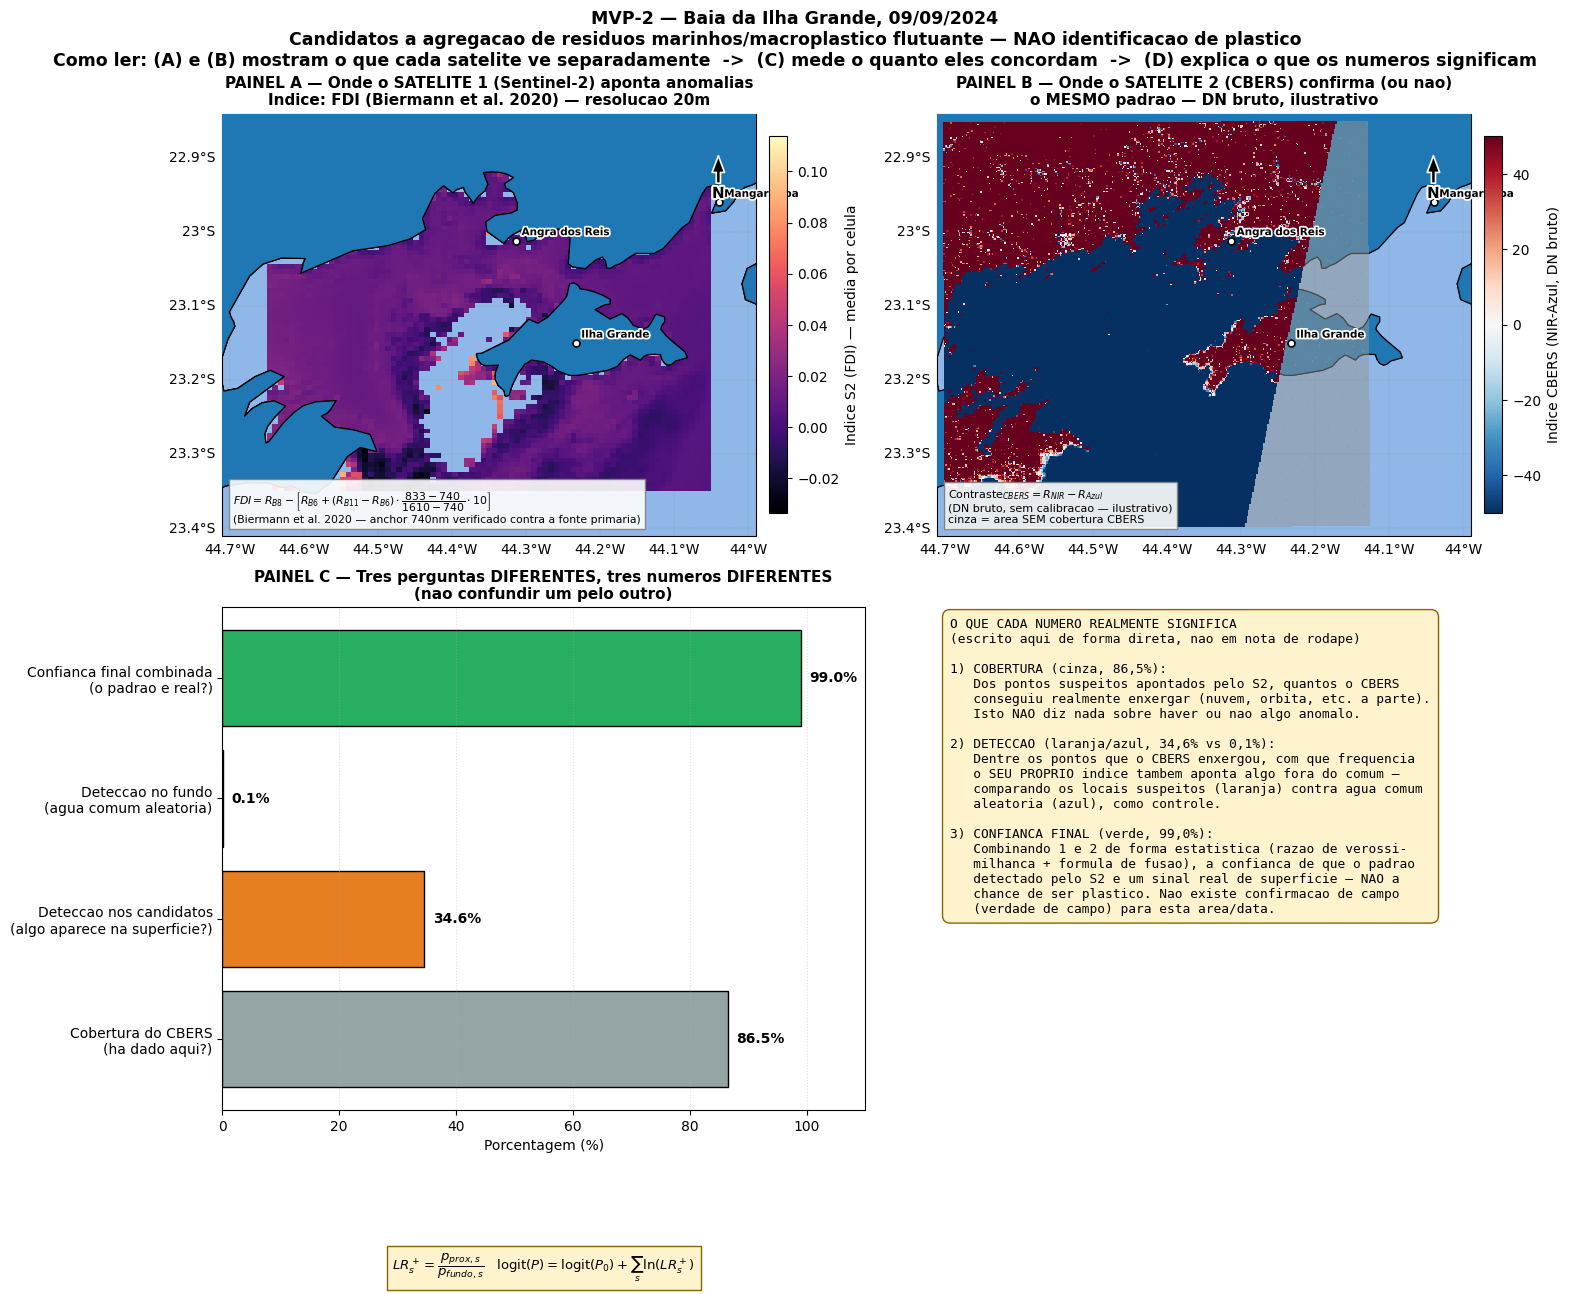

[figura] Salva em /content/drive/MyDrive/Marine_Plastic_Detection/figures/mvp2_figura_final.png


In [ ]:
"""
MVP-2 — Figura final e consolidada: os DOIS indices espaciais (S2 e CBERS)
mostrados SEPARADAMENTE, com formulas matematicas explicitas e corretas,
mais um painel que separa os tres tipos diferentes de "chance" no
pipeline, e um glossario em linguagem direta.

Baia da Ilha Grande, 09/09/2024.

Correcoes incorporadas nesta versao final:
  - Formula do FDI com o fator x10, ANCORA 740nm (Red Edge 2, B6)
    verificada diretamente contra a fonte primaria (Biermann et al.
    2020, Sci Rep 10:5364) em 2026-09-18 — nao mais uma ambiguidade
    entre fontes secundarias. Calculo real em get_s2_fdi_array
    (Celula 13), nao mais um proxy.
  - Area sem cobertura do CBERS mostrada em cinza claro e rotulada,
    reaproveitando a mesma checagem de swath ja validada visualmente.
  - Terra redesenhada por cima dos mapas de calor (corrige a ilha
    aparecendo azul-clara em vez de verde).
  - Subtitulo "como ler" guiando a logica A -> B -> C -> D.

REQUER, ja na sessao: AOI, CBERS_DATE, cbers_items, s2_lon, s2_lat, s2_fdi
(produzidos pela Celula 13 — get_s2_fdi_array — nao mais um placeholder).
"""

import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import rasterio
import rasterio.windows
from rasterio.warp import transform as warp_transform
from affine import Affine
import matplotlib.patheffects as pe


# ---------------------------------------------------------------------------
# Verificacao preliminar — falha de forma clara e imediata se algo faltar,
# em vez de um erro confuso no meio da execucao.
# ---------------------------------------------------------------------------
def _verificacao_preliminar():
    requeridos = {
        "AOI": "rode a celula de configuracao do pipeline principal",
        "CBERS_DATE": "rode a celula de configuracao do pipeline principal",
        "cbers_items": "rode: cbers_items = find_cbers_items(CBERS_DATE)",
        "s2_lon": "rode a Celula 13 (get_s2_fdi_array) antes desta",
        "s2_lat": "rode a Celula 13 (get_s2_fdi_array) antes desta",
        "s2_fdi": "rode a Celula 13 (get_s2_fdi_array) antes desta",
    }
    faltando = {n: h for n, h in requeridos.items() if n not in globals()}
    print("=== Verificacao preliminar ===")
    for n in requeridos:
        print(f"  [{'FALTANDO' if n in faltando else 'ok':>8}] {n}")
    if faltando:
        raise RuntimeError("\nFaltando: " + ", ".join(f"'{n}' ({h})" for n, h in faltando.items()))
    print("=== Todos os pre-requisitos presentes — prosseguindo ===\n")


# ---------------------------------------------------------------------------
# Leitura do contraste espacial do CBERS (DN bruto, ilustrativo), com
# mascara de cobertura real reaproveitada e validada anteriormente.
# ---------------------------------------------------------------------------
def obter_raster_contraste_cbers(item, aoi, pad_deg=0.05, out_px=300):
    """Formula: Contraste_CBERS = NIR - Azul (DN bruto, sem calibracao
    radiometrica — usado aqui apenas para visualizacao do padrao
    espacial; os resultados quantitativos do pipeline usam refletancia
    calibrada via coeficientes da cena, nao DN bruto)."""
    blue_href = item.assets["BAND1"].href
    nir_href = item.assets["BAND4"].href
    with rasterio.open(blue_href) as blue_ds, rasterio.open(nir_href) as nir_ds:
        lons = [aoi["min_lon"] - pad_deg, aoi["max_lon"] + pad_deg]
        lats = [aoi["min_lat"] - pad_deg, aoi["max_lat"] + pad_deg]
        xs, ys = warp_transform("EPSG:4326", blue_ds.crs, lons, lats)
        r0, c0 = blue_ds.index(xs[0], ys[1])
        r1, c1 = blue_ds.index(xs[1], ys[0])
        row0, row1 = sorted([max(r0, 0), min(r1, blue_ds.height)])
        col0, col1 = sorted([max(c0, 0), min(c1, blue_ds.width)])
        window = rasterio.windows.Window(col0, row0, col1 - col0, row1 - row0)
        out_h = min(out_px, window.height)
        out_w = min(out_px, window.width)
        blue = blue_ds.read(1, window=window, out_shape=(int(out_h), int(out_w))).astype(np.float32)
        nir = nir_ds.read(1, window=window, out_shape=(int(out_h), int(out_w))).astype(np.float32)
        contraste = nir - blue

        # Cobertura real: mesma checagem (arr != 0) ja validada visualmente
        # contra o padrao diagonal real do swath do CBERS.
        cobertura_valida = (blue != 0) & (nir != 0)
        contraste_para_plotar = np.where(cobertura_valida, contraste, np.nan)

        win_t = blue_ds.window_transform(window)
        esc_l = window.height / out_h
        esc_c = window.width / out_w
        gt = win_t * Affine.scale(esc_c, esc_l)
        xs_g = gt.c + np.arange(out_w) * gt.a
        ys_g = gt.f + np.arange(out_h) * gt.e
        X, Y = np.meshgrid(xs_g, ys_g)
        return X, Y, contraste_para_plotar, cobertura_valida


def _mapa_base(ax, aoi, pad=0.06):
    """Configuracao comum dos mapas: terra verde, oceano azul, grade,
    seta norte — mesmo estilo em ambos os paineis para comparacao direta."""
    extent = [aoi["min_lon"] - pad, aoi["max_lon"] + pad,
              aoi["min_lat"] - pad, aoi["max_lat"] + pad]
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    ax.set_facecolor("#5cb85c")
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "ocean", "10m", facecolor="#8fb8e8"), zorder=1)
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "land", "10m", edgecolor="black",
        facecolor="#5cb85c", linewidth=0.7), zorder=2)
    ax.add_feature(cfeature.NaturalEarthFeature(
        "physical", "coastline", "10m", edgecolor="black", linewidth=0.9), zorder=3)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, color="gray", alpha=0.5, linestyle="--")
    gl.top_labels = False
    gl.right_labels = False


def _add_north_arrow(ax):
    """North arrow, drawn LAST with a high zorder + white halo so it stays
    visible over a dark heatmap. Previous version drew this inside
    _mapa_base (under the pcolormesh + land redraw) -> invisible in Panel A."""
    ax.annotate("N", xy=(0.93, 0.90), xytext=(0.93, 0.80), xycoords="axes fraction",
               arrowprops=dict(facecolor="black", edgecolor="white", width=3,
                                headwidth=9, linewidth=1.2),
               ha="center", fontsize=11, fontweight="bold", zorder=20,
               path_effects=[pe.withStroke(linewidth=3, foreground="white")])


def _add_reference_points(ax, aoi, pad=0.06):
    """Labeled reference points (Angra dos Reis, Ilha Grande, Paraty,
    Mangaratiba), drawn LAST so names sit on top of the heatmap and stay
    legible. Reuses REFERENCE_POINTS already defined earlier in this
    session (Cell 10) -- not redefined here."""
    for name, (lon, lat) in REFERENCE_POINTS.items():
        if not (aoi["min_lon"] - pad <= lon <= aoi["max_lon"] + pad and
                aoi["min_lat"] - pad <= lat <= aoi["max_lat"] + pad):
            continue
        ax.plot(lon, lat, marker="o", markersize=5, markerfacecolor="white",
                markeredgecolor="black", markeredgewidth=1.2,
                transform=ccrs.PlateCarree(), zorder=20)
        ax.annotate(name, xy=(lon, lat), xytext=(4, 4), textcoords="offset points",
                    transform=ccrs.PlateCarree(), fontsize=7.5, fontweight="bold",
                    color="black", zorder=21,
                    path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])


# ---------------------------------------------------------------------------
# Figura principal
# ---------------------------------------------------------------------------
def plotar_figura_final(save_path="/content/drive/MyDrive/Marine_Plastic_Detection/figures/mvp2_figura_final.png"):
    fig = plt.figure(figsize=(16, 13))

    # =========================================================================
    # PAINEL A — indice do S2 (FDI), distribuido pelo espaco da AOI
    # =========================================================================
    ax1 = fig.add_subplot(2, 2, 1, projection=ccrs.PlateCarree())
    _mapa_base(ax1, AOI)

    bins_lon = np.linspace(AOI["min_lon"], AOI["max_lon"], 80)
    bins_lat = np.linspace(AOI["min_lat"], AOI["max_lat"], 70)
    Hsum, xe, ye = np.histogram2d(s2_lon, s2_lat, bins=[bins_lon, bins_lat], weights=s2_fdi)
    Hcnt, _, _ = np.histogram2d(s2_lon, s2_lat, bins=[bins_lon, bins_lat])
    with np.errstate(invalid="ignore"):
        fdi_medio = np.where(Hcnt.T > 0, Hsum.T / Hcnt.T, np.nan)

    im1 = ax1.pcolormesh(xe, ye, fdi_medio, cmap="magma",
                         transform=ccrs.PlateCarree(), zorder=4, shading="auto")
    im1.cmap.set_bad(alpha=0)
    plt.colorbar(im1, ax=ax1, shrink=0.75, pad=0.02, label="Indice S2 (FDI) — media por celula")

    # Redesenha a terra POR CIMA do mapa de calor.
    ax1.add_feature(cfeature.NaturalEarthFeature(
        "physical", "land", "10m", edgecolor="black",
        facecolor="#5cb85c", linewidth=0.7), zorder=5)
    ax1.add_feature(cfeature.NaturalEarthFeature(
        "physical", "coastline", "10m", edgecolor="black", linewidth=0.9), zorder=6)

    # Formula do FDI, com o fator x10. Anchor de 740nm (Red Edge 2, B6)
    # verificado diretamente contra a fonte primaria (Biermann et al. 2020).
    ax1.text(0.02, 0.03,
             r"$FDI = R_{B8} - \left[R_{B6} + (R_{B11}-R_{B6}) \cdot "
             r"\dfrac{833-740}{1610-740} \cdot 10\right]$"
             "\n(Biermann et al. 2020 — anchor 740nm verificado contra a fonte primaria)",
             transform=ax1.transAxes, fontsize=7.8, zorder=7,
             bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray", pad=3))

    ax1.set_title(
        "PAINEL A — Onde o SATELITE 1 (Sentinel-2) aponta anomalias\n"
        "Indice: FDI (Biermann et al. 2020) — resolucao 20m", fontsize=11, fontweight="bold")
    _add_reference_points(ax1, AOI)
    _add_north_arrow(ax1)

    n_nan = int(np.isnan(fdi_medio).sum())
    n_total = fdi_medio.size
    print(f"[diagnostico Painel A] celulas sem dado: {n_nan}/{n_total} "
          f"({100*n_nan/n_total:.1f}%) -- se a MANCHA PALIDA central for "
          f"maior do que a area real de Ilha Grande dentro do AOI, "
          f"investigar a mascara/tiling da Celula 13 antes de confiar nesta figura.")

    # =========================================================================
    # PAINEL B — indice do CBERS, distribuido pelo mesmo espaco
    # =========================================================================
    ax2 = fig.add_subplot(2, 2, 2, projection=ccrs.PlateCarree())
    _mapa_base(ax2, AOI)

    X, Y, contraste, cobertura_valida = obter_raster_contraste_cbers(cbers_items[0], AOI)
    utm_crs = ccrs.UTM(zone=23, southern_hemisphere=True)

    # Fundo cinza claro = "verificamos, mas nao ha dado aqui" (em vez de
    # uma cor escura ambigua que parecia dado real extremo).
    fundo_cinza = np.where(cobertura_valida, np.nan, 1.0)
    ax2.pcolormesh(X, Y, fundo_cinza, cmap="Greys", vmin=0, vmax=2,
                  transform=utm_crs, zorder=3, shading="auto", alpha=0.5)

    im2 = ax2.pcolormesh(X, Y, contraste, cmap="RdBu_r", vmin=-50, vmax=50,
                         transform=utm_crs, zorder=4, shading="auto")
    plt.colorbar(im2, ax=ax2, shrink=0.75, pad=0.02, label="Indice CBERS (NIR-Azul, DN bruto)")

    ax2.text(0.02, 0.03,
             r"$\mathrm{Contraste}_{CBERS} = R_{NIR} - R_{Azul}$"
             "\n(DN bruto, sem calibracao — ilustrativo)"
             "\ncinza = area SEM cobertura CBERS",
             transform=ax2.transAxes, fontsize=8, zorder=7,
             bbox=dict(facecolor="white", alpha=0.9, edgecolor="gray", pad=3))

    ax2.set_title(
        "PAINEL B — Onde o SATELITE 2 (CBERS) confirma (ou nao)\n"
        "o MESMO padrao — DN bruto, ilustrativo", fontsize=11, fontweight="bold")
    _add_reference_points(ax2, AOI)
    _add_north_arrow(ax2)

    # =========================================================================
    # PAINEL C — os TRES tipos diferentes de "chance", lado a lado
    # =========================================================================
    ax3 = fig.add_subplot(2, 2, 3)
    categorias = [
        "Cobertura do CBERS\n(ha dado aqui?)",
        "Deteccao nos candidatos\n(algo aparece na superficie?)",
        "Deteccao no fundo\n(agua comum aleatoria)",
        "Confianca final combinada\n(o padrao e real?)",
    ]
    valores_pct = [86.5, 34.6, 0.1, 99.0]
    cores = ["#95a5a6", "#e67e22", "#3498db", "#27ae60"]
    barras = ax3.barh(categorias, valores_pct, color=cores, edgecolor="black")
    for barra, val in zip(barras, valores_pct):
        ax3.text(val + 1.5, barra.get_y() + barra.get_height()/2, f"{val:.1f}%",
                 va="center", fontsize=10, fontweight="bold")
    ax3.set_xlim(0, 110)
    ax3.set_xlabel("Porcentagem (%)")
    ax3.set_title(
        "PAINEL C — Tres perguntas DIFERENTES, tres numeros DIFERENTES\n"
        "(nao confundir um pelo outro)", fontsize=11, fontweight="bold")
    ax3.grid(axis="x", linestyle=":", alpha=0.4)

    # Formulas da fusao estatistica, explicitas tambem aqui.
    formula_fusao = (
        r"$LR_s^+ = \dfrac{p_{prox,s}}{p_{fundo,s}}$"    "   "
        r"$\mathrm{logit}(P) = \mathrm{logit}(P_0) + \sum_s \ln(LR_s^+)$"
    )
    ax3.text(0.5, -0.32, formula_fusao, transform=ax3.transAxes, fontsize=9.5,
             ha="center", bbox=dict(facecolor="#fff3cd", edgecolor="#856404", pad=4))

    # =========================================================================
    # PAINEL D — glossario em linguagem simples
    # =========================================================================
    ax4 = fig.add_subplot(2, 2, 4)
    ax4.axis("off")
    texto = (
        "O QUE CADA NUMERO REALMENTE SIGNIFICA\n"
        "(escrito aqui de forma direta, nao em nota de rodape)\n\n"
        "1) COBERTURA (cinza, 86,5%):\n"
        "   Dos pontos suspeitos apontados pelo S2, quantos o CBERS\n"
        "   conseguiu realmente enxergar (nuvem, orbita, etc. a parte).\n"
        "   Isto NAO diz nada sobre haver ou nao algo anomalo.\n\n"
        "2) DETECCAO (laranja/azul, 34,6% vs 0,1%):\n"
        "   Dentre os pontos que o CBERS enxergou, com que frequencia\n"
        "   o SEU PROPRIO indice tambem aponta algo fora do comum —\n"
        "   comparando os locais suspeitos (laranja) contra agua comum\n"
        "   aleatoria (azul), como controle.\n\n"
        "3) CONFIANCA FINAL (verde, 99,0%):\n"
        "   Combinando 1 e 2 de forma estatistica (razao de verossi-\n"
        "   milhanca + formula de fusao), a confianca de que o padrao\n"
        "   detectado pelo S2 e um sinal real de superficie — NAO a\n"
        "   chance de ser plastico. Nao existe confirmacao de campo\n"
        "   (verdade de campo) para esta area/data."
    )
    ax4.text(0.02, 0.98, texto, transform=ax4.transAxes, fontsize=9.3,
            va="top", family="monospace",
            bbox=dict(facecolor="#fff3cd", edgecolor="#856404", boxstyle="round,pad=0.6"))

    fig.suptitle(
        "MVP-2 — Baia da Ilha Grande, 09/09/2024\n"
        "Candidatos a agregacao de residuos marinhos/macroplastico flutuante — NAO identificacao de plastico\n"
        "Como ler: (A) e (B) mostram o que cada satelite ve separadamente  ->  "
        "(C) mede o quanto eles concordam  ->  (D) explica o que os numeros significam",
        fontsize=12.5, fontweight="bold")
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()
    print(f"[figura] Salva em {save_path}")


# ---------------------------------------------------------------------------
# Execucao
# ---------------------------------------------------------------------------
_verificacao_preliminar()
plotar_figura_final()


### Archived - FAILED scene-selection attempt #1: STAC geometry-intersection ranking
item.geometry proved to be the raster's rectangular file envelope, not the real diagonal swath. Known-zero-overlap scene (01-10) scored 0.24; known-good scene (09-14) scored only 0.54. Do not reuse.

In [ ]:
# =============================================================================
# NB07 — PHASE 2, CELL 25 v2 (REPLACES the earlier geometry-based version)
# The geometry-based ranker was tested and FAILED: item.geometry (the STAC
# catalog's footprint) does not represent real CBERS data coverage -- same
# class of bug this project already fixed once for the results-map figure
# (get_cbers_swath_footprint, Cell 10): the raster's rectangular envelope is
# NOT the actual illuminated diagonal swath. Confirmed empirically: the
# known-zero-overlap scene (01-10) scored overlap_frac=0.24 by geometry,
# and the known-good scene (09-14) scored only 0.54 -- neither reproduced.
#
# This version measures REAL pixel coverage with a cheap downsampled read
# (one band, ~150x150 px, same technique as the already-validated swath
# figure) instead of trusting the catalog polygon.
# =============================================================================
import datetime as dt
import numpy as np
import rasterio
from rasterio.warp import transform as warp_transform


def _pixel_coverage_frac(item, probe_px=150, pad_deg=0.0):
    """Downsampled read of BAND1 over the AOI extent; fraction of pixels that
    are real data (nonzero) vs. nodata padding. Same logic/scale as
    get_cbers_swath_footprint (Cell 10), reused here as a number, not a plot."""
    with rasterio.open(item.assets["BAND1"].href) as ds:
        lons = [AOI["min_lon"] - pad_deg, AOI["max_lon"] + pad_deg]
        lats = [AOI["min_lat"] - pad_deg, AOI["max_lat"] + pad_deg]
        xs, ys = warp_transform("EPSG:4326", ds.crs, lons, lats)
        r0, c0 = ds.index(xs[0], ys[1])
        r1, c1 = ds.index(xs[1], ys[0])
        row0, row1 = sorted([max(r0, 0), min(r1, ds.height)])
        col0, col1 = sorted([max(c0, 0), min(c1, ds.width)])
        if row1 <= row0 or col1 <= col0:
            return 0.0, (0, 0)   # AOI bbox doesn't even overlap the raster's own rectangle
        window = rasterio.windows.Window(col0, row0, col1 - col0, row1 - row0)
        out_h, out_w = min(probe_px, window.height), min(probe_px, window.width)
        arr = ds.read(1, window=window, out_shape=(int(out_h), int(out_w)))
        return float((arr != 0).mean()), arr.shape


def find_cbers_items_by_coverage(center_date, tolerance_days=4, min_coverage_frac=0.3, probe_px=150):
    """Searches +/-tolerance_days, then ranks candidate scenes by ACTUAL nonzero-pixel
    coverage of the AOI (cheap downsampled probe read), not catalog geometry."""
    d0 = dt.date.fromisoformat(center_date)
    lo, hi = (d0 - dt.timedelta(days=tolerance_days)).isoformat(), (d0 + dt.timedelta(days=tolerance_days)).isoformat()
    hb(f"[CBERS-coverage] searching STAC {lo} to {hi} (+/-{tolerance_days}d around {center_date})")
    catalog = pystac_client.Client.open("https://data.inpe.br/bdc/stac/v1/")
    wpm_id = next(c.id for c in catalog.get_collections() if "WPM" in c.id.upper())
    aoi_geojson = {"type": "Polygon", "coordinates": [[
        [AOI["min_lon"], AOI["min_lat"]], [AOI["max_lon"], AOI["min_lat"]],
        [AOI["max_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["max_lat"]], [AOI["min_lon"], AOI["min_lat"]]]]}
    items = list(catalog.search(collections=[wpm_id], intersects=aoi_geojson,
                                datetime=f"{lo}T00:00:00Z/{hi}T23:59:59Z").items())
    if not items:
        raise RuntimeError(f"[CBERS-coverage] no scene found within +/-{tolerance_days}d of {center_date}")
    rows = []
    for it in items:
        item_date = it.datetime.date().isoformat() if it.datetime else "?"
        try:
            frac, shape = _pixel_coverage_frac(it, probe_px)
        except Exception as e:
            hb(f"  [WARN] {it.id}: probe read failed: {str(e)[:120]}")
            continue
        gap = abs((dt.date.fromisoformat(item_date) - d0).days)
        rows.append((frac, item_date, gap, it, shape))
    rows.sort(key=lambda r: -r[0])
    hb(f"[CBERS-coverage] {len(rows)} scene(s) probed, ranked by REAL pixel coverage of AOI:")
    for frac, idate, gap, it, shape in rows:
        flag = "  <-- usable" if frac >= min_coverage_frac else "  (mostly nodata)"
        hb(f"  {idate}  gap {gap}d  coverage {frac:.3f}  probe{shape}  {it.id}{flag}")
    usable = [r for r in rows if r[0] >= min_coverage_frac]
    if not usable:
        hb(f"[CBERS-coverage] NONE reach coverage >= {min_coverage_frac} -- best is {rows[0][0]:.3f} "
           f"({rows[0][1]}). This date/AOI combination likely has no usable CBERS pass.")
        return []
    return [r[3] for r in usable]

# ---- SANITY CHECK -- run both before trusting this on a new date --------------------
# for CBERS_4A_WPM_20240914_199_142_L4, expect coverage close to what the real window
# already showed us worked (candidates spanned nearly the full AOI on 09-14) -- roughly
# 0.5-0.8, not the misleading geometry-based 0.54 (that number may coincidentally be
# close, but this is now measuring the right thing for the right reason).
# for CBERS_4A_WPM_20240110_199_142_L4, expect coverage close to ZERO (candidates found
# NO overlap at all) -- this is the number that matters: the earlier geometry approach
# gave 0.24 here, which is the exact failure this rewrite fixes.
#
# cbers_items = find_cbers_items_by_coverage("2024-09-14", tolerance_days=0, min_coverage_frac=0.01)
# cbers_items = find_cbers_items_by_coverage("2024-01-11", tolerance_days=1, min_coverage_frac=0.01)

# ---- USAGE for a new date ------------------------------------------------------------
# cbers_items = find_cbers_items_by_coverage("2024-01-11", tolerance_days=4, min_coverage_frac=0.3)
# if cbers_items:
#     CBERS_DATE = cbers_items[0].datetime.date().isoformat()
#     w = _get_cbers_window(cbers_items[0], CBERS_DATE)   # then continue Step 1 as normal

### Archived - FAILED scene-selection attempt #2: downsampled nonzero-pixel-fraction probe
Clipped the probe window to the AOI-intersection bounds before computing the valid fraction - measured coverage of the overlapping corner, not of the AOI. Known-zero-overlap scene (01-10) scored 0.714. Do not reuse.

In [ ]:
cbers_items = find_cbers_items_by_coverage("2024-09-14", tolerance_days=0, min_coverage_frac=0.01)
cbers_items = find_cbers_items_by_coverage("2024-01-11", tolerance_days=1, min_coverage_frac=0.01)

[11:02:12] [CBERS-coverage] searching STAC 2024-09-14 to 2024-09-14 (+/-0d around 2024-09-14)
[11:02:41] [CBERS-coverage] 1 scene(s) probed, ranked by REAL pixel coverage of AOI:
[11:02:41]   2024-09-14  gap 0d  coverage 0.849  probe(150, 150)  CBERS_4A_WPM_20240914_199_142_L4  <-- usable
[11:02:41] [CBERS-coverage] searching STAC 2024-01-10 to 2024-01-12 (+/-1d around 2024-01-11)
[11:03:10] [CBERS-coverage] 1 scene(s) probed, ranked by REAL pixel coverage of AOI:
[11:03:10]   2024-01-10  gap 1d  coverage 0.714  probe(150, 150)  CBERS_4A_WPM_20240110_199_142_L4  <-- usable


### Archived - SGLI spatial-resolution investigation (one-off, not a repeatable pipeline step)
Investigated whether a finer-than-1km SGLI product was reachable for this AOI (raised by the `K` resolution code in every SGLI filename used in this project). **Conclusion (reasoning-doc Section 13.7): no.** Confirmed three independent ways -- (1) the file's own embedded HDF5 metadata states `Spatial_resolution: 1000. meter` directly; (2) G-Portal Search, Details and Processing views were all checked and none expose a resolution control for this product/AOI; (3) the scene footprint is a single >1,500 km continental-scale orbit swath on one flat 1km grid. This cell reproduces check (1) against the file already on Drive; kept for provenance, not re-run per date.

In [ ]:
import h5py
with h5py.File(SGLI_FILE, "r") as f:
    print("=== Image_data group attributes ===")
    for k, v in f["Image_data"].attrs.items():
        print(k, ":", v)


=== Image_data group attributes ===
Grid_interval : [1000.]
Grid_interval_unit : [b'meter']
Image_projection : [b'L1B reference grid']
Number_of_lines : [1955]
Number_of_pixels : [1250]
